# NLP Group Assignment 2025/26  
## Who Wants to Be a PoliMillionaire? Chatbot-Entertainment

### Group members
- Hedieh Raeisi — hedieh.raeisi@mail.polimi.it
- Ghazal Sepehrirad — ghazal.sepehrirad@mail.polimi.it
- Amin Sakhaei — amin.sakhaei@mail.polimi.it
- Amirhossein Sharifisadr — amirhossein.sharifisadr@mail.polimi.it

### Presentation video
https://drive.google.com/file/d/1bc3AZTQ2ZKWZBqGYMKiSXBdV_oviNDIR/view?usp=sharing

### Coding assistant statement
We used coding assistants to support debugging, code explanation, and notebook organisation.  
The final implementation, experiments, and analysis were understood and reviewed by all group members.

## 1. Introduction

The goal of this project is to build and evaluate a chatbot capable of playing the online quiz game **Who wants to be a PoliMillionaire?**.

The system receives a multiple-choice question, generates an answer using a local open-weight language model, and submits the selected option through the text game interface.

The investigation starts with a simple baseline and then compares prompt engineering, model size, model family, prompt ensembles, thinking vs non-thinking models, response timing, error categories, and confidence/overconfidence behaviour.


## 2. Environment and API Setup

This section installs the required packages, imports the necessary libraries, and initializes the game API client.

The notebook uses local open-weight models from Hugging Face. No external LLM API is used for answer generation.

In [ ]:
%pip uninstall -y numpy scipy scikit-learn pandas transformers huggingface_hub accelerate safetensors bitsandbytes sentencepiece

%pip install -q --no-cache-dir \
  "numpy==1.26.4" \
  "scipy==1.13.1" \
  "scikit-learn==1.5.2" \
  "pandas==2.2.2" \
  "transformers==4.53.2" \
  "huggingface_hub==0.33.4" \
  "accelerate==1.6.0" \
  "safetensors>=0.5.3" \
  "sentencepiece" \
  "bitsandbytes" \
  "sentence-transformers" \
  "faiss-cpu" \
  "requests" \
  "beautifulsoup4"

Found existing installation: numpy 2.0.2
Uninstalling numpy-2.0.2:
  Successfully uninstalled numpy-2.0.2
Found existing installation: scipy 1.16.3
Uninstalling scipy-1.16.3:
  Successfully uninstalled scipy-1.16.3
Found existing installation: scikit-learn 1.6.1
Uninstalling scikit-learn-1.6.1:
  Successfully uninstalled scikit-learn-1.6.1
Found existing installation: pandas 2.2.2
Uninstalling pandas-2.2.2:
  Successfully uninstalled pandas-2.2.2
Found existing installation: transformers 5.0.0
Uninstalling transformers-5.0.0:
  Successfully uninstalled transformers-5.0.0
Found existing installation: huggingface_hub 1.16.1
Uninstalling huggingface_hub-1.16.1:
  Successfully uninstalled huggingface_hub-1.16.1
Found existing installation: accelerate 1.13.0
Uninstalling accelerate-1.13.0:
  Successfully uninstalled accelerate-1.13.0
Found existing installation: safetensors 0.7.0
Uninstalling safetensors-0.7.0:
  Successfully uninstalled safetensors-0.7.0
Found existing installation: senten

In [ ]:
import os
import re
import gc
import sys
import json
import time
import math
import numpy
import scipy
import sklearn
import torch
import transformers
import getpass
import subprocess
from functools import lru_cache
from collections import Counter, defaultdict
from importlib.metadata import PackageNotFoundError, version
from google.colab import drive
import shutil
import importlib
import pandas as pd
import requests
import faiss
from bs4 import BeautifulSoup
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline



print("numpy:", numpy.__version__)
print("scipy:", scipy.__version__)
print("sklearn:", sklearn.__version__)
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)

numpy: 1.26.4
scipy: 1.13.1
sklearn: 1.5.2
torch: 2.11.0+cu128
transformers: 4.53.2


In [ ]:
REQUIRED_PACKAGE_VERSIONS = {
    "transformers": "4.53.2",
    "huggingface_hub": "0.33.4",
    "accelerate": "1.6.0",
}

INSTALL_PACKAGE_SPECS = [
    "transformers==4.53.2",
    "huggingface_hub==0.33.4",
    "accelerate==1.6.0",
    "safetensors>=0.5.3",
    "sentencepiece",
    "bitsandbytes",
]


def installed_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        return None


packages_to_fix = {
    package_name: installed_version(package_name)
    for package_name in REQUIRED_PACKAGE_VERSIONS
    if installed_version(package_name) != REQUIRED_PACKAGE_VERSIONS[package_name]
}

if packages_to_fix:
    print("Updating Hugging Face runtime packages:")

    for package_name, current_version in packages_to_fix.items():
        print(f"- {package_name}: {current_version} -> {REQUIRED_PACKAGE_VERSIONS[package_name]}")

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--upgrade",
            "--force-reinstall",
            "--no-cache-dir",
            *INSTALL_PACKAGE_SPECS,
        ]
    )

    raise RuntimeError(
        "Package versions were updated. Restart the Colab runtime, then rerun the notebook from the beginning."
    )

print("Hugging Face runtime package versions are compatible:")

for package_name in REQUIRED_PACKAGE_VERSIONS:
    print(f"- {package_name}: {installed_version(package_name)}")


Hugging Face runtime package versions are compatible:
- transformers: 4.53.2
- huggingface_hub: 0.33.4
- accelerate: 1.6.0


In [ ]:
drive.mount('/content/gdrive')

client_package_dir = "/content/gdrive/MyDrive/NLP/millionaire_client"

package_parent_dir = os.path.dirname(client_package_dir)

if package_parent_dir not in sys.path:
    sys.path.append(package_parent_dir)

print("Client package directory:")
print(client_package_dir)

print("\nPackage parent directory added to sys.path:")
print(package_parent_dir)

print("\nFiles inside client package:")
print(os.listdir(client_package_dir))

Mounted at /content/gdrive
Client package directory:
/content/gdrive/MyDrive/NLP/millionaire_client

Package parent directory added to sys.path:
/content/gdrive/MyDrive/NLP

Files inside client package:
['base.py', 'auth.py', 'models.py', 'competitions.py', 'game.py', 'leaderboard.py', 'client.py', 'exceptions.py', '__init__.py', '__pycache__']


In [ ]:
source_package_dir = "/content/gdrive/MyDrive/NLP/millionaire_client"
target_package_dir = "/content/millionaire_client"

if os.path.exists(target_package_dir):
    shutil.rmtree(target_package_dir)

shutil.copytree(source_package_dir, target_package_dir)

if "/content" not in sys.path:
    sys.path.insert(0, "/content")

importlib.invalidate_caches()

print("Copied package to:", target_package_dir)
print("Files inside local package:")
print(os.listdir(target_package_dir))
print("sys.path first items:")
print(sys.path[:5])

Copied package to: /content/millionaire_client
Files inside local package:
['base.py', 'auth.py', 'leaderboard.py', 'models.py', '__init__.py', 'competitions.py', 'exceptions.py', '__pycache__', 'game.py', 'client.py']
sys.path first items:
['/content', '/env/python', '/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload']


## 3. Game API and Authentication Setup

This section configures the connection to the game API and prepares the authentication values required to run the experiments.

Required secret values:

- `MILLIONAIRE_USERNAME`
- `MILLIONAIRE_PASSWORD`
- `HF_TOKEN`


In [ ]:
from millionaire_client import (
    MillionaireClient,
    AuthenticationError,
    GameError,
    TimeoutError,
    RateLimitError
)

print("millionaire_client imported successfully.")

millionaire_client imported successfully.


In [ ]:
API_URL = "http://131.175.15.22:51111/"

try:
    from google.colab import userdata
    username = userdata.get("MILLIONAIRE_USERNAME")
    password = userdata.get("MILLIONAIRE_PASSWORD")
except Exception:
    username = os.environ.get("MILLIONAIRE_USERNAME")
    password = os.environ.get("MILLIONAIRE_PASSWORD")

if not username:
    username = input("Millionaire username: ").strip()
if not password:
    password = getpass.getpass("Millionaire password: ")

client = MillionaireClient(API_URL)

try:
    user = client.login(username, password)
    print(f"Welcome {user.username}. You are now logged in.")
except AuthenticationError as e:
    raise RuntimeError(f"Login failed: {e}")


Welcome aminskh. You are now logged in.


In [ ]:
competitions = client.competitions.list_all()

print("Available competitions:")
for comp in competitions:
    print(f"{comp.id}: {comp.name} | max levels: {comp.max_levels} | questions: {comp.question_count}")

entertainment_comp = None
for comp in competitions:
    if "entertainment" in comp.name.lower():
        entertainment_comp = comp
        break

if entertainment_comp is None:
    comp_id = 0
    print("Entertainment competition not found automatically. Falling back to comp_id = 0.")
else:
    comp_id = entertainment_comp.id
    print("\nSelected Entertainment competition:")
    print("ID:", entertainment_comp.id)
    print("Name:", entertainment_comp.name)
    print("Max levels:", entertainment_comp.max_levels)
    print("Question count:", entertainment_comp.question_count)


Available competitions:
0: Entertainment | max levels: 15 | questions: 840
1: Ancient History and Politics | max levels: 15 | questions: 454
2: Science and Nature | max levels: 15 | questions: 5347
3: Maths | max levels: 15 | questions: 390
4: Philosophy and Psychology | max levels: 15 | questions: 3248
5: News | max levels: 15 | questions: 1860

Selected Entertainment competition:
ID: 0
Name: Entertainment
Max levels: 15
Question count: 840


## 4. Shared Utilities

This section defines reusable helper functions for model loading, prompt construction, answer generation, response parsing, result logging, confidence estimation, and result summarization.

Using shared utilities ensures that all models and prompts are evaluated under the same conditions.

In [ ]:
def clear_model_memory():
    for variable_name in ["model", "tokenizer", "generator"]:
        if variable_name in globals():
            del globals()[variable_name]
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_local_causal_lm(model_name_to_load, use_4bit=False):
    """Load a local/open-weight causal LM for the assignment."""
    global model_name, tokenizer, model, generator
    clear_model_memory()
    model_name = model_name_to_load
    print("Loading model:", model_name)

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    load_kwargs = {
        "device_map": "auto",
        "torch_dtype": torch.float16 if torch.cuda.is_available() else torch.float32,
    }
    if use_4bit:
        load_kwargs["load_in_4bit"] = True

    model = AutoModelForCausalLM.from_pretrained(model_name, **load_kwargs)
    generator = pipeline("text-generation", model=model, tokenizer=tokenizer)
    print("Loaded model:", model_name)
    return model, tokenizer, generator


In [ ]:
def clean_text(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()


def option_id_to_letter(index):
    return chr(ord("A") + int(index))


def parse_option_id(raw_response, question):
    """Robustly parse model output into one valid option id."""
    text = clean_text(raw_response)
    valid_ids = [option.id for option in question.options]
    valid_id_set = set(valid_ids)

    # 1) Exact or first-line numeric answer.
    first_line = text.split("\n")[0].strip()
    first_line_clean = re.sub(r"[^0-9A-Da-d]", " ", first_line).strip()
    if first_line_clean.isdigit():
        candidate = int(first_line_clean)
        if candidate in valid_id_set:
            return candidate

    # 2) Numeric patterns such as "Answer: 2" or "1,".
    for number in re.findall(r"\b\d+\b", text):
        candidate = int(number)
        if candidate in valid_id_set:
            return candidate

    # 3) Letter answers such as A/B/C/D.
    letter_to_position = {"A": 0, "B": 1, "C": 2, "D": 3}
    for letter in re.findall(r"\b[A-Da-d]\b", text):
        pos = letter_to_position[letter.upper()]
        if pos < len(question.options):
            return question.options[pos].id

    # 4) Textual option match.
    lower_text = text.lower()
    for option in question.options:
        option_text = clean_text(option.text).lower()
        if option_text and option_text in lower_text:
            return option.id

    return None


In [ ]:
def classify_error(row, high_confidence_threshold=0.70):
    raw = str(row.get("raw_response", "")).strip()
    selected_id = row.get("selected_option_id", None)

    # 1. Empty model output
    if raw == "":
        return "empty_response"

    # 2. Parser could not extract a valid option
    if pd.isna(selected_id):
        return "invalid_or_unparsed_output"

    # 3. Check whether the model violated the required output format
    raw_clean = raw.strip()
    is_only_number = raw_clean.isdigit()

    has_format_violation = False

    if not is_only_number:
        raw_lower = raw_clean.lower()
        if (
            "correct answer" in raw_lower
            or "explanation" in raw_lower
            or len(raw_clean.split()) > 3
            or "," in raw_clean
        ):
            has_format_violation = True

    # 4. Confidence-based error type
    confidence_score = pd.to_numeric(
        row.get("confidence_score", numpy.nan),
        errors="coerce"
    )

    if pd.notna(confidence_score) and confidence_score >= high_confidence_threshold:
        if has_format_violation:
            return "high_confidence_wrong_with_format_violation"
        return "high_confidence_wrong_answer"

    # 5. Format violation but not high-confidence
    if has_format_violation:
        return "wrong_option_with_format_violation"

    # 6. If correct answer column exists, classify wrong valid choice
    if "correct_option_id" in row.index and not pd.isna(row.get("correct_option_id")):
        if selected_id != row.get("correct_option_id"):
            return "wrong_option_selected"

    # 7. If correct_option_id is unavailable, but this row is already from df_errors
    return "wrong_option_selected"

In [ ]:
def option_token_ids(option_id):
    """
    Find possible single-token representations of an option ID.
    Example: "1", " 1", "\n1"
    """
    candidates = []

    for text_variant in [
        str(option_id),
        " " + str(option_id),
        "\n" + str(option_id),
    ]:
        token_ids = tokenizer.encode(
            text_variant,
            add_special_tokens=False
        )

        if len(token_ids) == 1:
            candidates.append(token_ids[0])

    return list(dict.fromkeys(candidates))


def estimate_option_confidences(prompt, valid_option_ids):
    """
    Estimate relative probabilities of valid option IDs using next-token logits.
    Returns a dict like:
    {0: 0.12, 1: 0.70, 2: 0.10, 3: 0.08}
    """
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model(**inputs)

    next_token_logits = outputs.logits[0, -1]

    option_ids = []
    option_scores = []

    for option_id in valid_option_ids:
        token_ids = option_token_ids(option_id)

        if not token_ids:
            continue

        # Combine possible token variants for the same option ID.
        score = torch.logsumexp(
            next_token_logits[token_ids],
            dim=0
        )

        option_ids.append(int(option_id))
        option_scores.append(score)

    if not option_scores:
        equal_probability = 1.0 / len(valid_option_ids)
        return {
            int(option_id): equal_probability
            for option_id in valid_option_ids
        }

    probabilities = torch.softmax(
        torch.stack(option_scores),
        dim=0
    ).detach().cpu().tolist()

    return {
        option_id: float(probability)
        for option_id, probability in zip(option_ids, probabilities)
    }


def confidence_from_option_probs(option_confidences, predicted_id):
    """
    Compute:
    - confidence_score: probability of selected option
    - confidence_margin: selected probability - best other probability
    """
    if predicted_id is None or not option_confidences:
        return numpy.nan, numpy.nan

    try:
        predicted_id = int(predicted_id)
    except Exception:
        return numpy.nan, numpy.nan

    confidence_score = float(option_confidences.get(predicted_id, 0.0))

    other_probs = [
        float(prob)
        for option_id, prob in option_confidences.items()
        if int(option_id) != predicted_id
    ]

    if other_probs:
        confidence_margin = confidence_score - max(other_probs)
    else:
        confidence_margin = confidence_score

    return confidence_score, confidence_margin

In [ ]:
def add_overconfidence_labels(df, high_threshold=0.70, low_threshold=0.40):
    df = df.copy()

    df["confidence_score"] = pd.to_numeric(
        df["confidence_score"],
        errors="coerce"
    )

    df["confidence_margin"] = pd.to_numeric(
        df["confidence_margin"],
        errors="coerce"
    )

    df["confidence_bucket"] = pd.cut(
        df["confidence_score"],
        bins=[-0.001, low_threshold, high_threshold, 1.0],
        labels=[
            f"low (<= {low_threshold:.2f})",
            f"medium ({low_threshold:.2f}-{high_threshold:.2f})",
            f"high (>= {high_threshold:.2f})",
        ],
    )

    df["overconfident_error"] = (
        (df["confidence_score"] >= high_threshold)
        & (df["correct"] == False)
    )

    df["uncertain_correct"] = (
        (df["confidence_score"] <= low_threshold)
        & (df["correct"] == True)
    )

    return df

## 5. Models Used

This project evaluates several open-weight local language models with different sizes, architectures, and instruction-following behaviours. All models were loaded locally through Hugging Face/Transformers and used without any paid LLM API. The purpose of selecting multiple models was to compare lightweight models, medium-sized instruction models, larger open-weight models, and reasoning-style distilled models under the same multiple-choice quiz setting.

### Qwen 2.5 1.5B Instruct

Qwen 2.5 1.5B Instruct is a small instruction-tuned model from the Qwen 2.5 family. Qwen models are decoder-only transformer language models designed for general text generation, instruction following, reasoning, multilingual tasks, coding, and mathematical tasks.

The 1.5B version was selected as a lightweight local model because it can run with low memory usage and fast inference. Its small parameter size makes it practical for repeated experiments in Colab, especially when testing many prompt variants.

### Qwen 2.5 3B Instruct

Qwen 2.5 3B Instruct is a larger model from the same Qwen 2.5 instruction-tuned family. It has more parameters than the 1.5B version, giving it more capacity while still remaining small enough to run locally in a notebook environment. This model was included to compare two models from the same family with different sizes. Since both Qwen 1.5B and Qwen 3B follow a similar instruction-tuned style, they provide a useful controlled comparison for studying the effect of increasing model size

### Phi-3.5 Mini Instruct

Phi-3.5 Mini Instruct is a compact instruction-tuned model from Microsoft’s Phi family. The Phi models are designed to be relatively small while still maintaining strong general language and reasoning capabilities. Phi-3 Mini models are known as efficient small language models intended for local or resource-constrained use cases.

Phi-3.5 Mini was included as a medium-sized model between the smaller Qwen models and the larger 7B/8B models. It was useful for testing whether a compact instruction model could handle multiple-choice Entertainment questions and retrieved external context.

### DeepSeek-R1-Distill-Qwen 1.5B

DeepSeek-R1-Distill-Qwen 1.5B is a distilled thinking-style model based on the Qwen 1.5B architecture. It belongs to the DeepSeek-R1 distilled model family, where smaller models are trained to imitate reasoning behaviours from larger reasoning models.

Unlike standard instruction-tuned models that usually answer directly, thinking-style models may generate intermediate reasoning or thinking traces before giving a final answer. Since the game requires only one numeric option ID, this model was tested with stricter prompting to encourage short, valid, and parseable outputs.

### Llama 3 8B Instruct

Llama 3 8B Instruct is an 8-billion-parameter instruction-tuned model from Meta’s Llama 3 family. Llama models are autoregressive decoder-only transformer models, and the Llama 3 family was released in 8B and 70B sizes. The instruct version is fine-tuned for chat-style and instruction-following tasks. This model was selected as a larger open-weight instruction model. It provides a comparison point against smaller models such as Qwen 1.5B, Qwen 3B, and Phi-3.5 Mini.

### Mistral 7B Instruct

Mistral 7B Instruct is a 7B-class instruction-tuned model from Mistral AI. Mistral 7B is a decoder-only transformer model designed to provide strong performance in a relatively compact 7B parameter size. The instruct version is adapted for chat and instruction-following tasks.

This model was included as another larger open-weight model, comparable in scale to Llama 3 8B but from a different model family. It was useful for comparing whether different 7B/8B-class instruction models behave differently under the same prompt, RAG, and multiple-choice constraints.

### Speech and ASR Model

For the speech-mode experiments, an automatic speech recognition model was used to convert audio questions and answer options into text before passing them to the language model. The ASR step creates a transcript of the spoken question and each spoken option.


## 6. Prompt Engineering Experiments

Before adding retrieval or external knowledge, several prompt strategies are tested using the same local model.

The goal is to test whether prompt design alone can improve answer accuracy, output validity, response time, and game progress.

### Zero-shot Prompt:
The zero-shot prompt is intentionally simple. It asks the model to answer the multiple-choice question and return only the numeric option ID. This gives a reference point for comparing more structured prompts.

### Short Entertainment Prompt:
The short prompt adds a small amount of task-specific context while keeping the instruction compact. This prompt is designed to reduce unnecessary generation and improve output format stability.

### Few-Shot Prompt:
The few-shot prompt provides examples of entertainment multiple-choice questions and their correct numeric answers. This tests whether demonstrations help the model follow the expected format and reasoning pattern.

### Elimination Prompt:
The elimination prompt asks the model to internally eliminate unlikely options before choosing an answer. The reasoning is not shown in the final output, since the game only accepts one numeric option ID.

In [ ]:
def format_options(question):
    return "\n".join([f"{option.id}. {option.text}" for option in question.options])


def valid_option_ids_text(question):
    return ", ".join(str(option.id) for option in question.options)

def build_prompt_zero_shot(question):
    return f"""
You are playing an entertainment multiple-choice quiz.
Choose the single best answer.

Question:
{question.text}

Options:
{format_options(question)}

Valid option IDs: {valid_option_ids_text(question)}

Return only one numeric option ID.
""".strip()


def build_prompt_short(question):
    return f"""
Answer this entertainment quiz question.
Pick the most likely correct option.
Return only the numeric option ID.

Question: {question.text}

Options:
{format_options(question)}

Valid option IDs: {valid_option_ids_text(question)}
Answer:
""".strip()

def build_prompt_few_shot(question):
    return f"""
You are answering entertainment multiple-choice questions.
Choose the single best answer.
Return only one numeric option ID.

Example 1:
Question: Who directed the film Titanic?
Options:
0. James Cameron
1. Steven Spielberg
2. Martin Scorsese
3. Christopher Nolan
Answer: 0

Example 2:
Question: Which artist released the album Thriller?
Options:
0. Prince
1. Michael Jackson
2. Madonna
3. David Bowie
Answer: 1

Now answer the real question.

Question:
{question.text}

Options:
{format_options(question)}

Valid option IDs: {valid_option_ids_text(question)}
Answer:
""".strip()

def build_prompt_elimination(question):
    return f"""
You are answering an entertainment multiple-choice question.
Internally eliminate wrong choices, but do not show reasoning.
Return only the numeric option ID.

Question:
{question.text}

Options:
{format_options(question)}

Valid option IDs: {valid_option_ids_text(question)}
Answer:
""".strip()

In [ ]:
def build_prompt_from_type(question, prompt_type="zero_shot", retrieved_facts=None):
    if prompt_type == "zero_shot":
        return build_prompt_zero_shot(question)
    if prompt_type == "short":
        return build_prompt_short(question)
    if prompt_type == "few_shot":
        return build_prompt_few_shot(question)
    if prompt_type == "elimination":
        return build_prompt_elimination(question)
    if prompt_type == "few_shot_antibias":
        return build_prompt_few_shot_antibias(question)
    if prompt_type in {"offline_rag", "online_rag", "hybrid_rag"}:
        return build_prompt_rag(question, retrieved_facts or [])
    if prompt_type == "speech_short":
        return build_prompt_speech_short(question)
    return build_prompt_zero_shot(question)


In [ ]:
experiment_log = []

def generate_answer(question, prompt_type="zero_shot", top_k=4, max_new_tokens=3):
    retrieved_facts = []
    rag_metadata = {}

    if prompt_type == "offline_rag":
        retrieved_facts = retrieve_facts(question, top_k=top_k)

    elif prompt_type == "online_rag":
        retrieved_facts = retrieve_facts_online(question, top_k=top_k)

    elif prompt_type == "hybrid_rag":
        retrieved_facts, rag_metadata = retrieve_hybrid_facts(question, top_k=top_k)

    prompt = build_prompt_from_type(
        question,
        prompt_type=prompt_type,
        retrieved_facts=retrieved_facts,
    )

    valid_option_ids = [option.id for option in question.options]

    start_time = time.time()

    option_confidences = estimate_option_confidences(
        prompt=prompt,
        valid_option_ids=valid_option_ids,
    )

    output = generator(
        prompt,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        return_full_text=False,
        use_cache=True,
        pad_token_id=tokenizer.eos_token_id,
    )

    response_time = time.time() - start_time

    raw_response = output[0]["generated_text"].strip()
    predicted_id = parse_option_id(raw_response, question)

    confidence_score, confidence_margin = confidence_from_option_probs(
        option_confidences=option_confidences,
        predicted_id=predicted_id,
    )

    retrieved_facts_text = "\n".join(
        clean_text(item.get("fact", ""))
        for item in retrieved_facts
    )

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
        "retrieved_facts": retrieved_facts,
        "retrieved_facts_text": retrieved_facts_text,
        "rag_metadata": rag_metadata,
        "option_confidences": option_confidences,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


def log_result(game, question, prediction, result, system_name, question_number):
    selected_option_text = None
    for option in question.options:
        if option.id == prediction["predicted_id"]:
            selected_option_text = option.text
            break

    row = {
        "system_name": system_name,
        "session_id": game.session_id,
        "level_before_answer": question_number,
        "api_question_level": question.level,
        "question_id": question.id,
        "question_text": question.text,
        "question_length": len(question.text.split()) if question.text else 0,
        "options": json.dumps([{"id": option.id, "text": option.text} for option in question.options]),
        "selected_option_id": prediction["predicted_id"],
        "selected_option_text": selected_option_text,
        "retrieved_facts_text": prediction.get("retrieved_facts_text", ""),
        "model_name": globals().get("model_name", "unknown"),
        "prompt_type": prediction["prompt_type"],
        "prompt": prediction["prompt"],
        "raw_response": prediction["raw_response"],
        "ensemble_mode": prediction.get("ensemble_mode", ""),
        "ensemble_decision_reason": prediction.get("ensemble_decision_reason", ""),
        "member_predictions": json.dumps(
            prediction.get("member_predictions", []),
            ensure_ascii=False
        ),
        "vote_scores": json.dumps(
            prediction.get("vote_scores", {}),
            ensure_ascii=False
        ),
        "option_confidences": json.dumps(prediction.get("option_confidences", {})),
        "confidence_score": prediction.get("confidence_score", numpy.nan),
        "confidence_margin": prediction.get("confidence_margin", numpy.nan),
        "valid_output": prediction.get("used_fallback", False) == False,
        "used_fallback": prediction.get("used_fallback", False),
        "response_time": prediction["response_time"],
        "under_30_seconds": prediction["response_time"] < 30,
        "correct": result.correct,
        "timed_out": result.timed_out,
        "game_over": result.game_over,
        "earned_amount": result.earned_amount,
        "rag_metadata": json.dumps(prediction.get("rag_metadata", {})),
        "retrieved_facts": json.dumps(prediction.get("retrieved_facts", [])),
        "ensemble_models": json.dumps(prediction.get("ensemble_models", [])),
        "voting_method": prediction.get("voting_method", ""),
        "model_predictions": json.dumps(prediction.get("model_predictions", []), default=str),
        "selected_model": prediction.get("selected_model", ""),
        "selected_prompt": prediction.get("selected_prompt", ""),
        "selected_confidence": prediction.get("selected_confidence", np.nan),
        "selected_weighted_confidence": prediction.get("selected_weighted_confidence", np.nan),
        "model_predictions": json.dumps(prediction.get("model_predictions", []), default=str),
    }
    experiment_log.append(row)


def play_prompt_game(comp_id, prompt_type="baseline", system_name="system", delay_seconds=1.5):
    game = client.game.start(competition_id=comp_id, mode="text")
    print("Started game session:", game.session_id)
    print("System:", system_name)

    question_number = 0

    while game.in_progress:
        question = game.current_question
        if question is None:
            print("No active question.")
            break
        if prompt_type == "selective_ensemble_cached":
            prediction = generate_selective_ensemble_answer(
                question=question,
                primary_conf_threshold=0.65,
                primary_margin_threshold=0.15,
                use_mistral_tiebreaker=False,
            )
        else:
            prediction = generate_answer(
                question=question,
                prompt_type=prompt_type,
                max_new_tokens=3,
            )


        selected_id = prediction["predicted_id"]
        used_fallback = False

        if selected_id is None:
            used_fallback = True
            selected_id = question.options[0].id
            prediction["predicted_id"] = selected_id

        prediction["used_fallback"] = used_fallback

        try:
            result = game.answer(selected_id)

            print(
                f"Level {question_number} | "
                f"api_level={question.level} | "
                f"submitted={selected_id} | "
                f"correct={result.correct} | "
                f"time={prediction['response_time']:.2f}s"
            )

            log_result(
                game,
                question,
                prediction,
                result,
                system_name=system_name,
                question_number=question_number,
            )

            if result.game_over:
                print("Game ended.")
                break

            question_number += 1
            time.sleep(delay_seconds)

        except TimeoutError as e:
            print("Timed out:", e)
            break
        except RateLimitError as e:
            print("Rate limited:", e)
            time.sleep(5)
        except GameError as e:
            print("Game error:", e)
            break

    return game


def benchmark_prompt(prompt_type, n_runs=3, delay_seconds=1.5, model_label="model"):
    all_runs = []
    for run_id in range(n_runs):
        print(f"Running model={model_label}, prompt={prompt_type}, run {run_id + 1}/{n_runs}")
        global experiment_log
        experiment_log = []
        system_name = f"{model_label}_{prompt_type}"
        play_prompt_game(
            comp_id=comp_id,
            prompt_type=prompt_type,
            system_name=system_name,
            delay_seconds=delay_seconds,
        )
        df_run = pd.DataFrame(experiment_log)
        df_run["run_id"] = run_id + 1
        df_run["prompt_type"] = prompt_type
        df_run["system_name"] = system_name
        df_run["model_label"] = model_label
        df_run["model_name"] = globals().get("model_name", "unknown")
        all_runs.append(df_run)
    return pd.concat(all_runs, ignore_index=True) if all_runs else pd.DataFrame()


def summarise_results(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()
    summary = df.groupby("system_name").agg(
        runs=("run_id", "nunique"),
        average_questions_reached=("question_id", "count"),
        average_final_earned_amount=("earned_amount", "mean"),
        best_final_earned_amount=("earned_amount", "max"),
        average_response_time=("response_time", "mean"),
        max_response_time=("response_time", "max"),
        valid_output_rate=("valid_output", "mean"),
    ).reset_index()
    # Convert total counts into per-run averages.
    summary["average_questions_reached"] = summary["average_questions_reached"] / summary["runs"]
    return summary.sort_values("average_questions_reached", ascending=False)


def make_error_table(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()
    errors = df[df["correct"] == False].copy()
    columns = [
        "system_name", "run_id", "level_before_answer", "question_text", "options",
        "raw_response", "selected_option_id", "selected_option_text", "retrieved_facts",
    ]
    return errors[[col for col in columns if col in errors.columns]]


### 6.1 Qwen 1.5B with 30 Output Tokens

This experiment evaluates Qwen 1.5B using the initial generation setting with a larger output token limit. It is used as a reference before reducing the output length.

In [ ]:
load_local_causal_lm("Qwen/Qwen2.5-1.5B-Instruct")

qwen_1_5b_results = []

for prompt_type in ["zero_shot", "short", "few_shot", "elimination"]:
    df_prompt = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=10,
        delay_seconds=1.5,
        model_label="qwen_1_5b",
        )
    qwen_1_5b_results.append(df_prompt)

Loading model: Qwen/Qwen2.5-1.5B-Instruct


Device set to use cuda:0


Loaded model: Qwen/Qwen2.5-1.5B-Instruct
Running model=qwen_1_5b, prompt=zero_shot, run 1/10


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 319696
System: qwen_1_5b_zero_shot
Level 0 | api_level=0 | submitted=0 | correct=True | time=1.13s


...

Level 0 | api_level=0 | submitted=2 | correct=False | time=1.39s
Game ended.
Running model=qwen_1_5b, prompt=elimination, run 9/10
Started game session: 319992
System: qwen_1_5b_elimination


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=0 | correct=False | time=1.52s
Game ended.
Running model=qwen_1_5b, prompt=elimination, run 10/10
Started game session: 319994
System: qwen_1_5b_elimination


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=0 | correct=False | time=1.08s
Game ended.


In [ ]:
df_qwen_1_5b = pd.concat(qwen_1_5b_results, ignore_index=True)
df_qwen_1_5b.to_csv("Ent_qwen_1_5b_30tkn.csv", index=False)

df_qwen_1_5b_summary = summarise_results(df_qwen_1_5b)
display(df_qwen_1_5b_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
3,qwen_1_5b_zero_shot,10,4.4,372.727273,1000,0.757455,1.483249,1.0
1,qwen_1_5b_few_shot,10,2.8,321.428571,2000,0.521742,1.372000,1.0
2,qwen_1_5b_short,10,2.8,457.142857,2000,0.499746,1.468663,1.0
0,qwen_1_5b_elimination,10,2.3,169.565217,500,0.719928,1.518178,1.0


#### 6.1.1 Error Analysis for Qwen 1.5B with 30 Tokens

This section inspects the errors made by Qwen 1.5B when using the larger output token limit.

With the 30-token setting, Qwen 1.5B frequently produced extra explanations instead of returning only a numeric option ID. Although the parser could often extract an answer, many raw responses still violated the required output format.

Overall, the 30-token setting gives the model too much room to generate unnecessary text. A shorter output limit is more suitable for this task because the expected response is only one numeric option ID.

In [ ]:
df_errors = df_qwen_1_5b[df_qwen_1_5b["correct"] == False].copy()

df_errors["confidence_score"] = pd.to_numeric(
    df_errors.get("confidence_score", numpy.nan),
    errors="coerce"
)

df_errors["confidence_margin"] = pd.to_numeric(
    df_errors.get("confidence_margin", numpy.nan),
    errors="coerce"
)

df_errors["error_type"] = df_errors.apply(classify_error, axis=1)

df_errors["overconfident_error"] = (
    df_errors["error_type"].isin([
        "high_confidence_wrong_answer",
        "high_confidence_wrong_with_format_violation"
    ])
)

cols = [
    "system_name",
    "level_before_answer",
    "question_text",
    "options",
    "raw_response",
    "selected_option_id",
    "selected_option_text",
    "confidence_score",
    "confidence_margin",
    "overconfident_error",
    "error_type",
]

existing_cols = [c for c in cols if c in df_errors.columns]

display(df_errors[existing_cols])

,system_name,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,confidence_score,confidence_margin,overconfident_error,error_type
4,qwen_1_5b_zero_shot,4,Which U2 album marked a significant change in ...,"[{""id"": 0, ""text"": ""Achtung Baby""}, {""id"": 1, ...",0\n\nThe correct answer is Achtung Baby. This ...,0,Achtung Baby,0.215332,-0.417480,False,wrong_option_with_format_violation
10,qwen_1_5b_zero_shot,5,Which of the following best describes the reas...,"[{""id"": 0, ""text"": ""She felt that her country ...",2,2,She was influenced by the success of pop artis...,0.048004,-0.829926,False,wrong_option_selected
15,qwen_1_5b_zero_shot,4,What term describes the late 1950s wild and bo...,"[{""id"": 0, ""text"": ""Swinging London""}, {""id"": ...",0\n\nThe correct answer is 0. Swinging London ...,0,Swinging London,0.018372,-0.839539,False,wrong_option_with_format_violation
20,qwen_1_5b_zero_shot,4,Which film role earned Denzel Washington his f...,"[{""id"": 0, ""text"": ""The Hurricane""}, {""id"": 1,...",3\n\nDenzel Washington's first Academy Award f...,3,Malcolm X,0.721191,0.536011,True,high_confidence_wrong_with_format_violation
22,qwen_1_5b_zero_shot,1,What event caused Forrest Gump to become a fas...,"[{""id"": 0, ""text"": ""Breaking his leg braces du...",3\n\nForrest Gump's journey from being a slow-...,3,A race against a classmate,0.918457,0.859741,True,high_confidence_wrong_with_format_violation
28,qwen_1_5b_zero_shot,5,What is the primary weakness of the symbiote i...,"[{""id"": 0, ""text"": ""Fire""}, {""id"": 1, ""text"": ...",1\n\nThe primary weakness of the symbiote in S...,1,Electrocution,0.130981,-0.683960,False,wrong_option_with_format_violation
29,qwen_1_5b_zero_shot,0,Which of the following best describes the term...,"[{""id"": 0, ""text"": ""A bandmate of the Beatles ...","3\n\nThe term ""fifth Beatle"" refers to Paul Mc...",3,A member of the Beatles who was fired,0.910156,0.856750,True,high_confidence_wrong_with_format_violation
34,qwen_1_5b_zero_shot,4,Which of the following films was NOT written o...,"[{""id"": 0, ""text"": ""True Romance""}, {""id"": 1, ...","3\n\nThe film ""Inception"" was not written or d...",3,Reservoir Dogs,0.831055,0.762817,True,high_confidence_wrong_with_format_violation
37,qwen_1_5b_zero_shot,2,What genre of music did Queen draw inspiration...,"[{""id"": 0, ""text"": ""Progressive rock""}, {""id"":...","1\n\nBrian May, the guitarist for Queen, drew ...",1,Glam rock,0.678711,0.534790,False,wrong_option_with_format_violation
43,qwen_1_5b_zero_shot,5,Which of the following best describes the reas...,"[{""id"": 0, ""text"": ""She was influenced by the ...",3,3,She wanted to explore new musical styles and c...,0.957031,0.933640,True,high_confidence_wrong_answer


### 6.2 Qwen 1.5B with 3 Output Tokens

Since the game only requires a numeric option ID, this experiment reduces `max_new_tokens` to 3 to test whether shorter generation improves speed and output validity.

In [ ]:
qwen_1_5b_results = []

for prompt_type in ["zero_shot", "short", "few_shot", "elimination"]:
    df_prompt = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=10,
        delay_seconds=1.5,
        model_label="qwen_1_5b",
        )
    qwen_1_5b_results.append(df_prompt)

Running model=qwen_1_5b, prompt=zero_shot, run 1/10


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 320846
System: qwen_1_5b_zero_shot
Level 0 | api_level=0 | submitted=1 | correct=False | time=0.17s
Game ended.
Running model=qwen_1_5b, prompt=zero_shot, run 2/10
Started game session: 320847
System: qwen_1_5b_zero_shot


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=3 | correct=True | time=0.15s


...

Level 0 | api_level=0 | submitted=3 | correct=True | time=0.23s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 1 | api_level=0 | submitted=3 | correct=False | time=0.17s
Game ended.
Running model=qwen_1_5b, prompt=elimination, run 10/10
Started game session: 320929
System: qwen_1_5b_elimination


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=1 | correct=False | time=0.16s
Game ended.


In [ ]:
df_qwen_1_5b = pd.concat(qwen_1_5b_results, ignore_index=True)
df_qwen_1_5b.to_csv("Ent_qwen_1_5b_3tkn.csv", index=False)

df_qwen_1_5b_summary = summarise_results(df_qwen_1_5b)

display(df_qwen_1_5b_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
1,qwen_1_5b_few_shot,10,4.5,12891.111111,128000,0.178292,0.237470,1.0
3,qwen_1_5b_zero_shot,10,4.2,2395.238095,16000,0.168254,0.239495,1.0
2,qwen_1_5b_short,10,4.1,3019.512195,32000,0.165879,0.234969,1.0
0,qwen_1_5b_elimination,10,3.1,332.258065,2000,0.167630,0.231590,1.0


### 6.2.1 Error Analysis for Qwen 1.5B with 3 Tokens

This section inspects wrong answers and output format problems for the initial Qwen 1.5B setting.

Reducing the output limit made Qwen 1.5B more suitable for the game format. The model produced fewer long explanations, and most outputs were closer to the required single numeric option ID.

However, the 3-token setting did not fully solve the problem. Some responses still contained small format violations such as commas or short text fragments, and many errors were still caused by selecting the wrong option.

Overall, using 3 tokens improved output control and reduced unnecessary generation, but it did not fully fix factual errors or high-confidence wrong predictions.

In [ ]:
df_errors = df_qwen_1_5b[df_qwen_1_5b["correct"] == False].copy()

df_errors["confidence_score"] = pd.to_numeric(
    df_errors.get("confidence_score", numpy.nan),
    errors="coerce"
)

df_errors["confidence_margin"] = pd.to_numeric(
    df_errors.get("confidence_margin", numpy.nan),
    errors="coerce"
)

df_errors["error_type"] = df_errors.apply(classify_error, axis=1)

df_errors["overconfident_error"] = (
    df_errors["error_type"].isin([
        "high_confidence_wrong_answer",
        "high_confidence_wrong_with_format_violation"
    ])
)

cols = [
    "system_name",
    "level_before_answer",
    "question_text",
    "options",
    "raw_response",
    "selected_option_id",
    "selected_option_text",
    "confidence_score",
    "confidence_margin",
    "overconfident_error",
    "error_type",
]

existing_cols = [c for c in cols if c in df_errors.columns]

display(df_errors[existing_cols])

,system_name,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,confidence_score,confidence_margin,overconfident_error,error_type
0,qwen_1_5b_zero_shot,0,"What is the fundamental principle of M3GAN, th...","[{""id"": 0, ""text"": ""It is built to teach child...",1,1,It is created to replace human caregivers,0.102478,-0.742249,False,wrong_option_selected
3,qwen_1_5b_zero_shot,2,What was the primary reason Michael Jackson's ...,"[{""id"": 0, ""text"": ""It included scenes of vand...",1,1,It was the first music video to feature a raci...,0.040161,-0.895874,False,wrong_option_selected
13,qwen_1_5b_zero_shot,9,How did Marlon Brando's behavior on the set of...,"[{""id"": 0, ""text"": ""It improved the actors' pe...",1,1,It led to a faster completion of the film.,0.043549,-0.872955,False,wrong_option_selected
17,qwen_1_5b_zero_shot,3,What is the primary reason Marlon Brando refus...,"[{""id"": 0, ""text"": ""He was protesting the trea...",1,1,He did not believe he deserved the award.,0.084839,-0.745239,False,wrong_option_selected
22,qwen_1_5b_zero_shot,4,What best describes Brad Pitt's early educatio...,"[{""id"": 0, ""text"": ""He left the University of ...",3,3,He dropped out of high school to focus on acting.,0.937988,0.911179,True,high_confidence_wrong_answer
23,qwen_1_5b_zero_shot,0,Which of the following albums by Bob Dylan is ...,"[{""id"": 0, ""text"": ""Blonde on Blonde""}, {""id"":...",2,2,The Freewheelin' Bob Dylan,0.085144,-0.691223,False,wrong_option_selected
24,qwen_1_5b_zero_shot,0,What is the primary reason Marlon Brando refus...,"[{""id"": 0, ""text"": ""He was boycotting the awar...",3,3,He did not believe he deserved the award.,0.954102,0.925507,True,high_confidence_wrong_answer
28,qwen_1_5b_zero_shot,3,Which director's influence can be seen in Spie...,"[{""id"": 0, ""text"": ""Ingmar Bergman""}, {""id"": 1...",1,1,Stanley Kubrick,0.498291,0.119141,False,wrong_option_selected
31,qwen_1_5b_zero_shot,2,What is the fundamental principle behind Beyon...,"[{""id"": 0, ""text"": ""To separate her stage pers...",3,3,To showcase her versatility as a performer.,0.958984,0.929108,True,high_confidence_wrong_answer
41,qwen_1_5b_zero_shot,9,What is the fundamental principle behind the B...,"[{""id"": 0, ""text"": ""A coordinated release of m...",3,3,A legal dispute between two film studios,0.946289,0.910431,True,high_confidence_wrong_answer


### 6.3 Positional Bias Check

This section checks whether the model tends to choose some option IDs more often than others when it makes mistakes.

As shown in the table, the strongest positional bias appears in the few-shot prompt. In this setting, 70% of the wrong answers were option 3, meaning that when the model made a mistake, it was heavily biased toward choosing the last option.

In [ ]:
df_wrong_option_rate = (
    df_errors
    .groupby(["system_name", "selected_option_id"])
    .size()
    .reset_index(name="wrong_count")
)

df_total_errors = (
    df_errors
    .groupby("system_name")
    .size()
    .reset_index(name="total_errors")
)

df_wrong_option_rate = df_wrong_option_rate.merge(df_total_errors, on="system_name")
df_wrong_option_rate["wrong_percentage"] = (
    df_wrong_option_rate["wrong_count"] / df_wrong_option_rate["total_errors"] * 100
).round(2)

display(df_wrong_option_rate.sort_values(["system_name", "wrong_percentage"], ascending=[True, False]))

,system_name,selected_option_id,wrong_count,total_errors,wrong_percentage
1,qwen_1_5b_elimination,1,4,10,40.0
2,qwen_1_5b_elimination,2,3,10,30.0
3,qwen_1_5b_elimination,3,2,10,20.0
0,qwen_1_5b_elimination,0,1,10,10.0
6,qwen_1_5b_few_shot,3,7,10,70.0
5,qwen_1_5b_few_shot,2,2,10,20.0
4,qwen_1_5b_few_shot,0,1,10,10.0
10,qwen_1_5b_short,3,5,10,50.0
8,qwen_1_5b_short,1,2,10,20.0
9,qwen_1_5b_short,2,2,10,20.0


### 6.4 Anti-Bias Prompt Experiment

This experiment adds explicit anti-bias instructions to the few-shot prompt to test whether positional preference can be reduced.

In [ ]:
def build_prompt_few_shot_antibias(question):
    return f"""
Answer entertainment multiple-choice questions.
Return only one numeric option ID.

Rules:
- Evaluate all options by meaning, not by position.
- Do not prefer option 0, 1, 2, or 3 because of order.
- Choose exactly one option.
- Do not explain.
- Do not output multiple IDs.

Example 1:
Question:
Who directed Titanic?
Options:
0. Steven Spielberg
1. James Cameron
2. Martin Scorsese
3. Christopher Nolan
Answer:
1

Example 2:
Question:
Which artist released Thriller?
Options:
0. Prince
1. Madonna
2. Michael Jackson
3. David Bowie
Answer:
2

Question:
{question.text}

Options:
{format_options(question)}

Valid option IDs: {valid_option_ids_text(question)}
Answer:
""".strip()

In [ ]:
df_few_shot_antibias = benchmark_prompt(
    prompt_type="few_shot_antibias",
    n_runs=10,
    delay_seconds=1.5,
    model_label="qwen_1_5b",
)

Running model=qwen_1_5b, prompt=few_shot_antibias, run 1/10


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 321013
System: qwen_1_5b_few_shot_antibias
Level 0 | api_level=0 | submitted=1 | correct=True | time=0.18s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 1 | api_level=0 | submitted=0 | correct=True | time=0.15s


...

Level 7 | api_level=0 | submitted=2 | correct=True | time=0.18s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 8 | api_level=0 | submitted=1 | correct=True | time=0.17s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 9 | api_level=0 | submitted=1 | correct=False | time=0.16s
Game ended.


In [ ]:
display(summarise_results(df_few_shot_antibias))

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
0,qwen_1_5b_few_shot_antibias,10,5.1,9098.039216,128000,0.168151,0.247657,1.0


In [ ]:
df_few_shot_antibias.to_csv("Ent_qwen_1_5b_antibias.csv", index=False)

#### Result Note

After using the anti-bias prompt, the strong bias toward option 3 was reduced. In the original few-shot setting, 70% of the wrong answers selected option 3, but after adding anti-bias instructions this dropped to 30%.

However, positional bias was not fully removed. The highest error concentration shifted to option 1, which represented 50% of the wrong answers. Therefore, the anti-bias prompt helped reduce the previous last-option bias, but it did not make the model's mistakes evenly distributed across all options.

In [ ]:
df_errors = df_few_shot_antibias[df_few_shot_antibias["correct"] == False].copy()
df_errors["error_type"] = df_errors.apply(classify_error, axis=1)

df_wrong_option_rate = (
    df_errors
    .groupby(["system_name", "selected_option_id"])
    .size()
    .reset_index(name="wrong_count")
)

df_total_errors = (
    df_errors
    .groupby("system_name")
    .size()
    .reset_index(name="total_errors")
)

df_wrong_option_rate = df_wrong_option_rate.merge(df_total_errors, on="system_name")
df_wrong_option_rate["wrong_percentage"] = (
    df_wrong_option_rate["wrong_count"] / df_wrong_option_rate["total_errors"] * 100
).round(2)

display(df_wrong_option_rate.sort_values(["system_name", "wrong_percentage"], ascending=[True, False]))

,system_name,selected_option_id,wrong_count,total_errors,wrong_percentage
0,qwen_1_5b_few_shot_antibias,1,5,10,50.0
2,qwen_1_5b_few_shot_antibias,3,3,10,30.0
1,qwen_1_5b_few_shot_antibias,2,2,10,20.0


## 7. Larger Qwen Model: Qwen 3B

This section evaluates Qwen 3B to test whether increasing the model size improves Entertainment quiz performance compared with Qwen 1.5B.

In [ ]:
load_local_causal_lm("Qwen/Qwen2.5-3B-Instruct")

qwen_3b_results = []
for prompt_type in ["zero_shot", "short", "few_shot", "elimination"]:
    df_prompt = benchmark_prompt(
            prompt_type=prompt_type,
            n_runs=10,
            delay_seconds=1.5,
            model_label="qwen_3b",
            )
    qwen_3b_results.append(df_prompt)

Loading model: Qwen/Qwen2.5-3B-Instruct


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Level 0 | api_level=0 | submitted=1 | correct=False | time=0.21s
Game ended.
Running model=qwen_3b, prompt=elimination, run 10/10
Started game session: 321501
System: qwen_3b_elimination


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=3 | correct=True | time=0.22s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 1 | api_level=0 | submitted=2 | correct=False | time=0.24s
Game ended.


In [ ]:
df_qwen_3b = pd.concat(qwen_3b_results, ignore_index=True)
df_qwen_3b.to_csv("Ent_qwen_3b.csv", index=False)


qwen_3b_normal_summary = summarise_results(df_qwen_3b)
display(qwen_3b_normal_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
1,qwen_3b_few_shot,10,4.9,8414.285714,128000,0.273722,0.364646,1.000000
0,qwen_3b_elimination,10,4.6,52939.130435,1024000,0.222860,0.305827,1.000000
3,qwen_3b_zero_shot,10,3.6,1508.333333,16000,0.238385,0.702543,1.000000
2,qwen_3b_short,10,2.6,1907.692308,16000,0.221631,0.292475,0.923077


In [ ]:
df_errors = df_qwen_3b[df_qwen_3b["correct"] == False].copy()

df_errors["confidence_score"] = pd.to_numeric(
    df_errors.get("confidence_score", numpy.nan),
    errors="coerce"
)

df_errors["confidence_margin"] = pd.to_numeric(
    df_errors.get("confidence_margin", numpy.nan),
    errors="coerce"
)

df_errors["error_type"] = df_errors.apply(classify_error, axis=1)

df_errors["overconfident_error"] = (
    df_errors["error_type"].isin([
        "high_confidence_wrong_answer",
        "high_confidence_wrong_with_format_violation"
    ])
)

cols = [
    "system_name",
    "level_before_answer",
    "question_text",
    "options",
    "raw_response",
    "selected_option_id",
    "selected_option_text",
    "confidence_score",
    "confidence_margin",
    "overconfident_error",
    "error_type",
]

existing_cols = [c for c in cols if c in df_errors.columns]

display(df_errors[existing_cols])

,system_name,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,confidence_score,confidence_margin,overconfident_error,error_type
0,qwen_3b_zero_shot,0,What is the fundamental principle of the blues...,"[{""id"": 0, ""text"": ""Complex rhythmic patterns""...",3,3,Harmonic dissonance,0.000536,-0.996046,False,wrong_option_selected
1,qwen_3b_zero_shot,0,How does the film 'The Shawshank Redemption' p...,"[{""id"": 0, ""text"": ""By Red's final speech""}, {...",0,0,By Red's final speech,0.999512,0.999107,True,high_confidence_wrong_answer
4,qwen_3b_zero_shot,2,For which role did Judi Dench win the Academy ...,"[{""id"": 0, ""text"": ""Iris in Iris""}, {""id"": 1, ...",2,2,Sally Bowles in Cabaret,0.446777,-0.063477,False,wrong_option_selected
7,qwen_3b_zero_shot,2,Which of the following awards did Judi Dench w...,"[{""id"": 0, ""text"": ""Oscar for Best Supporting ...",1,1,BAFTA for Best Actress,0.990723,0.986675,True,high_confidence_wrong_answer
10,qwen_3b_zero_shot,2,What term describes David Bowie's reinvention ...,"[{""id"": 0, ""text"": ""Glam rock""}, {""id"": 1, ""te...",3,3,Chameleon of rock,0.005379,-0.988274,False,wrong_option_selected
16,qwen_3b_zero_shot,5,Which event led to Aretha Franklin's first maj...,"[{""id"": 0, ""text"": ""Her father's gospel tours""...",3,3,Performing at the Apollo Theater,0.012115,-0.468109,False,wrong_option_selected
18,qwen_3b_zero_shot,1,What term describes the late 1950s wild and bo...,"[{""id"": 0, ""text"": ""Mod""}, {""id"": 1, ""text"": ""...",1,1,Swinging London,0.996582,0.993910,True,high_confidence_wrong_answer
21,qwen_3b_zero_shot,2,Which of the following best explains the signi...,"[{""id"": 0, ""text"": ""They allowed her to contro...",2,2,They showcased her improved songwriting skills,0.995605,0.991987,True,high_confidence_wrong_answer
25,qwen_3b_zero_shot,3,What was the primary reason for Jimmy Page to ...,"[{""id"": 0, ""text"": ""To join the band as a full...",3,3,To replace the band's original lead guitarist,0.975586,0.956268,True,high_confidence_wrong_answer
35,qwen_3b_zero_shot,9,What term best describes Ella Fitzgerald's imp...,"[{""id"": 0, ""text"": ""Melodic""}, {""id"": 1, ""text...",3,3,Rhythmic,0.993652,0.988773,True,high_confidence_wrong_answer


In [ ]:
df_wrong_option_rate = (
    df_errors
    .groupby(["system_name", "selected_option_id"])
    .size()
    .reset_index(name="wrong_count")
)

df_total_errors = (
    df_errors
    .groupby("system_name")
    .size()
    .reset_index(name="total_errors")
)

df_wrong_option_rate = df_wrong_option_rate.merge(df_total_errors, on="system_name")
df_wrong_option_rate["wrong_percentage"] = (
    df_wrong_option_rate["wrong_count"] / df_wrong_option_rate["total_errors"] * 100
).round(2)

display(df_wrong_option_rate.sort_values(["system_name", "wrong_percentage"], ascending=[True, False]))

,system_name,selected_option_id,wrong_count,total_errors,wrong_percentage
3,qwen_3b_elimination,3,4,9,44.44
1,qwen_3b_elimination,1,2,9,22.22
2,qwen_3b_elimination,2,2,9,22.22
0,qwen_3b_elimination,0,1,9,11.11
7,qwen_3b_few_shot,3,4,10,40.00
5,qwen_3b_few_shot,1,3,10,30.00
6,qwen_3b_few_shot,2,2,10,20.00
4,qwen_3b_few_shot,0,1,10,10.00
8,qwen_3b_short,0,4,10,40.00
9,qwen_3b_short,1,2,10,20.00


## 8. Retrieval-Augmented Generation

The error analysis from the previous experiments suggests that many wrong answers are related to missing or unreliable factual knowledge, rather than only to output formatting or instruction following. Since Entertainment questions often require specific knowledge about films, actors, musicians, albums, awards, and pop culture history, Retrieval-Augmented Generation (RAG) is introduced to provide the model with relevant supporting facts before answer selection.

In this notebook, three RAG configurations are evaluated: offline retrieval from a local Entertainment knowledge base, online retrieval from external sources, and a hybrid approach that combines both. The goal is to determine whether additional retrieved context improves answer accuracy, or whether noisy and irrelevant facts can sometimes confuse the model and reduce performance.

### 8.1 Offline Knowledge Sources

For the offline RAG setting, we built a local Entertainment knowledge base by collecting facts from structured sources such as Wikidata, IMDb, and MusicBrainz. The goal was to give the model access to relevant factual information while keeping retrieval fast, reproducible, and independent of live web access during the game.

In [ ]:
%pip install SPARQLWrapper pandas -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 18.4 MB/s eta 0:00:00


In [ ]:
from SPARQLWrapper import SPARQLWrapper, JSON
from urllib.error import HTTPError
from urllib.parse import quote
import time
import re
import requests
import pandas as pd
import glob

#### 8.1.1 Wikidata Fact Collection

In [ ]:
WIKIDATA_ENDPOINT = "https://query.wikidata.org/sparql"

def run_wikidata_query(query, sleep_seconds=1.5, max_retries=5):
    for attempt in range(max_retries):
        try:
            sparql = SPARQLWrapper(WIKIDATA_ENDPOINT)

            sparql.addCustomHttpHeader(
                "User-Agent",
                "EntertainmentRAGProject/1.0 (student project; contact: sakhaiea@gmail.com)"
            )

            sparql.setQuery(query)
            sparql.setReturnFormat(JSON)

            results = sparql.query().convert()

            time.sleep(sleep_seconds)

            return results["results"]["bindings"]

        except HTTPError as e:
            if e.code == 429:
                retry_after = e.headers.get("Retry-After")

                if retry_after is not None:
                    wait_time = int(retry_after)
                else:
                    wait_time = 1.5 * (attempt + 1)

                print(f"Rate limited by Wikidata. Waiting {wait_time} seconds...")
                time.sleep(wait_time)
            else:
                raise e

    print("Failed after too many retries.")
    return []

def get_movie_director_facts(limit=1000):
    query = f"""
    SELECT ?filmLabel ?directorLabel WHERE {{
      ?film wdt:P31 wd:Q11424.
      ?film wdt:P57 ?director.
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    LIMIT {limit}
    """

    rows = run_wikidata_query(query)
    facts = []

    for row in rows:
        facts.append({
            "fact": f"{row['filmLabel']['value']} was directed by {row['directorLabel']['value']}.",
            "source": "Wikidata",
            "category": "movie_director"
        })

    return pd.DataFrame(facts)


def get_movie_cast_facts(limit=1000):
    query = f"""
    SELECT ?filmLabel ?actorLabel WHERE {{
      ?film wdt:P31 wd:Q11424.
      ?film wdt:P161 ?actor.
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    LIMIT {limit}
    """

    rows = run_wikidata_query(query)
    facts = []

    for row in rows:
        facts.append({
            "fact": f"{row['filmLabel']['value']} stars {row['actorLabel']['value']}.",
            "source": "Wikidata",
            "category": "movie_cast"
        })

    return pd.DataFrame(facts)


def get_album_artist_facts(limit=1000):
    query = f"""
    SELECT ?albumLabel ?artistLabel WHERE {{
      ?album wdt:P31/wdt:P279* wd:Q482994.
      ?album wdt:P175 ?artist.
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    LIMIT {limit}
    """

    rows = run_wikidata_query(query)
    facts = []

    for row in rows:
        facts.append({
            "fact": f"{row['albumLabel']['value']} is an album by {row['artistLabel']['value']}.",
            "source": "Wikidata",
            "category": "album_artist"
        })

    return pd.DataFrame(facts)


def get_video_game_developer_facts(limit=1000):
    query = f"""
    SELECT ?gameLabel ?developerLabel WHERE {{
      ?game wdt:P31 wd:Q7889.
      ?game wdt:P178 ?developer.
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    LIMIT {limit}
    """

    rows = run_wikidata_query(query)
    facts = []

    for row in rows:
        facts.append({
            "fact": f"{row['gameLabel']['value']} was developed by {row['developerLabel']['value']}.",
            "source": "Wikidata",
            "category": "video_game_developer"
        })

    return pd.DataFrame(facts)

In [ ]:
all_dfs = []

print("Getting movie director facts...")
all_dfs.append(get_movie_director_facts(limit=1000))

print("Getting movie cast facts...")
all_dfs.append(get_movie_cast_facts(limit=1000))

print("Getting album artist facts...")
all_dfs.append(get_album_artist_facts(limit=1000))

print("Getting video game developer facts...")
all_dfs.append(get_video_game_developer_facts(limit=1000))

allfacts_df = pd.concat(all_dfs, ignore_index=True)

allfacts_df = allfacts_df.dropna(subset=["fact"])
allfacts_df["fact"] = allfacts_df["fact"].astype(str).str.strip()
allfacts_df = allfacts_df[allfacts_df["fact"].str.len() > 10]
allfacts_df = allfacts_df.drop_duplicates(subset=["fact"])

print("Saved entertainment_facts.csv")
print("Total facts:", len(allfacts_df))

allfacts_df.sample(10)

#### 8.1.2 IMDb Fact Collection

In [ ]:
!mkdir -p imdb_data

!wget -nc https://datasets.imdbws.com/title.basics.tsv.gz -P imdb_data
!wget -nc https://datasets.imdbws.com/title.crew.tsv.gz -P imdb_data
!wget -nc https://datasets.imdbws.com/name.basics.tsv.gz -P imdb_data
!wget -nc https://datasets.imdbws.com/title.principals.tsv.gz -P imdb_data

In [ ]:
titles = pd.read_csv("/content/imdb_data/title.basics.tsv.gz", sep="\t", na_values="\\N", low_memory=False)

crew = pd.read_csv("/content/imdb_data/title.crew.tsv.gz", sep="\t", na_values="\\N", low_memory=False)

names = pd.read_csv("/content/imdb_data/name.basics.tsv.gz", sep="\t", na_values="\\N", low_memory=False)

movies = titles[(titles["titleType"] == "movie") & (titles["primaryTitle"].notna()) & (titles["startYear"].notna())].copy()

movies["startYear"] = pd.to_numeric(movies["startYear"], errors="coerce")
movies = movies[movies["startYear"] >= 1900]

movies = movies[["tconst", "primaryTitle", "startYear"]]

crew = crew[["tconst", "directors"]].dropna()
crew["director_id"] = crew["directors"].str.split(",")
crew = crew.explode("director_id")

names_small = names[["nconst", "primaryName"]].dropna()

movie_directors = (
    movies
    .merge(crew, on="tconst", how="inner")
    .merge(names_small, left_on="director_id", right_on="nconst", how="inner")
)

imdb_facts = pd.DataFrame()
imdb_facts["fact"] = (
    movie_directors["primaryTitle"].astype(str) +
    " was directed by " +
    movie_directors["primaryName"].astype(str) +
    "."
)

imdb_facts["source"] = "IMDb"
imdb_facts["category"] = "movie_director"

imdb_facts = imdb_facts.drop_duplicates(subset=["fact"])

print("IMDb facts:", len(imdb_facts))
imdb_facts.head()

In [ ]:
allfacts_df = pd.concat([allfacts_df, imdb_facts], ignore_index=True)
allfacts_df = all_facts.drop_duplicates(subset=["fact"])

print("Total facts:", len(all_facts))
all_facts.sample(10)

#### 8.1.3 MusicBrainz Fact Collection

In [ ]:
MUSICBRAINZ_BASE_URL = "https://musicbrainz.org/ws/2"

HEADERS = {"User-Agent": "EntertainmentRAGProject/1.0 (student project; contact: sakhaiea@gmail.com)"}

REQUEST_DELAY = 1.1  # MusicBrainz: max about 1 request per second

In [ ]:
artist_names = [
    "Michael Jackson", "The Beatles", "Queen", "Led Zeppelin", "Prince",
    "Madonna", "Nirvana", "Pink Floyd", "David Bowie", "Elvis Presley",
    "ABBA", "The Rolling Stones", "Bob Dylan", "Whitney Houston",
    "Britney Spears", "Radiohead", "The Who", "The Doors", "Fleetwood Mac",
    "U2", "Aerosmith", "Bon Jovi", "Guns N' Roses", "Metallica", "AC/DC",
    "Black Sabbath", "The Beach Boys", "The Police", "R.E.M.",
    "Red Hot Chili Peppers", "Green Day", "Oasis", "Coldplay",
    "Foo Fighters", "Pearl Jam", "Linkin Park", "The Smiths",
    "Depeche Mode", "The Cure",

    "Taylor Swift", "Beyoncé", "Adele", "Lady Gaga", "Rihanna",
    "Katy Perry", "Bruno Mars", "Justin Bieber", "Ariana Grande",
    "Dua Lipa", "Billie Eilish", "Miley Cyrus", "Selena Gomez",
    "Ed Sheeran", "Harry Styles", "Shakira", "Jennifer Lopez",
    "Christina Aguilera", "Celine Dion", "Mariah Carey", "Janet Jackson",
    "George Michael", "Robbie Williams", "Sam Smith", "Olivia Rodrigo",
    "Lana Del Rey",

    "Eminem", "Tupac Shakur", "The Notorious B.I.G.", "Jay-Z",
    "Kanye West", "Drake", "Kendrick Lamar", "Nas", "Snoop Dogg",
    "Dr. Dre", "Ice Cube", "50 Cent", "Lil Wayne", "Nicki Minaj",
    "Cardi B", "Travis Scott", "Post Malone", "Missy Elliott",
    "Outkast", "Wu-Tang Clan", "Public Enemy", "N.W.A",

    "Aretha Franklin", "Stevie Wonder", "Marvin Gaye", "James Brown",
    "Ray Charles", "Diana Ross", "The Supremes", "The Temptations",
    "Otis Redding", "Al Green", "Lionel Richie", "Tina Turner",
    "Usher", "Alicia Keys", "Frank Ocean", "The Weeknd",

    "Johnny Cash", "Dolly Parton", "Willie Nelson", "Kenny Rogers",
    "Garth Brooks", "Shania Twain", "Carrie Underwood", "Luke Combs",
    "Kacey Musgraves", "Joni Mitchell", "Simon & Garfunkel",
    "Neil Young", "Leonard Cohen",

    "Daft Punk", "Calvin Harris", "Avicii", "David Guetta", "Skrillex",
    "The Chemical Brothers", "The Prodigy", "Kraftwerk", "Moby",
    "Deadmau5",

    "Bob Marley", "Ricky Martin", "Enrique Iglesias", "Bad Bunny",
    "J Balvin", "Daddy Yankee", "Rosalía", "Gloria Estefan",
    "BTS", "BLACKPINK",

    "Frank Sinatra", "Louis Armstrong", "Ella Fitzgerald", "Miles Davis",
    "John Coltrane", "Billie Holiday",
]

In [ ]:
def musicbrainz_get(endpoint, params=None, max_retries=5):
    url = f"{MUSICBRAINZ_BASE_URL}/{endpoint}"

    if params is None:
        params = {}

    params["fmt"] = "json"

    for attempt in range(max_retries):
        try:
            response = requests.get(url, params=params, headers=HEADERS, timeout=30)

            if response.status_code == 200:
                time.sleep(REQUEST_DELAY)
                return response.json()

            if response.status_code in [429, 503, 502, 504]:
                wait_time = REQUEST_DELAY * (attempt + 2)
                print(f"Temporary error {response.status_code}. Waiting {wait_time:.1f}s...")
                time.sleep(wait_time)
                continue

            print("Request failed:", response.status_code, response.text[:200])
            time.sleep(REQUEST_DELAY)
            return None

        except requests.exceptions.RequestException as e:
            wait_time = REQUEST_DELAY * (attempt + 2)
            print(f"Request exception: {e}. Waiting {wait_time:.1f}s...")
            time.sleep(wait_time)

    return None

def search_artist(artist_name):
    data = musicbrainz_get("artist", params={"query": f'artist:"{artist_name}"', "limit": 1})

    if not data:
        return None

    artists = data.get("artists", [])

    if len(artists) == 0:
        return None

    return artists[0]

def get_release_groups_for_artist(artist_id, limit=10):
    data = musicbrainz_get("release-group", params={"artist": artist_id, "type": "album", "limit": limit})

    if not data:
        return []

    return data.get("release-groups", [])

def get_recordings_for_artist(artist_id, limit=5):
    data = musicbrainz_get("recording", params={"artist": artist_id, "limit": limit})

    if not data:
        return []

    return data.get("recordings", [])

def build_musicbrainz_facts_for_artist(artist_name, album_limit=10, recording_limit=5):
    artist = search_artist(artist_name)

    if artist is None:
        print("Artist not found:", artist_name)
        return pd.DataFrame(columns=["fact", "source", "category"])

    artist_id = artist["id"]
    official_artist_name = artist.get("name", artist_name)

    facts = []

    if artist.get("country"):
        facts.append({
            "fact": f"{official_artist_name} is associated with the country {artist['country']}.",
            "source": "MusicBrainz",
            "category": "music_artist_country"
        })

    if artist.get("type"):
        facts.append({
            "fact": f"{official_artist_name} is a {artist['type'].lower()} music artist.",
            "source": "MusicBrainz",
            "category": "music_artist_type"
        })

    release_groups = get_release_groups_for_artist(
        artist_id,
        limit=album_limit
    )

    for rg in release_groups:
        title = rg.get("title")
        first_release_date = rg.get("first-release-date", "")

        if not title:
            continue

        facts.append({
            "fact": f"{title} is an album by {official_artist_name}.",
            "source": "MusicBrainz",
            "category": "album_artist"
        })

        if first_release_date:
            year = first_release_date[:4]

            if year.isdigit():
                facts.append({
                    "fact": f"{title} by {official_artist_name} was first released in {year}.",
                    "source": "MusicBrainz",
                    "category": "album_release_year"
                })

    recordings = get_recordings_for_artist(
        artist_id,
        limit=recording_limit
    )

    for rec in recordings:
        title = rec.get("title")

        if not title:
            continue

        facts.append({
            "fact": f"{title} is a recording by {official_artist_name}.",
            "source": "MusicBrainz",
            "category": "song_artist"
        })

    facts_df = pd.DataFrame(facts)
    facts_df = facts_df.dropna(subset=["fact"])
    facts_df["fact"] = facts_df["fact"].astype(str).str.strip()
    facts_df = facts_df[facts_df["fact"].str.len() > 15]
    facts_df = facts_df.drop_duplicates(subset=["fact"])

    return facts_df

def build_musicbrainz_dataset_in_batches(
    artist_names,
    batch_size=20,
    album_limit=10,
    recording_limit=5,
    output_dir="musicbrainz_batches"
):
    os.makedirs(output_dir, exist_ok=True)

    batch_files = []

    for start in range(0, len(artist_names), batch_size):
        end = min(start + batch_size, len(artist_names))
        batch_artists = artist_names[start:end]

        batch_number = start // batch_size + 1
        batch_path = os.path.join(
            output_dir,
            f"musicbrainz_batch_{batch_number}.csv"
        )

        if os.path.exists(batch_path):
            print(f"Batch {batch_number} already exists. Skipping.")
            batch_files.append(batch_path)
            continue

        print()
        print(f"Starting batch {batch_number}: artists {start} to {end - 1}")

        batch_dfs = []

        for artist_name in batch_artists:
            print("Getting:", artist_name)

            artist_df = build_musicbrainz_facts_for_artist(
                artist_name,
                album_limit=album_limit,
                recording_limit=recording_limit
            )

            if len(artist_df) > 0:
                batch_dfs.append(artist_df)

        if len(batch_dfs) > 0:
            batch_df = pd.concat(batch_dfs, ignore_index=True)
        else:
            batch_df = pd.DataFrame(columns=["fact", "source", "category"])

        batch_df = batch_df.dropna(subset=["fact"])
        batch_df["fact"] = batch_df["fact"].astype(str).str.strip()
        batch_df = batch_df[batch_df["fact"].str.len() > 15]
        batch_df = batch_df.drop_duplicates(subset=["fact"])

        batch_df.to_csv(batch_path, index=False)

        print(f"Saved {batch_path}")
        print("Facts in batch:", len(batch_df))

        batch_files.append(batch_path)

    return batch_files

In [ ]:
batch_files = build_musicbrainz_dataset_in_batches(
    artist_names=artist_names,
    batch_size=20,
    album_limit=10,
    recording_limit=5,
    output_dir="musicbrainz_batches"
)

print("Batch files created:", len(batch_files))
batch_files[:5]

In [ ]:
batch_files = sorted(glob.glob("musicbrainz_batches/musicbrainz_batch_*.csv"))

if len(batch_files) == 0:
    raise ValueError("No batch files found. Run build_musicbrainz_dataset_in_batches first.")

music_dfs = []

for file in batch_files:
    df = pd.read_csv(file)
    music_dfs.append(df)

musicbrainz_facts_df = pd.concat(music_dfs, ignore_index=True)

musicbrainz_facts_df = musicbrainz_facts_df.dropna(subset=["fact"])
musicbrainz_facts_df["fact"] = musicbrainz_facts_df["fact"].astype(str).str.strip()
musicbrainz_facts_df = musicbrainz_facts_df[musicbrainz_facts_df["fact"].str.len() > 15]
musicbrainz_facts_df = musicbrainz_facts_df.drop_duplicates(subset=["fact"])

musicbrainz_facts_df.to_csv("musicbrainz_facts.csv", index=False)

print("Saved musicbrainz_facts.csv")
print("Total MusicBrainz facts:", len(musicbrainz_facts_df))

musicbrainz_facts_df.sample(10)

#### 8.1.4 Combining Entertainment Knowledge Sources

In [ ]:
combined_df = pd.concat([allfacts_df, musicbrainz_facts_df], ignore_index=True)

combined_df = combined_df.dropna(subset=["fact"])
combined_df["fact"] = combined_df["fact"].astype(str).str.strip()
combined_df["source"] = combined_df["source"].fillna("unknown")
combined_df["category"] = combined_df["category"].fillna("unknown")

combined_df = combined_df[combined_df["fact"].str.len() > 15]
combined_df = combined_df.drop_duplicates(subset=["fact"])

combined_df.to_csv("entertainment.csv", index=False)
print("Final merged facts:", len(combined_df))

combined_df.sample(10)

For the offline RAG setting, the final knowledge base contained **615,729 entertainment facts**.

Collecting data from Wikidata and MusicBrainz was limited by source-side restrictions such as query limits, rate limits, and response-size limits. Because of these limitations, it was not practical to extract every possible entertainment fact from these sources.

### 8.2 Build and Inspect the Entertainment RAG Knowledge Base

Only after the normal Qwen baselines do we add RAG. This makes the notebook flow clearer for the investigation.


In [ ]:
OFFLINE_CSV_PATH = "/content/gdrive/MyDrive/NLP/entertainment.csv"
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
RAG_TOP_K = 5

FALLBACK_ENTERTAINMENT_FACTS = [
    "James Cameron directed the 1997 film Titanic.",
    "Michael Jackson released the album Thriller.",
    "Breaking Bad features the character Walter White.",
    "The Lord of the Rings film trilogy was directed by Peter Jackson.",
    "The Beatles were an English rock band formed in Liverpool.",
    "The Academy Awards are also known as the Oscars.",
]


def load_offline_facts(csv_path=OFFLINE_CSV_PATH):
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        if "fact" not in df.columns:
            text_cols = [c for c in df.columns if df[c].dtype == object]
            if not text_cols:
                raise ValueError("The offline RAG CSV needs a 'fact' column or at least one text column.")
            df["fact"] = df[text_cols].fillna("").astype(str).agg(" ".join, axis=1)
    else:
        print("Offline RAG CSV not found. Using a small fallback corpus for debugging.")
        df = pd.DataFrame({"fact": FALLBACK_ENTERTAINMENT_FACTS})

    df = df.dropna(subset=["fact"])
    df["fact"] = df["fact"].astype(str).str.strip()
    df = df[df["fact"].str.len() > 15]
    df = df.drop_duplicates(subset=["fact"]).reset_index(drop=True)
    return df


In [ ]:
facts_df = load_offline_facts()
knowledge_base = facts_df["fact"].tolist()

print("Knowledge base size:", len(knowledge_base))
display(facts_df.head(10))

Knowledge base size: 615729


,fact,source,category
0,We Live in Public was directed by Ondi Timoner.,Wikidata,movie_director
1,A Gang Story was directed by Olivier Marchal.,Wikidata,movie_director
2,The Intouchables was directed by Olivier Nakache.,Wikidata,movie_director
3,The Intouchables was directed by Éric Toledano.,Wikidata,movie_director
4,Swept Away was directed by Lina Wertmüller.,Wikidata,movie_director
5,Kick-Ass was directed by Matthew Vaughn.,Wikidata,movie_director
6,12 Angry Men was directed by Sidney Lumet.,Wikidata,movie_director
7,Gone with the Wind was directed by George Cukor.,Wikidata,movie_director
8,Gone with the Wind was directed by Victor Flem...,Wikidata,movie_director
9,Gone with the Wind was directed by Sam Wood.,Wikidata,movie_director


In [ ]:
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)
knowledge_embeddings = embedding_model.encode(
    knowledge_base,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True,
    )
dimension = knowledge_embeddings.shape[1]
rag_index = faiss.IndexFlatIP(dimension)
rag_index.add(knowledge_embeddings)

print("FAISS index size:", rag_index.ntotal)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/19242 [00:00<?, ?it/s]

FAISS index size: 615729


In [ ]:
def retrieve_facts(question, top_k=5):
    if "rag_index" not in globals() or len(globals().get("knowledge_base", [])) == 0:
        return []

    query_text = question.text + " " + " ".join([option.text for option in question.options])
    query_embedding = embedding_model.encode(
        [query_text],
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    scores, indices = rag_index.search(query_embedding, top_k)
    retrieved = []
    for score, idx in zip(scores[0], indices[0]):
        if idx < 0:
            continue
        retrieved.append({"fact": knowledge_base[idx], "score": float(score), "source": "offline_csv"})

    retrieved_facts_text = "\n".join(
    clean_text(item.get("fact", ""))
    for item in retrieved
    )
    return retrieved


### 8.3 Online RAG Sources


For the online RAG setting, we used **Wikipedia**, **Wikidata**, and **DBpedia** because they provide broad coverage of Entertainment-related topics such as films, actors, musicians, albums, awards, and pop-culture entities.

Wikipedia was selected for its rich natural-language descriptions, which are useful for questions that require context or explanation. Wikidata was used for structured factual relationships, such as directors, cast members, artists, albums, and release years. DBpedia was added because it provides structured information extracted from Wikipedia and can return concise entity-level facts.

MusicBrainz was removed from the online RAG pipeline because live requests to it frequently timed out and were not reliable enough under the 30-second game constraint. It was therefore more suitable as an offline data source than as a runtime online retriever.

Because earlier RAG experiments showed that noisy context can reduce performance, online retrieval is used carefully. The objective is to retrieve relevant supporting context, not simply to add more information to the prompt.


In [ ]:
TIMEOUT = 3.0
USER_AGENT = "PoliMillionaireEntertainmentRAG/1.0 (student project; contact: sakhaiea@gmail.com; raw content only)"
RAG_MIN_SCORE = 0.32

def build_online_query(question):
    # Keep the question as the main signal, but include short option texts for named entities.
    option_terms = []
    for option in question.options:
        text = clean_text(option.text)
        if 1 <= len(text.split()) <= 5:
            option_terms.append(text)
    return clean_text(question.text + " " + " ".join(option_terms))[:350]


@lru_cache(maxsize=256)
def wikipedia_search_titles(query, limit=3):
    url = "https://en.wikipedia.org/w/rest.php/v1/search/page"
    try:
        r = requests.get(
            url,
            headers={"User-Agent": USER_AGENT},
            params={"q": query, "limit": limit},
            timeout=TIMEOUT,
        )
        if r.status_code != 200:
            return []
        return [item.get("title") for item in r.json().get("pages", []) if item.get("title")]
    except Exception:
        return []


@lru_cache(maxsize=256)
def wikipedia_summary(title):
    try:
        url_title = title.replace(" ", "_")
        url = f"https://en.wikipedia.org/api/rest_v1/page/summary/{url_title}"
        r = requests.get(url, headers={"User-Agent": USER_AGENT}, timeout=TIMEOUT)
        if r.status_code != 200:
            return None
        data = r.json()
        extract = clean_text(data.get("extract", ""))
        if not extract:
            return None
        return {"fact": extract, "score": 0.55, "source": "wikipedia", "title": title}
    except Exception:
        return None


def retrieve_from_wikipedia(question, top_k=3):
    query = build_online_query(question)
    facts = []
    for title in wikipedia_search_titles(query, limit=top_k):
        item = wikipedia_summary(title)
        if item:
            facts.append(item)
    return facts[:top_k]


@lru_cache(maxsize=256)
def dbpedia_lookup_cached(query, limit=3):
    url = "https://lookup.dbpedia.org/api/search"
    headers = {"Accept": "application/json", "User-Agent": USER_AGENT}
    try:
        r = requests.get(url, headers=headers, params={"query": query, "maxResults": limit}, timeout=TIMEOUT)
        if r.status_code != 200:
            return []
        docs = r.json().get("docs", [])
        results = []
        for doc in docs:
            label = clean_text(" ".join(doc.get("label", [])))
            comment = clean_text(" ".join(doc.get("comment", [])))
            fact = clean_text(f"{label}: {comment}")
            if len(fact) > 30:
                results.append({"fact": fact, "score": 0.50, "source": "dbpedia", "title": label})
        return results
    except Exception:
        return []


def retrieve_from_dbpedia(question, top_k=3):
    return dbpedia_lookup_cached(build_online_query(question), limit=top_k)[:top_k]


@lru_cache(maxsize=256)
def wikidata_search_cached(query, limit=3):
    url = "https://www.wikidata.org/w/api.php"
    params = {
        "action": "wbsearchentities",
        "search": query,
        "language": "en",
        "format": "json",
        "limit": limit,
    }
    try:
        r = requests.get(url, headers={"User-Agent": USER_AGENT}, params=params, timeout=TIMEOUT)
        if r.status_code != 200:
            return []
        results = []
        for item in r.json().get("search", []):
            label = clean_text(item.get("label", ""))
            description = clean_text(item.get("description", ""))
            fact = clean_text(f"{label}: {description}")
            if len(fact) > 10:
                results.append({"fact": fact, "score": 0.45, "source": "wikidata", "title": label})
        return results
    except Exception:
        return []


def retrieve_from_wikidata(question, top_k=3):
    return wikidata_search_cached(build_online_query(question), limit=top_k)[:top_k]


def retrieve_facts_online(question, top_k=5):
    facts = []
    facts.extend(retrieve_from_wikipedia(question, top_k=2))
    facts.extend(retrieve_from_dbpedia(question, top_k=2))
    facts.extend(retrieve_from_wikidata(question, top_k=2))

    unique = []
    seen = set()
    for item in facts:
        fact = clean_text(item.get("fact", ""))
        key = fact.lower()[:180]
        if fact and key not in seen:
            seen.add(key)
            unique.append(item)
    return unique[:top_k]


def should_use_online_rag(question, offline_results=None):
    offline_results = offline_results or []
    best_offline = max([x.get("score", 0.0) for x in offline_results] or [0.0])
    text = clean_text(question.text).lower()
    exact_fact_terms = [
        "which year", "in which year", "released", "directed", "album", "song",
        "award", "oscar", "academy award", "first", "who played", "who wrote",
        "who directed", "created by", "starring", "single", "won",
    ]
    return best_offline < RAG_MIN_SCORE or any(term in text for term in exact_fact_terms)


def retrieve_hybrid_facts(question, top_k=5):
    offline_results = retrieve_facts(question, top_k=top_k)
    online_results = []
    if should_use_online_rag(question, offline_results):
        online_results = retrieve_facts_online(question, top_k=top_k)

    combined = offline_results + online_results
    combined = sorted(combined, key=lambda x: x.get("score", 0.0), reverse=True)

    unique = []
    seen = set()
    for item in combined:
        fact = clean_text(item.get("fact", ""))
        key = fact.lower()[:180]
        if fact and key not in seen:
            seen.add(key)
            unique.append(item)

    metadata = {
        "offline_count": len(offline_results),
        "online_count": len(online_results),
        "best_offline_score": max([x.get("score", 0.0) for x in offline_results] or [0.0]),
        "sources": sorted({x.get("source", "unknown") for x in unique}),
    }
    return unique[:top_k], metadata


### 8.4 RAG Prompting and Retrieval Filtering

A filtering step is applied before adding retrieved facts to the prompt. Since RAG can return noisy or weakly related facts, the retrieved results are ranked by word overlap with the question and answer options. Duplicate facts are removed, and only the most relevant facts are kept.

The RAG prompt then instructs the model to use the facts only if they directly help answer the question, and to ignore them if they are generic or unrelated. This reduces the risk of irrelevant context misleading the model.

In [ ]:
def build_prompt_rag(question, retrieved_facts):
    retrieved_facts = filter_retrieved_facts(
        question,
        retrieved_facts,
        max_facts=3
    )

    facts = []
    for item in retrieved_facts:
        fact = clean_text(item.get("fact", ""))
        if fact:
            facts.append(f"- {fact[:220]}")

    facts_text = "\n".join(facts)

    if not facts_text:
        facts_text = "No relevant facts available."

    return f"""
Answer the entertainment multiple-choice question.

Rules:
- Use facts only if they directly answer the question.
- If facts are generic or unrelated, ignore them.
- Compare all options by meaning.
- Choose exactly one option.
- Return only one numeric option ID.
- Do not explain.

Facts:
{facts_text}

Question:
{question.text}

Options:
{format_options(question)}

Valid option IDs: {valid_option_ids_text(question)}
Answer:
""".strip()

In [ ]:
def filter_retrieved_facts(question, retrieved_facts, max_facts=3):
    retrieved_facts = retrieved_facts or []

    query_text = " ".join([
        clean_text(question.text),
        " ".join(clean_text(option.text) for option in question.options)
    ]).lower()

    query_words = set(re.findall(r"[a-zA-Z0-9']+", query_text))

    important_words = {
        w for w in query_words
        if len(w) > 3
    }

    scored = []

    for item in retrieved_facts:
        fact = clean_text(item.get("fact", ""))
        if not fact:
            continue

        fact_words = set(re.findall(r"[a-zA-Z0-9']+", fact.lower()))
        overlap = len(important_words & fact_words)

        scored.append({
            **item,
            "fact": fact,
            "overlap_score": overlap,
        })

    scored = sorted(scored, key=lambda x: x["overlap_score"], reverse=True)

    filtered = []
    seen = set()

    for item in scored:
        fact_key = item["fact"].lower()
        if fact_key in seen:
            continue
        seen.add(fact_key)

        if item["overlap_score"] >= 2:
            filtered.append(item)

        if len(filtered) >= max_facts:
            break

    return filtered

### 8.5 Qwen 1.5B with RAG

This experiment evaluates whether offline, online, or hybrid RAG improves Qwen 1.5B performance.

In [ ]:
load_local_causal_lm("Qwen/Qwen2.5-1.5B-Instruct")

qwen_1_5b_rag_results = []

for prompt_type in ["offline_rag", "online_rag", "hybrid_rag"]:
    df_prompt = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=10,
        delay_seconds=1.5,
        model_label="qwen_1_5b",
    )
    qwen_1_5b_rag_results.append(df_prompt)

qwen_1_5b_rag_results = pd.concat(qwen_1_5b_rag_results, ignore_index=True)

Loading model: Qwen/Qwen2.5-1.5B-Instruct


Device set to use cuda:0


Loaded model: Qwen/Qwen2.5-1.5B-Instruct
Running model=qwen_1_5b, prompt=offline_rag, run 1/10
Started game session: 321194
System: qwen_1_5b_offline_rag


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=1 | correct=True | time=0.19s


...

Level 0 | api_level=0 | submitted=2 | correct=True | time=0.17s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 1 | api_level=0 | submitted=3 | correct=True | time=0.19s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 2 | api_level=0 | submitted=1 | correct=False | time=0.18s
Game ended.


#### Result Note

The RAG experiments did not improve the performance of Qwen 1.5B. In fact, all three RAG configurations performed worse than the best non-RAG prompt settings tested earlier.

The offline RAG version achieved the highest best final earned amount among the RAG settings, reaching 1000, while hybrid RAG only reached 200 and online RAG reached 500. This suggests that the local knowledge base occasionally helped, but not consistently enough to improve the average performance.

The main reason is likely retrieval noise. Some retrieved facts were too generic, weakly related, or mismatched with the question. Since the model is small, adding irrelevant context can confuse it instead of helping it. Therefore, in this experiment, RAG increased the amount of context but did not reliably improve answer selection.

Overall, RAG was not beneficial for Qwen 1.5B in this setup. The results suggest that retrieval quality is more important than simply adding external facts to the prompt.

In [ ]:
qwen_1_5b_rag_results.to_csv("Ent_qwen_1_5b_rag.csv", index=False)

qwen_1_5b_rag_summary = summarise_results(qwen_1_5b_rag_results)
display(qwen_1_5b_rag_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
0,qwen_1_5b_hybrid_rag,10,2.6,146.153846,200,0.180883,0.243886,1.0
1,qwen_1_5b_offline_rag,10,2.5,240.000000,1000,0.179414,0.239045,1.0
2,qwen_1_5b_online_rag,10,2.4,200.000000,500,0.196049,0.250711,1.0


In [ ]:
df_errors = qwen_1_5b_rag_results[qwen_1_5b_rag_results["correct"] == False].copy()

df_errors["confidence_score"] = pd.to_numeric(
    df_errors.get("confidence_score", numpy.nan),
    errors="coerce"
)

df_errors["confidence_margin"] = pd.to_numeric(
    df_errors.get("confidence_margin", numpy.nan),
    errors="coerce"
)

df_errors["error_type"] = df_errors.apply(classify_error, axis=1)

df_errors["overconfident_error"] = (
    df_errors["error_type"].isin([
        "high_confidence_wrong_answer",
        "high_confidence_wrong_with_format_violation"
    ])
)

cols = [
    "system_name",
    "level_before_answer",
    "question_text",
    "options",
    "raw_response",
    "selected_option_id",
    "selected_option_text",
    "retrieved_facts_text",
    "confidence_score",
    "retrieved_facts_text",
]

existing_cols = [c for c in cols if c in df_errors.columns]

display(df_errors[existing_cols])

,system_name,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,retrieved_facts_text,confidence_score,retrieved_facts_text
2,qwen_1_5b_offline_rag,2,What event marked the beginning of Ella Fitzge...,"[{""id"": 0, ""text"": ""Taking over the Chick Webb...",1,1,Her solo performance at the Roseland Ballroom,Ella Fitzgerald is a person music artist.\nEll...,0.962402,Ella Fitzgerald is a person music artist.\nEll...
4,qwen_1_5b_offline_rag,1,What was the primary reason for Jimmy Page to ...,"[{""id"": 0, ""text"": ""To improve the band's over...",3,3,To join the band as a full-time lead guitarist,Yardbirds was directed by Martin G. Baker.\nTh...,0.884277,Yardbirds was directed by Martin G. Baker.\nTh...
5,qwen_1_5b_offline_rag,0,How did the band's lyrical themes evolve from ...,"[{""id"": 0, ""text"": ""From religious to secular""...",3,3,From upbeat to downbeat,Music for the Masses is an album by Depeche Mo...,0.478760,Music for the Masses is an album by Depeche Mo...
6,qwen_1_5b_offline_rag,0,How does the film 'The Shawshank Redemption' p...,"[{""id"": 0, ""text"": ""Through the prison's harsh...",2,2,By Red's final speech,The Shawshank Redemption was directed by Frank...,0.902832,The Shawshank Redemption was directed by Frank...
8,qwen_1_5b_offline_rag,1,What term describes the nickname Buster Keaton...,"[{""id"": 0, ""text"": ""Buster""}, {""id"": 1, ""text""...",2,2,The Great Stone Face,Buster Keaton: The Great Stone Face was direct...,0.755371,Buster Keaton: The Great Stone Face was direct...
9,qwen_1_5b_offline_rag,0,Which of the following albums marked Stevie Wo...,"[{""id"": 0, ""text"": ""Music of My Mind""}, {""id"":...",3,3,Songs in the Key of Life,Stevie Wonder is a person music artist.\nStevi...,0.994629,Stevie Wonder is a person music artist.\nStevi...
14,qwen_1_5b_offline_rag,4,Which of the following best describes the rela...,"[{""id"": 0, ""text"": ""Kahn has edited all of Spi...",3,3,Kahn has worked on more of Spielberg's films t...,SHEP SPIELBERG the Other Spielberg was directe...,0.801758,SHEP SPIELBERG the Other Spielberg was directe...
20,qwen_1_5b_offline_rag,5,What term describes Mariah Carey's transition ...,"[{""id"": 0, ""text"": ""Genre expansion""}, {""id"": ...",2.,2,Sound evolution,Mariah Carey is a person music artist.\nMariah...,0.933594,Mariah Carey is a person music artist.\nMariah...
22,qwen_1_5b_offline_rag,1,What is the primary reason Joey Tribbiani purs...,"[{""id"": 0, ""text"": ""To escape his father's pro...",2.,2,To follow in his father's footsteps,Joey was directed by Joseph Ellison.\nJoey was...,0.185303,Joey was directed by Joseph Ellison.\nJoey was...
24,qwen_1_5b_offline_rag,1,What was the fundamental principle behind Paul...,"[{""id"": 0, ""text"": ""Relying on formal musical ...","0,",0,Relying on formal musical training,Paul McCartney: In Performance was directed by...,0.437500,Paul McCartney: In Performance was directed by...


### 8.6 Qwen 3B with RAG

This section evaluates whether RAG helps the larger Qwen 3B model.

In [ ]:
load_local_causal_lm("Qwen/Qwen2.5-3B-Instruct")

qwen_3b_rag_results = []

for prompt_type in ["offline_rag", "online_rag", "hybrid_rag"]:
    df_prompt = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=10,
        delay_seconds=1.5,
        model_label="qwen_3b",
    )
    qwen_3b_rag_results.append(df_prompt)


Loading model: Qwen/Qwen2.5-3B-Instruct


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Device set to use cuda:0


Loaded model: Qwen/Qwen2.5-3B-Instruct
Running model=qwen_3b, prompt=offline_rag, run 1/10
Started game session: 321626
System: qwen_3b_offline_rag


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

Level 1 | api_level=0 | submitted=0 | correct=True | time=0.26s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 2 | api_level=0 | submitted=3 | correct=True | time=0.28s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 3 | api_level=0 | submitted=1 | correct=False | time=0.31s
Game ended.


In [ ]:
qwen_3b_rag_results = pd.concat(qwen_3b_rag_results, ignore_index=True)
qwen_3b_rag_results.to_csv("Ent_qwen_3b_rag.csv", index=False)

#### Result Note

RAG did not improve Qwen 3B performance. Offline RAG was the best RAG variant, reaching 4.5 questions on average and a best final amount of 32,000, but this was still lower than the strongest non-RAG Qwen 3B results.

In [ ]:
qwen_3b_rag_summary = summarise_results(qwen_3b_rag_results)
display(qwen_3b_rag_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
1,qwen_3b_offline_rag,10,4.5,2446.666667,32000,0.271814,0.357911,1.0
0,qwen_3b_hybrid_rag,10,3.1,841.935484,4000,0.283808,0.346250,1.0
2,qwen_3b_online_rag,10,3.0,310.000000,1000,0.304480,0.369699,1.0


In [ ]:
df_errors = qwen_3b_rag_results[qwen_3b_rag_results["correct"] == False].copy()

df_errors["confidence_score"] = pd.to_numeric(
    df_errors.get("confidence_score", numpy.nan),
    errors="coerce"
)

df_errors["confidence_margin"] = pd.to_numeric(
    df_errors.get("confidence_margin", numpy.nan),
    errors="coerce"
)

df_errors["error_type"] = df_errors.apply(classify_error, axis=1)

df_errors["overconfident_error"] = (
    df_errors["error_type"].isin([
        "high_confidence_wrong_answer",
        "high_confidence_wrong_with_format_violation"
    ])
)

cols = [
    "system_name",
    "level_before_answer",
    "question_text",
    "options",
    "raw_response",
    "selected_option_id",
    "selected_option_text",
    "retrieved_facts_text",
    "confidence_score",
    "retrieved_facts_text",
]

existing_cols = [c for c in cols if c in df_errors.columns]

display(df_errors[existing_cols])

,system_name,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,retrieved_facts_text,confidence_score,retrieved_facts_text
6,qwen_3b_offline_rag,6,"In the mid-1980s, which producer significantly...","[{""id"": 0, ""text"": ""Brian Eno""}, {""id"": 1, ""te...",2,2,Daniel Lanois,U2 is a group music artist.\nU2: Rattle and Hu...,1.000000,U2 is a group music artist.\nU2: Rattle and Hu...
17,qwen_3b_offline_rag,10,What is the primary reason for the extensive u...,"[{""id"": 0, ""text"": ""To create a more realistic...",1,1,To enhance the dramatic intensity of the film,Gone with the wind was directed by Serge Azary...,0.928711,Gone with the wind was directed by Serge Azary...
20,qwen_3b_offline_rag,2,Which of the following was Whitney Houston's f...,"[{""id"": 0, ""text"": ""How Will I Know""}, {""id"": ...",3,3,I Will Always Love You,Whitney Houston: We Will Always Love You was d...,0.996582,Whitney Houston: We Will Always Love You was d...
25,qwen_3b_offline_rag,4,In which U.S. state was the film 'The Shawshan...,"[{""id"": 0, ""text"": ""California""}, {""id"": 1, ""t...",3,3,New York,The Shawshank Redemption was directed by Frank...,0.999512,The Shawshank Redemption was directed by Frank...
26,qwen_3b_offline_rag,0,Which of Mariah Carey's albums is known for in...,"[{""id"": 0, ""text"": ""Daydream""}, {""id"": 1, ""tex...",0,0,Daydream,Emotions is an album by Mariah Carey.\nDaydrea...,0.995117,Emotions is an album by Mariah Carey.\nDaydrea...
31,qwen_3b_offline_rag,4,"What was Whitney Houston's debut album, which ...","[{""id"": 0, ""text"": ""I'm Your Baby Tonight""}, {...",0,0,I'm Your Baby Tonight,I’m Your Baby Tonight is an album by Whitney H...,0.965332,I’m Your Baby Tonight is an album by Whitney H...
35,qwen_3b_offline_rag,3,Who is considered by Paul McCartney to be the ...,"[{""id"": 0, ""text"": ""George Martin""}, {""id"": 1,...",1,1,Ringo Starr,The Beatles is a group music artist.\nWith The...,0.966797,The Beatles is a group music artist.\nWith The...
36,qwen_3b_offline_rag,0,Which of the following best describes Thanos' ...,"[{""id"": 0, ""text"": ""He considers them orphans ...",3,3,He loves them unconditionally,Impurity Relation was directed by Shōgorō Nish...,0.990234,Impurity Relation was directed by Shōgorō Nish...
42,qwen_3b_offline_rag,5,How does Ella Fitzgerald's rendition of 'A-Tis...,"[{""id"": 0, ""text"": ""It was her last song""}, {""...",2,2,It was her first recorded song,Ella Fitzgerald is a person music artist.\nEll...,0.985840,Ella Fitzgerald is a person music artist.\nEll...
44,qwen_3b_offline_rag,1,What term describes the core groove in a salsa...,"[{""id"": 0, ""text"": ""Montuno""}, {""id"": 1, ""text...",0,0,Montuno,"Salsa, Aguante Y Rock N' Roll. Superlitio. 20 ...",0.843750,"Salsa, Aguante Y Rock N' Roll. Superlitio. 20 ..."


## 9. Additional Model Comparison

This section evaluates other local open-weight models under the same Entertainment quiz setup.

### 9.1 Phi-3.5 Mini

In [ ]:
load_local_causal_lm("microsoft/Phi-3.5-mini-instruct")

phi_3_5_min_results = []
for prompt_type in ["zero_shot", "short", "few_shot", "elimination",
                    "offline_rag", "online_rag", "hybrid_rag"]:
    df_prompt = benchmark_prompt(
            prompt_type=prompt_type,
            n_runs=10,
            delay_seconds=1.5,
            model_label="phi_3_5_min",
            )
    phi_3_5_min_results.append(df_prompt)

Loading model: microsoft/Phi-3.5-mini-instruct


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

...

Level 1 | api_level=0 | submitted=1 | correct=True | time=0.31s


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 2 | api_level=0 | submitted=0 | correct=False | time=0.33s
Game ended.
Running model=phi_3_5_min, prompt=hybrid_rag, run 10/10
Started game session: 322001
System: phi_3_5_min_hybrid_rag


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=1 | correct=False | time=0.29s
Game ended.


In [ ]:
phi_3_5_min_results = pd.concat(phi_3_5_min_results, ignore_index=True)
phi_3_5_min_results.to_csv("Ent_phi_3_5_mini.csv", index=False)

phi_3_5_min_summary = summarise_results(phi_3_5_min_results)
display(phi_3_5_min_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
4,phi_3_5_min_online_rag,10,6.1,36932.786885,1024000,0.381278,0.524140,1.0
5,phi_3_5_min_short,10,5.3,4494.339623,64000,0.230608,0.313563,1.0
0,phi_3_5_min_elimination,10,4.5,2426.666667,32000,0.248836,0.316011,1.0
3,phi_3_5_min_offline_rag,10,4.2,3066.666667,32000,0.319680,0.389738,1.0
1,phi_3_5_min_few_shot,10,3.8,2607.894737,16000,0.337944,0.435982,1.0
2,phi_3_5_min_hybrid_rag,10,2.6,246.153846,1000,0.326008,0.512719,1.0
6,phi_3_5_min_zero_shot,10,1.3,46.153846,100,0.260420,0.661364,0.0


In [ ]:
df_errors = phi_3_5_min_results[phi_3_5_min_results["correct"] == False].copy()

df_errors["confidence_score"] = pd.to_numeric(
    df_errors.get("confidence_score", numpy.nan),
    errors="coerce"
)

df_errors["confidence_margin"] = pd.to_numeric(
    df_errors.get("confidence_margin", numpy.nan),
    errors="coerce"
)

df_errors["error_type"] = df_errors.apply(classify_error, axis=1)

df_errors["overconfident_error"] = (
    df_errors["error_type"].isin([
        "high_confidence_wrong_answer",
        "high_confidence_wrong_with_format_violation"
    ])
)

cols = [
    "system_name",
    "level_before_answer",
    "question_text",
    "options",
    "raw_response",
    "selected_option_id",
    "selected_option_text",
    "retrieved_facts_text",
    "confidence_score",
    "retrieved_facts_text",
]

existing_cols = [c for c in cols if c in df_errors.columns]

display(df_errors[existing_cols])

,system_name,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,retrieved_facts_text,confidence_score,retrieved_facts_text
0,phi_3_5_min_zero_shot,0,Which of the following best describes the rela...,"[{""id"": 0, ""text"": ""Batman and the Joker are a...",Answer,0,Batman and the Joker are allies,,NaN,
1,phi_3_5_min_zero_shot,0,What is the term used for the words of an opera?,"[{""id"": 0, ""text"": ""Recitative""}, {""id"": 1, ""t...",Answer,0,Recitative,,NaN,
3,phi_3_5_min_zero_shot,1,How did Michael Jackson's music and performanc...,"[{""id"": 0, ""text"": ""By avoiding political and ...",Answer,0,By avoiding political and social themes in his...,,NaN,
4,phi_3_5_min_zero_shot,0,Which of the following best describes the fund...,"[{""id"": 0, ""text"": ""Emphasis on special effect...",Answer,0,Emphasis on special effects and visual spectacle,,NaN,
5,phi_3_5_min_zero_shot,0,What is the fundamental principle of the iseka...,"[{""id"": 0, ""text"": ""Characters are teleported ...",Answer,0,Characters are teleported to other worlds usin...,,NaN,
...,...,...,...,...,...,...,...,...,...,...
266,phi_3_5_min_hybrid_rag,0,What term describes Humphrey Bogart's birth da...,"[{""id"": 0, ""text"": ""January 23, 1900""}, {""id"":...",0,0,"January 23, 1900",Bogside Story was directed by Pietro Laino.\nB...,0.25,Bogside Story was directed by Pietro Laino.\nB...
272,phi_3_5_min_hybrid_rag,5,What was the primary reason for Destiny's Chil...,"[{""id"": 0, ""text"": ""To pursue solo careers""}, ...",1,1,To manage their finances better,Mathew Knowles & Music World Present Vol.1: Lo...,0.25,Mathew Knowles & Music World Present Vol.1: Lo...
273,phi_3_5_min_hybrid_rag,0,What term describes the late 1950s wild and bo...,"[{""id"": 0, ""text"": ""Hippie""}, {""id"": 1, ""text""...",2,2,Swinging London,Rave was directed by Ron Krauss.\nHardcore Rav...,0.25,Rave was directed by Ron Krauss.\nHardcore Rav...
276,phi_3_5_min_hybrid_rag,2,In which year was 'A Haunted House 2' released?,"[{""id"": 0, ""text"": ""2015""}, {""id"": 1, ""text"": ...",0,0,2015,A Haunted House 2 was directed by Michael Tidd...,0.25,A Haunted House 2 was directed by Michael Tidd...


### 9.2 DeepSeek-R1-Distill-Qwen-1.5B

In [ ]:
load_local_causal_lm("deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B")

deepseek_1_5b_results= []

for prompt_type in ["zero_shot", "short", "few_shot", "elimination"]:
    df_prompt = benchmark_prompt(
            prompt_type=prompt_type,
            n_runs=10,
            delay_seconds=1.5,
            model_label="deepseek_r1_qwen_1_5b",
            )
    deepseek_1_5b_results.append(df_prompt)

Loading model: deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B


Device set to use cuda:0


Loaded model: deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B
Running model=deepseek_r1_qwen_1_5b, prompt=zero_shot, run 1/10


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 322217
System: deepseek_r1_qwen_1_5b_zero_shot
Level 0 | api_level=0 | submitted=0 | correct=False | time=0.29s
Game ended.
Running model=deepseek_r1_qwen_1_5b, prompt=zero_shot, run 2/10
Started game session: 322218
System: deepseek_r1_qwen_1_5b_zero_shot


...

Level 1 | api_level=0 | submitted=3 | correct=False | time=0.24s
Game ended.
Running model=deepseek_r1_qwen_1_5b, prompt=elimination, run 9/10
Started game session: 322271
System: deepseek_r1_qwen_1_5b_elimination


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=0 | correct=False | time=0.23s
Game ended.
Running model=deepseek_r1_qwen_1_5b, prompt=elimination, run 10/10
Started game session: 322272
System: deepseek_r1_qwen_1_5b_elimination


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=3 | correct=False | time=0.26s
Game ended.


In [ ]:
deepseek_1_5b_results = pd.concat(deepseek_1_5b_results, ignore_index=True)
deepseek_1_5b_results.to_csv("Ent_deepseek_r1_qwen_1_5b.csv", index=False)

deepseek_1_5b_summary = summarise_results(deepseek_1_5b_results)
display(deepseek_1_5b_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
2,deepseek_r1_qwen_1_5b_short,10,1.5,120.000000,500,0.233924,0.291662,1.000000
0,deepseek_r1_qwen_1_5b_elimination,10,1.4,57.142857,100,0.247906,0.309895,1.000000
1,deepseek_r1_qwen_1_5b_few_shot,10,1.4,64.285714,200,0.262651,0.344619,0.071429
3,deepseek_r1_qwen_1_5b_zero_shot,10,1.2,41.666667,200,0.250461,0.347732,0.000000


In [ ]:
df_errors = deepseek_1_5b_results[deepseek_1_5b_results["correct"] == False].copy()

df_errors["confidence_score"] = pd.to_numeric(
    df_errors.get("confidence_score", numpy.nan),
    errors="coerce"
)

df_errors["confidence_margin"] = pd.to_numeric(
    df_errors.get("confidence_margin", numpy.nan),
    errors="coerce"
)

df_errors["error_type"] = df_errors.apply(classify_error, axis=1)

df_errors["overconfident_error"] = (
    df_errors["error_type"].isin([
        "high_confidence_wrong_answer",
        "high_confidence_wrong_with_format_violation"
    ])
)

cols = [
    "system_name",
    "level_before_answer",
    "question_text",
    "options",
    "raw_response",
    "selected_option_id",
    "selected_option_text",
    "retrieved_facts_text",
    "confidence_score",
    "retrieved_facts_text",
]

existing_cols = [c for c in cols if c in df_errors.columns]

display(df_errors[existing_cols])

,system_name,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,retrieved_facts_text,confidence_score,retrieved_facts_text
0,deepseek_r1_qwen_1_5b_zero_shot,0,Which term describes the distinctive visual st...,"[{""id"": 0, ""text"": ""Colorful cinematography""},...",The answer should be the,0,Colorful cinematography,,NaN,
1,deepseek_r1_qwen_1_5b_zero_shot,0,What is the fundamental principle behind Radio...,"[{""id"": 0, ""text"": ""Sticking to a single genre...",The answer should be the,0,Sticking to a single genre without variation,,NaN,
2,deepseek_r1_qwen_1_5b_zero_shot,0,Which member of the Rat Pack became the group'...,"[{""id"": 0, ""text"": ""Dean Martin""}, {""id"": 1, ""...",The correct answer is,0,Dean Martin,,NaN,
3,deepseek_r1_qwen_1_5b_zero_shot,0,What was the primary goal of U2's music during...,"[{""id"": 0, ""text"": ""To explore electronic danc...",The answer should be the,0,To explore electronic dance music,,NaN,
4,deepseek_r1_qwen_1_5b_zero_shot,0,"According to Robert Greenfield, how did The Be...","[{""id"": 0, ""text"": ""By creating the first rock...",If none of the options,0,By creating the first rock and roll song,,NaN,
5,deepseek_r1_qwen_1_5b_zero_shot,0,How does Madonna's use of religious and racial...,"[{""id"": 0, ""text"": ""It was a random choice wit...",The answer should be the,0,It was a random choice with no specific artist...,,NaN,
6,deepseek_r1_qwen_1_5b_zero_shot,0,Which film role earned Denzel Washington his f...,"[{""id"": 0, ""text"": ""Training Day""}, {""id"": 1, ...",The number is the answer,0,Training Day,,NaN,
7,deepseek_r1_qwen_1_5b_zero_shot,0,Which of the following songs was a significant...,"[{""id"": 0, ""text"": ""Man in Black""}, {""id"": 1, ...",The answer should be the,0,Man in Black,,NaN,
8,deepseek_r1_qwen_1_5b_zero_shot,0,What is the primary reason for the film's exte...,"[{""id"": 0, ""text"": ""To provide more background...","For example, if the",0,To provide more background on the characters,,NaN,
11,deepseek_r1_qwen_1_5b_zero_shot,2,How does Harvey Dent's character transformatio...,"[{""id"": 0, ""text"": ""His transformation proves ...",The answer should be in,0,His transformation proves that corruption is e...,,NaN,


#### 9.2.1 DeepSeek Strict Output Prompt

In [ ]:
def build_prompt_deepseek_strict(question):
    return f"""
You must answer with exactly one digit.

Allowed outputs:
0
1
2
3

Do not write words.
Do not explain.
Do not use punctuation.
Do not use <think> tags.

Question:
{question.text}

Options:
{format_options(question)}

Valid option IDs: {valid_option_ids_text(question)}

Final answer:
""".strip()

In [ ]:
df_deepseek_strict = benchmark_prompt(
    prompt_type="deepseek_strict",
    n_runs=10,
    delay_seconds=1.5,
    model_label="deepseek_r1_qwen_1_5b",
)

display(summarise_results(df_deepseek_strict))

Running model=deepseek_r1_qwen_1_5b, prompt=deepseek_strict, run 1/10


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 322349
System: deepseek_r1_qwen_1_5b_deepseek_strict
Level 0 | api_level=0 | submitted=3 | correct=False | time=0.45s
Game ended.
Running model=deepseek_r1_qwen_1_5b, prompt=deepseek_strict, run 2/10
Started game session: 322350
System: deepseek_r1_qwen_1_5b_deepseek_strict


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=0 | correct=True | time=0.42s


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=2 | correct=False | time=0.23s
Game ended.
Running model=deepseek_r1_qwen_1_5b, prompt=deepseek_strict, run 10/10
Started game session: 322363
System: deepseek_r1_qwen_1_5b_deepseek_strict


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=2 | correct=False | time=0.23s
Game ended.


,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
0,deepseek_r1_qwen_1_5b_deepseek_strict,10,1.3,53.846154,200,0.762883,1.70797,0.769231


### 9.3 Llama 3 8B

In [ ]:
load_local_causal_lm("meta-llama/Meta-Llama-3-8B")

llama_3_8b_results = []

for prompt_type in ["zero_shot", "short", "few_shot", "elimination",
                    "offline_rag", "online_rag"]:
    df_prompt = benchmark_prompt(
            prompt_type=prompt_type,
            n_runs=10,
            delay_seconds=1.5,
            model_label="llama_3_8b_it",
            )
    llama_3_8b_results.append(df_prompt)

Loading model: meta-llama/Meta-Llama-3-8B


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/654 [00:00<?, ?B/s]

...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 1 | api_level=0 | submitted=2 | correct=True | time=3.39s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 2 | api_level=0 | submitted=2 | correct=False | time=3.63s
Game ended.
Running model=llama_3_8b_it, prompt=offline_rag, run 1/10
Started game session: 337489
System: llama_3_8b_it_offline_rag


NameError: name 'retrieve_facts' is not defined

In [ ]:
llama_3_8b_results = pd.concat(llama_3_8b_results, ignore_index=True)
llama_3_8b_results.to_csv("Ent_llama_3_8b.csv", index=False)

llama_3_8b_summary = summarise_results(llama_3_8b_results)
display(llama_3_8b_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
2,llama_3_8b_it_short,10,4.6,4506.521739,64000,3.460743,3.721343,1.0
0,llama_3_8b_it_elimination,10,3.8,321.052632,1000,3.491140,3.665528,1.0
1,llama_3_8b_it_few_shot,10,3.3,524.242424,4000,3.637306,3.812507,1.0
3,llama_3_8b_it_zero_shot,10,1.5,66.666667,100,1.861433,3.329555,0.0


In [ ]:
df_gemma_errors = llama_3_8b_results[llama_3_8b_results["correct"] == False].copy()

display(
    df_gemma_errors[
        [
            "system_name",
            "question_text",
            "raw_response",
            "selected_option_id",
            "selected_option_text",
            "valid_output",
            "used_fallback",
        ]
    ].head(20)
)

,system_name,question_text,raw_response,selected_option_id,selected_option_text,valid_output,used_fallback
1,llama_3_8b_it_zero_shot,What was the primary factor that shaped Frank ...,,0,His early singing performances,False,True
3,llama_3_8b_it_zero_shot,What term describes a song specially created f...,,0,Orchestral piece,False,True
4,llama_3_8b_it_zero_shot,How did Katharine Hepburn's personal beliefs a...,,0,They were often portrayed as cold and distant,False,True
5,llama_3_8b_it_zero_shot,Which Beatles song is known for its unique fal...,,0,Yesterday,False,True
7,llama_3_8b_it_zero_shot,What is the primary goal of social realism in ...,,0,To celebrate the beauty of nature,False,True
9,llama_3_8b_it_zero_shot,What is the primary setting of the film Jurass...,,0,A city in the United States,False,True
10,llama_3_8b_it_zero_shot,For which role did Judi Dench win the Academy ...,,0,Iris in Iris,False,True
11,llama_3_8b_it_zero_shot,What was the fundamental principle behind Paul...,,0,Focusing on complex chord progressions,False,True
13,llama_3_8b_it_zero_shot,How does Joey's character Dr. Drake Ramoray's ...,,0,He is killed off in a car accident,False,True
14,llama_3_8b_it_zero_shot,Which term describes the technique used in Cit...,,0,Long take,False,True


In [ ]:
llama_3_8b_rag_results = []

for prompt_type in ["offline_rag", "online_rag"]:
    df_prompt = benchmark_prompt(
            prompt_type=prompt_type,
            n_runs=10,
            delay_seconds=1.5,
            model_label="llama_3_8b_it",
            )
    llama_3_8b_rag_results.append(df_prompt)

Running model=llama_3_8b_it, prompt=offline_rag, run 1/10
Started game session: 337612
System: llama_3_8b_it_offline_rag


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 0 | api_level=0 | submitted=2 | correct=True | time=3.68s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 1 | api_level=0 | submitted=0 | correct=True | time=3.72s


...

Level 2 | api_level=0 | submitted=2 | correct=True | time=3.50s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 3 | api_level=0 | submitted=3 | correct=True | time=3.75s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


MillionaireError: Could not connect to server at http://131.175.15.22:51111: ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))

In [ ]:
llama_3_8b_rag_results = pd.concat(llama_3_8b_rag_results, ignore_index=True)
llama_3_8b_rag_results.to_csv("Ent_llama_3_8b_rag.csv", index=False)

llama_3_8b_rag_summary = summarise_results(llama_3_8b_rag_results)
display(llama_3_8b_rag_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
0,llama_3_8b_it_offline_rag,10,3.9,607.692308,4000,4.249063,7.716712,1.0


In [ ]:
df_errors = llama_3_8b_rag_results[llama_3_8b_rag_results["correct"] == False].copy()

display(
    df_errors[
        [
            "system_name",
            "question_text",
            "raw_response",
            "selected_option_id",
            "selected_option_text",
            "valid_output",
            "used_fallback",
        ]
    ].head(20)
)

,system_name,question_text,raw_response,selected_option_id,selected_option_text,valid_output,used_fallback
2,llama_3_8b_it_offline_rag,What genre of music did Queen draw inspiration...,1,1,Glam rock,True,False
6,llama_3_8b_it_offline_rag,What term describes the main location where th...,1,1,The Reich Chancellery,True,False
13,llama_3_8b_it_offline_rag,How does the title 'A Cruel Angel's Thesis' re...,1,1,It refers to the character Shinji Ikari as the...,True,False
14,llama_3_8b_it_offline_rag,Which album marked Beyoncé's first project mad...,2,2,Dangerously in Love,True,False
22,llama_3_8b_it_offline_rag,What was the impact of Frank Sinatra's success...,1,1,It had no impact on his vocal abilities,True,False
23,llama_3_8b_it_offline_rag,Which of the following best describes Frank Si...,1,1,"A deep, powerful voice with a lot of flexibility",True,False
28,llama_3_8b_it_offline_rag,What term describes David Bowie's reinvention ...,1,1,Chameleon of rock,True,False
29,llama_3_8b_it_offline_rag,What is the primary concept explored in 'Incep...,2,2,Lucid dreaming,True,False
34,llama_3_8b_it_offline_rag,What event caused Forrest Gump to become a fas...,1,1,A race against a classmate,True,False
38,llama_3_8b_it_offline_rag,What is the primary principle that influenced ...,3,3,His exposure to UK drill,True,False


### 9.4 Mistral 7B

In [ ]:
load_local_causal_lm("mistralai/Mistral-7B-Instruct-v0.3")

mistral_7b_results = []

for prompt_type in ["zero_shot", "short", "few_shot", "elimination",
                    "offline_rag", "online_rag"]:
    df_prompt = benchmark_prompt(
            prompt_type=prompt_type,
            n_runs=10,
            delay_seconds=1.5,
            model_label="mistral_7b_it",
            )
    mistral_7b_results.append(df_prompt)

Loading model: mistralai/Mistral-7B-Instruct-v0.3


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/587k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

...

Level 8 | api_level=0 | submitted=2 | correct=True | time=1.79s


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 9 | api_level=0 | submitted=2 | correct=True | time=1.77s


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Level 10 | api_level=0 | submitted=3 | correct=False | time=1.59s
Game ended.


In [ ]:
mistral_7b_results = pd.concat(mistral_7b_results, ignore_index=True)
mistral_7b_results.to_csv("Ent_mistral_7b.csv", index=False)

mistral_7b_summary = summarise_results(mistral_7b_results)
display(mistral_7b_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
2,mistral_7b_it_offline_rag,10,4.7,16708.510638,256000,1.618003,1.779670,1.0
3,mistral_7b_it_online_rag,10,4.6,3269.565217,32000,1.657291,1.860247,1.0
1,mistral_7b_it_few_shot,10,4.5,2366.666667,32000,1.628156,1.760957,1.0
0,mistral_7b_it_elimination,10,3.9,19807.692308,256000,1.506320,1.642805,1.0
4,mistral_7b_it_short,10,2.8,192.857143,500,1.458349,1.609604,1.0
5,mistral_7b_it_zero_shot,10,1.2,33.333333,100,1.493909,1.856596,0.0


In [ ]:
df_errors = mistral_7b_results[mistral_7b_results["correct"] == False].copy()

display(
    df_errors[
        [
            "system_name",
            "question_text",
            "raw_response",
            "selected_option_id",
            "selected_option_text",
            "valid_output",
            "used_fallback",
        ]
    ].head(20)
)

,system_name,question_text,raw_response,selected_option_id,selected_option_text,valid_output,used_fallback
0,mistral_7b_it_zero_shot,Which of the following is a key contribution o...,An,0,Emmy Award,False,True
1,mistral_7b_it_zero_shot,How does the red pill in The Matrix relate to ...,An,0,C) The red pill is a key to entering the Matri...,False,True
3,mistral_7b_it_zero_shot,Which of the following best describes the role...,An,0,It was a recent conversion for fame,False,True
4,mistral_7b_it_zero_shot,What does the phrase 'It's Over 9000!' primari...,An,0,A popular meme originating from a video game,False,True
5,mistral_7b_it_zero_shot,What term best describes Elvis Presley's relat...,An,0,Contempt and hostility,False,True
6,mistral_7b_it_zero_shot,Which term best describes the technique of pro...,An,0,Phi phenomenon,False,True
8,mistral_7b_it_zero_shot,What was the primary reason for Johnny Cash's ...,An,0,His television show,False,True
9,mistral_7b_it_zero_shot,Which term describes the study of sound and it...,An,0,Ethnomusicology,False,True
10,mistral_7b_it_zero_shot,What is the fundamental principle of the blues...,An,0,Complex rhythmic patterns,False,True
11,mistral_7b_it_zero_shot,Which of the following best describes Elvis Pr...,An,0,Hushed and subtle,False,True


## 10. Final Result Aggregation and Analysis

This section loads saved experiment CSV files and builds the final comparison tables and plots used in the report.

In [ ]:
import os
import glob
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


### 10.1 Load Saved Experiment Results

In [ ]:

existing_files = sorted(glob.glob("/content/gdrive/MyDrive/NLP/text/Ent_*.csv"))

dfs = []
for path in existing_files:
    df = pd.read_csv(path)
    df["source_file"] = os.path.basename(path)
    dfs.append(df)

df_all = pd.concat(dfs, ignore_index=True)

display(df_all.head())

,system_name,session_id,level_before_answer,api_question_level,question_id,question_text,question_length,options,selected_option_id,selected_option_text,...,under_30_seconds,correct,timed_out,game_over,earned_amount,rag_metadata,retrieved_facts,run_id,model_label,source_file
0,deepseek_r1_qwen_1_5b_zero_shot,322217,0,0,147,Which term describes the distinctive visual st...,13,"[{""id"": 0, ""text"": ""Colorful cinematography""},...",0,Colorful cinematography,...,True,False,False,True,0,{},[],1,deepseek_r1_qwen_1_5b,Ent_deepseek_r1_qwen_1_5b.csv
1,deepseek_r1_qwen_1_5b_zero_shot,322218,0,0,480,What is the fundamental principle behind Radio...,11,"[{""id"": 0, ""text"": ""Sticking to a single genre...",0,Sticking to a single genre without variation,...,True,False,False,True,0,{},[],2,deepseek_r1_qwen_1_5b,Ent_deepseek_r1_qwen_1_5b.csv
2,deepseek_r1_qwen_1_5b_zero_shot,322219,0,0,474,Which member of the Rat Pack became the group'...,16,"[{""id"": 0, ""text"": ""Dean Martin""}, {""id"": 1, ""...",0,Dean Martin,...,True,False,False,True,0,{},[],3,deepseek_r1_qwen_1_5b,Ent_deepseek_r1_qwen_1_5b.csv
3,deepseek_r1_qwen_1_5b_zero_shot,322220,0,0,511,What was the primary goal of U2's music during...,15,"[{""id"": 0, ""text"": ""To explore electronic danc...",0,To explore electronic dance music,...,True,False,False,True,0,{},[],4,deepseek_r1_qwen_1_5b,Ent_deepseek_r1_qwen_1_5b.csv
4,deepseek_r1_qwen_1_5b_zero_shot,322223,0,0,376,"According to Robert Greenfield, how did The Be...",19,"[{""id"": 0, ""text"": ""By creating the first rock...",0,By creating the first rock and roll song,...,True,False,False,True,0,{},[],5,deepseek_r1_qwen_1_5b,Ent_deepseek_r1_qwen_1_5b.csv


In [ ]:
def normalize_bool_column(series):
    return series.astype(str).str.lower().map({
        "true": True,
        "false": False,
        "1": True,
        "0": False,
        "nan": np.nan,
        "none": np.nan,
    }).fillna(series)


df_all = df_all.copy()

# Numeric columns
numeric_cols = [
    "level_before_answer",
    "api_question_level",
    "question_id",
    "selected_option_id",
    "confidence_score",
    "confidence_margin",
    "response_time",
    "earned_amount",
    "run_id",
]

for col in numeric_cols:
    if col in df_all.columns:
        df_all[col] = pd.to_numeric(df_all[col], errors="coerce")

# Boolean columns
bool_cols = [
    "correct",
    "valid_output",
    "used_fallback",
    "under_30_seconds",
    "timed_out",
    "game_over",
]

for col in bool_cols:
    if col in df_all.columns:
        df_all[col] = normalize_bool_column(df_all[col]).astype("boolean")

# Fill missing useful columns
if "model_label" not in df_all.columns:
    df_all["model_label"] = df_all["system_name"].astype(str).str.extract(
        r"^(qwen_1_5b|qwen_3b|phi_3_5_min|deepseek_r1_qwen_1_5b|llama_3_8b_it|mistral_7b_it)"
    )[0]

if "prompt_type" not in df_all.columns:
    df_all["prompt_type"] = df_all["system_name"].astype(str)

# Token-budget label from file name
def infer_token_setting(source_file):
    text = str(source_file).lower()
    if "30tkn" in text:
        return "30_tokens"
    if "deepseek" in text:
        return "default_tokens"

    return "3_tokens"

df_all["token_setting"] = df_all["source_file"].apply(infer_token_setting)

# RAG label
def infer_rag_type(row):
    system = str(row.get("system_name", "")).lower()
    prompt = str(row.get("prompt_type", "")).lower()
    text = system + " " + prompt

    if "hybrid_rag" in text:
        return "hybrid_online_rag"
    if "online_rag" in text:
        return "online_rag"
    if "offline_rag" in text:
        return "offline_rag"
    return "no_rag"

df_all["rag_type"] = df_all.apply(infer_rag_type, axis=1)

# Prompt family
def infer_prompt_family(prompt_type):
    text = str(prompt_type).lower()
    if "few_shot" in text and not("antibias" in text):
        return "few_shot"
    if "antibias" in text:
        return "antibias_few_shot"
    if "zero" in text:
        return "zero_shot"
    if "short" in text:
        return "short"
    if "elimination" in text:
        return "elimination"
    if "rag" in text:
        return "rag"
    return text

df_all["prompt_family"] = df_all["prompt_type"].apply(infer_prompt_family)

display(df_all[[
    "source_file", "system_name", "model_label", "prompt_type",
    "prompt_family", "rag_type", "token_setting"
]].drop_duplicates().head(30))

/tmp/ipykernel_882/1333774125.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  }).fillna(series)
/tmp/ipykernel_882/1333774125.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  }).fillna(series)
/tmp/ipykernel_882/1333774125.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  }).fillna(series)
/tmp/ipykernel_882/1333774125.py:9: Futu

,source_file,system_name,model_label,prompt_type,prompt_family,rag_type,token_setting
0,Ent_deepseek_r1_qwen_1_5b.csv,deepseek_r1_qwen_1_5b_zero_shot,deepseek_r1_qwen_1_5b,zero_shot,zero_shot,no_rag,default_tokens
12,Ent_deepseek_r1_qwen_1_5b.csv,deepseek_r1_qwen_1_5b_short,deepseek_r1_qwen_1_5b,short,short,no_rag,default_tokens
27,Ent_deepseek_r1_qwen_1_5b.csv,deepseek_r1_qwen_1_5b_few_shot,deepseek_r1_qwen_1_5b,few_shot,few_shot,no_rag,default_tokens
41,Ent_deepseek_r1_qwen_1_5b.csv,deepseek_r1_qwen_1_5b_elimination,deepseek_r1_qwen_1_5b,elimination,elimination,no_rag,default_tokens
55,Ent_llama_3_8b.csv,llama_3_8b_it_zero_shot,llama_3_8b_it,zero_shot,zero_shot,no_rag,3_tokens
70,Ent_llama_3_8b.csv,llama_3_8b_it_short,llama_3_8b_it,short,short,no_rag,3_tokens
116,Ent_llama_3_8b.csv,llama_3_8b_it_few_shot,llama_3_8b_it,few_shot,few_shot,no_rag,3_tokens
149,Ent_llama_3_8b.csv,llama_3_8b_it_elimination,llama_3_8b_it,elimination,elimination,no_rag,3_tokens
187,Ent_llama_3_8b_rag.csv,llama_3_8b_it_offline_rag,llama_3_8b_it,offline_rag,rag,offline_rag,3_tokens
226,Ent_mistral_7b.csv,mistral_7b_it_zero_shot,mistral_7b_it,zero_shot,zero_shot,no_rag,3_tokens


### 10.2 Main System Summary

This section combines all experiment results into a single system-level summary table.

The `summarise_systems` function groups the results by model, prompt family, RAG type, token setting, and source file. It then calculates the main evaluation metrics, such as average questions reached, correct answers, earned amount, response time, valid output rate, timeout rate, and confidence statistics.

A practical `ranking_score` is also computed to help compare systems. This score gives more importance to game progress, then reward, output validity, and response speed.

In [ ]:
def summarise_systems(df):
    df = df.copy()

    summary = df.groupby(
        ["source_file", "system_name", "model_label", "prompt_family", "rag_type", "token_setting"],
        dropna=False
    ).agg(
        runs=("run_id", "nunique"),
        total_questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        average_final_earned_amount=("earned_amount", "mean"),
        best_final_earned_amount=("earned_amount", "max"),
        average_response_time=("response_time", "mean"),
        max_response_time=("response_time", "max"),
        valid_output_rate=("valid_output", "mean"),
        fallback_rate=("used_fallback", "mean"),
        timeout_rate=("timed_out", "mean"),
        under_30_seconds_rate=("under_30_seconds", "mean"),
        average_confidence=("confidence_score", "mean"),
        average_confidence_margin=("confidence_margin", "mean"),
    ).reset_index()

    summary["average_questions_reached"] = summary["total_questions"] / summary["runs"].replace(0, np.nan)
    summary["average_correct_answers"] = summary["correct_answers"] / summary["runs"].replace(0, np.nan)

    # A practical ranking score.
    # Performance first, then reward, then validity, then speed.
    summary["ranking_score"] = (
        10 * summary["average_questions_reached"].fillna(0)
        + 0.00001 * summary["average_final_earned_amount"].fillna(0)
        + 2 * summary["valid_output_rate"].fillna(0)
        - 0.2 * summary["average_response_time"].fillna(0)
    )

    return summary.sort_values(
        ["average_questions_reached", "average_final_earned_amount", "valid_output_rate"],
        ascending=[False, False, False]
    )


system_summary = summarise_systems(df_all)


The table focuses on the main comparison metrics: model, prompt family, RAG type, token setting, average questions reached, average correct answers, earned amount, response time, and valid output rate. It is sorted by average questions reached and final earned amount so that the best-performing systems appear first.

In [ ]:
main_report_table = system_summary[
    [
        "system_name",
        "model_label",
        "prompt_family",
        "rag_type",
        "token_setting",
        "runs",
        "average_questions_reached",
        "average_final_earned_amount",
        "best_final_earned_amount",
        "average_response_time",
        "valid_output_rate",
        "ranking_score",
    ]
].copy()

main_report_table = main_report_table.sort_values(
    ["average_questions_reached", "average_final_earned_amount"],
    ascending=[False, False]
)

display(main_report_table.head(20))

,system_name,model_label,prompt_family,rag_type,token_setting,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,valid_output_rate,ranking_score
19,phi_3_5_min_online_rag,phi_3_5_min,rag,online_rag,3_tokens,10,6.1,36932.786885,1024000,0.381278,1.0,63.293072
20,phi_3_5_min_short,phi_3_5_min,short,no_rag,3_tokens,10,5.3,4494.339623,64000,0.230608,1.0,54.998822
26,qwen_1_5b_few_shot_antibias,qwen_1_5b,antibias_few_shot,no_rag,3_tokens,10,5.1,9098.039216,128000,0.168151,1.0,53.05735
11,mistral_7b_it_offline_rag,mistral_7b_it,rag,offline_rag,3_tokens,10,4.7,16708.510638,256000,1.618003,1.0,48.843485
6,llama_3_8b_it_short,llama_3_8b_it,short,no_rag,3_tokens,10,4.6,4506.521739,64000,3.460743,1.0,47.352917
12,mistral_7b_it_online_rag,mistral_7b_it,rag,online_rag,3_tokens,10,4.6,3269.565217,32000,1.657291,1.0,47.701237
35,qwen_3b_offline_rag,qwen_3b,rag,offline_rag,3_tokens,10,4.5,2446.666667,32000,0.271814,1.0,46.970104
15,phi_3_5_min_elimination,phi_3_5_min,elimination,no_rag,3_tokens,10,4.5,2426.666667,32000,0.248836,1.0,46.974499
10,mistral_7b_it_few_shot,mistral_7b_it,few_shot,no_rag,3_tokens,10,4.5,2366.666667,32000,1.628156,1.0,46.698036
25,qwen_1_5b_zero_shot,qwen_1_5b,zero_shot,no_rag,30_tokens,10,4.4,372.727273,1000,0.757455,1.0,45.852236


This table shows that each model benefited from a different setup. Phi-3.5 Mini performed best with online RAG, Mistral 7B and Qwen 3B performed best with offline RAG, while Qwen 1.5B performed best with the anti-bias few-shot prompt.

This suggests that there is no single prompt or retrieval strategy that works best for every model. Smaller models benefited more from strict prompt control, while some stronger models were better able to use retrieved context.

In [ ]:
best_per_model = (
    system_summary
    .sort_values(
        ["model_label", "average_questions_reached", "average_final_earned_amount"],
        ascending=[True, False, False]
    )
    .groupby("model_label", dropna=False)
    .head(1)
    .reset_index(drop=True)
)

best_per_model = best_per_model[
    [
        "model_label",
        "prompt_family",
        "rag_type",
        "token_setting",
        "average_questions_reached",
        "average_final_earned_amount",
        "best_final_earned_amount",
        "average_response_time",
    ]
]

display(best_per_model)


,model_label,prompt_family,rag_type,token_setting,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time
0,deepseek_r1_qwen_1_5b,short,no_rag,default_tokens,1.5,120.000000,500,0.233924
1,llama_3_8b_it,short,no_rag,3_tokens,4.6,4506.521739,64000,3.460743
2,mistral_7b_it,rag,offline_rag,3_tokens,4.7,16708.510638,256000,1.618003
3,phi_3_5_min,rag,online_rag,3_tokens,6.1,36932.786885,1024000,0.381278
4,qwen_1_5b,antibias_few_shot,no_rag,3_tokens,5.1,9098.039216,128000,0.168151
5,qwen_3b,rag,offline_rag,3_tokens,4.5,2446.666667,32000,0.271814


The top-system comparison shows that **Phi-3.5 Mini with online RAG** was the strongest configuration, reaching **6.1 questions on average** and achieving the highest best final earned amount of **1,024,000**.

The best non-RAG systems were **Phi-3.5 Mini with the short prompt** and **Qwen 1.5B with the anti-bias few-shot prompt**, reaching **5.3** and **5.1** average questions respectively. This suggests that prompt design and output control had a major impact on performance.

Larger models such as **Mistral 7B** and **Llama 3 8B** performed well, but they did not dominate the leaderboard. Their average progress stayed around **4.6–4.7 questions**, below the best Phi-3.5 Mini and Qwen 1.5B configurations.

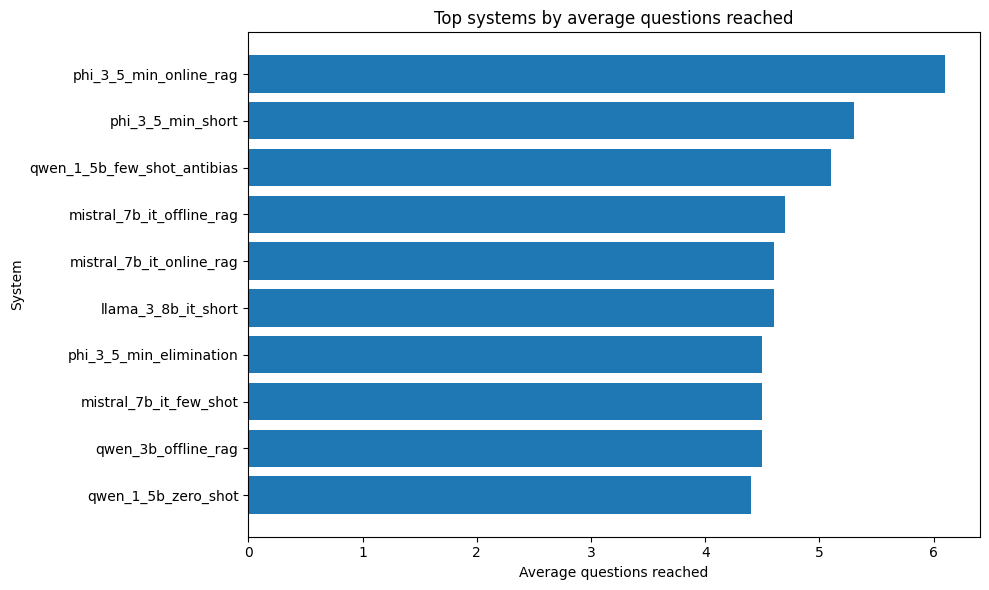

In [ ]:
plot_df = main_report_table.head(10).sort_values(
    "average_questions_reached",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(plot_df["system_name"], plot_df["average_questions_reached"])
plt.xlabel("Average questions reached")
plt.ylabel("System")
plt.title("Top systems by average questions reached")
plt.tight_layout()
plt.savefig("final_plot_top_questions.png", dpi=150)
plt.show()

In [ ]:
best_non_rag = (
    system_summary[system_summary["rag_type"] == "no_rag"]
    .sort_values(
        ["model_label", "average_questions_reached", "average_final_earned_amount"],
        ascending=[True, False, False]
    )
    .groupby("model_label", dropna=False)
    .head(1)
    .assign(setting_group="Best non-RAG")
)

best_rag = (
    system_summary[system_summary["rag_type"] != "no_rag"]
    .sort_values(
        ["model_label", "average_questions_reached", "average_final_earned_amount"],
        ascending=[True, False, False]
    )
    .groupby("model_label", dropna=False)
    .head(1)
    .assign(setting_group="Best RAG")
)

rag_vs_nonrag_compact = pd.concat(
    [best_non_rag, best_rag],
    ignore_index=True
)

rag_vs_nonrag_compact = rag_vs_nonrag_compact[
    [
        "model_label",
        "setting_group",
        "system_name",
        "rag_type",
        "average_questions_reached",
        "average_final_earned_amount",
        "best_final_earned_amount",
        "average_response_time",
        "valid_output_rate",
    ]
].sort_values(["model_label", "setting_group"])



The comparison shows that RAG was not equally useful for all models.  It helped stronger or more retrieval-compatible models such as Phi-3.5 Mini, Mistral 7B, and Qwen 3B, but it hurt Qwen 1.5B and Llama 3 8B in this setup. This suggests that adding retrieved context is not automatically useful. The model must be able to use the retrieved facts correctly, and the retrieval results must be relevant enough to avoid adding noise.

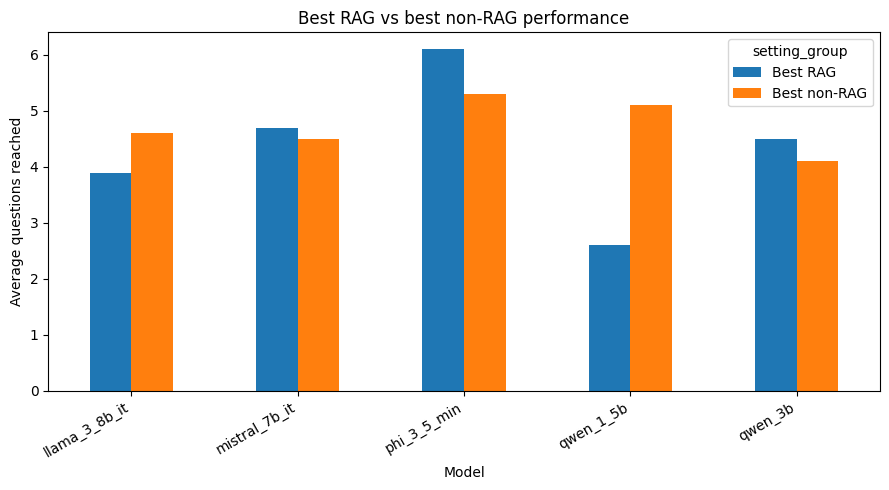

In [ ]:
rag_plot_df = rag_vs_nonrag_compact.copy()

model_counts = rag_plot_df.groupby("model_label")["setting_group"].nunique()
valid_models = model_counts[model_counts >= 2].index
rag_plot_df = rag_plot_df[rag_plot_df["model_label"].isin(valid_models)]

pivot_rag = rag_plot_df.pivot_table(
    index="model_label",
    columns="setting_group",
    values="average_questions_reached",
    aggfunc="max"
)

pivot_rag.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Average questions reached")
plt.xlabel("Model")
plt.title("Best RAG vs best non-RAG performance")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("final_plot_rag_vs_nonrag.png", dpi=150)
plt.show()

The strongest overall system is **Phi-3.5 Mini with online RAG**. It has both the highest average progress, reaching **6.1 questions on average**, and the highest best final score, reaching **1,024,000**. This shows that it was not only consistently strong, but also had the best single run.

Some systems show a more balanced performance. For example, **Phi-3.5 Mini short**, **Qwen 1.5B few-shot anti-bias**, and **Mistral 7B offline RAG** all have relatively high average progress and strong best scores. These systems are reliable candidates because they perform well on average and can also reach high rewards in their best runs.

However, the plot also shows that average progress and best score do not always move together. For example, **Qwen 1.5B zero-shot** has a relatively high average number of questions reached, but its best score is much lower than the stronger systems. This means that it can progress through some early questions, but it rarely reaches the high-reward levels.

Overall, the best system should not be selected only by its highest score or only by its average progress.

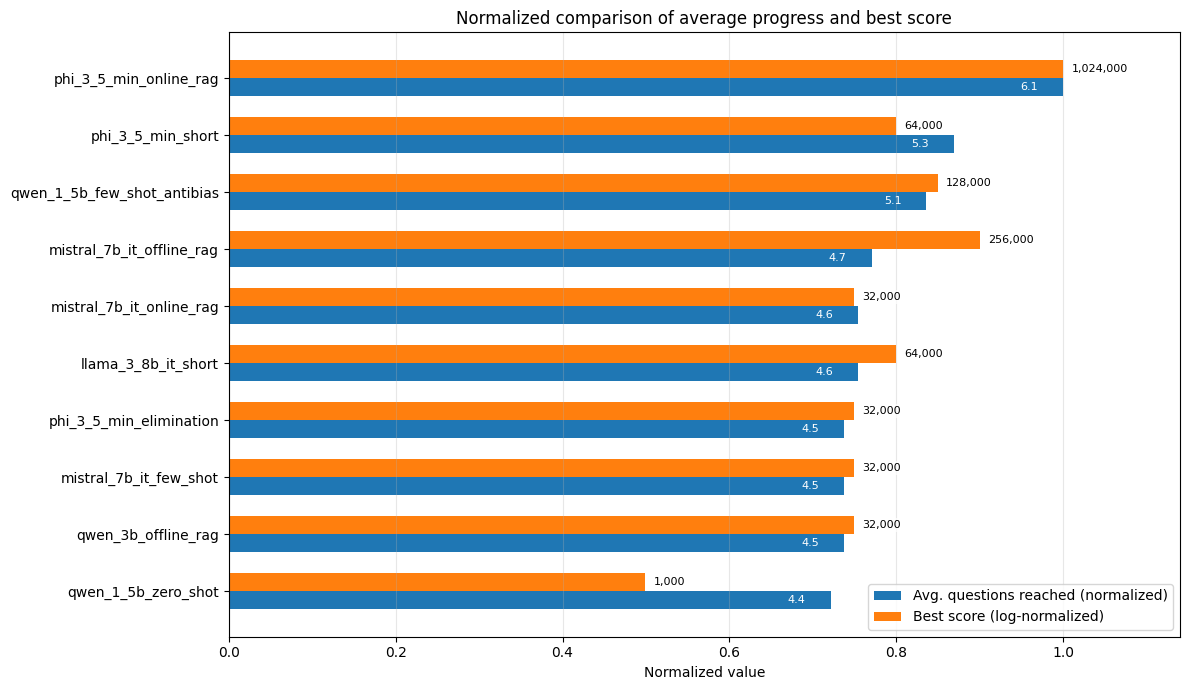

In [ ]:
plot_df = main_report_table.head(10).copy()

plot_df["norm_avg_questions"] = (
    plot_df["average_questions_reached"]
    / plot_df["average_questions_reached"].max()
)

plot_df["norm_best_score"] = (
    np.log1p(plot_df["best_final_earned_amount"])
    / np.log1p(plot_df["best_final_earned_amount"]).max()
)

plot_df = plot_df.sort_values("norm_avg_questions", ascending=True).reset_index(drop=True)

y = np.arange(len(plot_df))
bar_height = 0.32

plt.figure(figsize=(12, 7))

plt.barh(
    y - bar_height / 2,
    plot_df["norm_avg_questions"],
    height=bar_height,
    label="Avg. questions reached (normalized)"
)

plt.barh(
    y + bar_height / 2,
    plot_df["norm_best_score"],
    height=bar_height,
    label="Best score (log-normalized)"
)

for i in range(len(plot_df)):
    blue_x = plot_df.loc[i, "norm_avg_questions"]
    orange_x = plot_df.loc[i, "norm_best_score"]

    if blue_x > 0.12:
        plt.text(
            blue_x - 0.03,
            y[i] - bar_height / 2,
            f'{plot_df.loc[i, "average_questions_reached"]:.1f}',
            va="center",
            ha="right",
            fontsize=8,
            color="white"
        )
    else:
        plt.text(
            blue_x + 0.01,
            y[i] - bar_height / 2,
            f'{plot_df.loc[i, "average_questions_reached"]:.1f}',
            va="center",
            ha="left",
            fontsize=8
        )

    plt.text(
        orange_x + 0.01,
        y[i] + bar_height / 2,
        f'{int(plot_df.loc[i, "best_final_earned_amount"]):,}',
        va="center",
        ha="left",
        fontsize=8,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.5)
    )

plt.yticks(y, plot_df["system_name"])
plt.xlabel("Normalized value")
plt.title("Normalized comparison of average progress and best score")
plt.xlim(0, 1.14)
plt.legend(loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("final_plot_normalized_progress_best_score_clean.png", dpi=150, bbox_inches="tight")
plt.show()

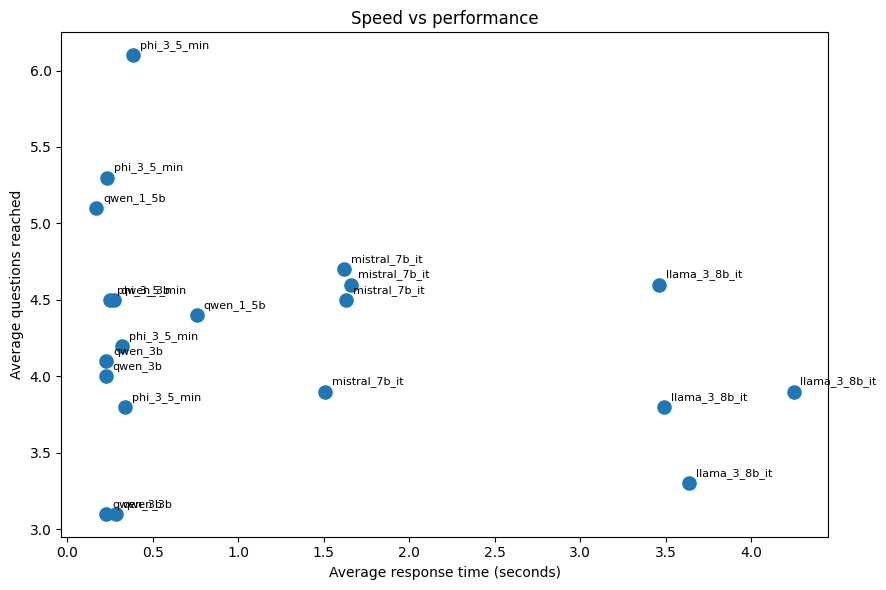

In [ ]:
plot_df = main_report_table.head(20).copy()

plt.figure(figsize=(9, 6))
plt.scatter(
    plot_df["average_response_time"],
    plot_df["average_questions_reached"],
    s=90
)

for _, row in plot_df.iterrows():
    label = str(row["model_label"])
    plt.annotate(
        label,
        (row["average_response_time"], row["average_questions_reached"]),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Average response time (seconds)")
plt.ylabel("Average questions reached")
plt.title("Speed vs performance")
plt.tight_layout()
plt.savefig("final_plot_speed_vs_performance.png", dpi=150)
plt.show()

The results show that there is **no strong relationship between speed and performance**. The correlation between model speed and average questions reached is only **0.168**, which is very weak. This means that a slower model does not necessarily answer more questions correctly, and a faster model does not necessarily perform worse.

Some of the best-performing systems are still quite fast. For example, **Phi-3.5 Mini** reaches the highest average progress while keeping response time below one second. **Qwen 1.5B** also performs well with very low response time, especially in its stronger prompt settings.

On the other hand, larger models such as **Llama 3 8B** have much higher response times, around 3.5 to 4 seconds on average, but they do not clearly outperform the faster systems. This suggests that larger and slower models are not automatically better for this task.

The correlation between model speed and average reward is also very low, around **-0.032**. This confirms that response time alone does not explain final performance or reward.

In [ ]:
size_perf_df = main_report_table.dropna(
    subset=["average_response_time", "average_questions_reached"]
).copy()

corr_questions = size_perf_df["average_response_time"].corr(
    size_perf_df["average_questions_reached"]
)

corr_reward = size_perf_df["average_response_time"].corr(
    size_perf_df["average_final_earned_amount"]
)

print("Correlation: model speed vs average questions reached:", round(corr_questions, 3))
print("Correlation: model speed vs average reward:", round(corr_reward, 3))

Correlation: model speed vs average questions reached: 0.168
Correlation: model speed vs average reward: -0.032


In [ ]:
MODEL_SIZE_BILLIONS = {
    "qwen_1_5b": 1.5,
    "qwen_3b": 3.0,
    "phi_3_5_min": 3.8,
    "deepseek_r1_qwen_1_5b": 1.5,
    "llama_3_8b_it": 8.0,
    "mistral_7b_it": 7.0,
    "gemma_3_4b_it": 4.0,
}

system_summary["model_size_b"] = system_summary["model_label"].map(MODEL_SIZE_BILLIONS)

best_non_rag_per_model = (
    system_summary[
        (system_summary["rag_type"] == "no_rag")
        & (system_summary["model_size_b"].notna())
    ]
    .sort_values(
        ["model_label", "average_questions_reached", "average_final_earned_amount"],
        ascending=[True, False, False]
    )
    .groupby("model_label")
    .head(1)
    .reset_index(drop=True)
)

The model size comparison shows that bigger models were not always better. The correlation between model size and average questions reached is only **0.359**, so there is a weak-to-moderate positive relationship, but not a strong one.

**Phi-3.5 Mini** achieved the best average performance despite being smaller than Mistral 7B and Llama 3 8B. **Qwen 1.5B** also performed strongly compared with some larger models.

The correlation between model size and average reward is **-0.246**, meaning that larger models did not necessarily achieve higher rewards. Overall, model size mattered, but it was not the main factor behind the best results.

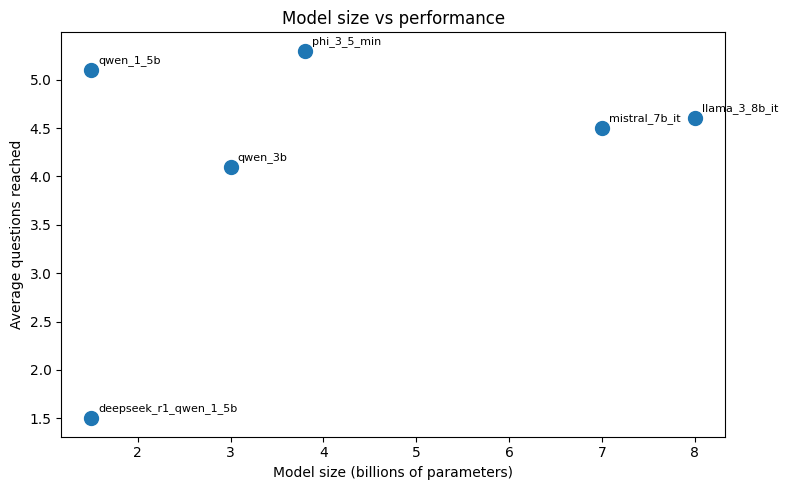

In [ ]:
plot_df = best_non_rag_per_model.copy()

plt.figure(figsize=(8, 5))
plt.scatter(
    plot_df["model_size_b"],
    plot_df["average_questions_reached"],
    s=100
)

for _, row in plot_df.iterrows():
    plt.annotate(
        str(row["model_label"]),
        (row["model_size_b"], row["average_questions_reached"]),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Model size (billions of parameters)")
plt.ylabel("Average questions reached")
plt.title("Model size vs performance")
plt.tight_layout()
plt.savefig("final_plot_model_size_vs_performance.png", dpi=150)
plt.show()

In [ ]:
size_perf_df = best_non_rag_per_model.dropna(
    subset=["model_size_b", "average_questions_reached"]
).copy()

corr_questions = size_perf_df["model_size_b"].corr(
    size_perf_df["average_questions_reached"]
)

corr_reward = size_perf_df["model_size_b"].corr(
    size_perf_df["average_final_earned_amount"]
)

print("Correlation: model size vs average questions reached:", round(corr_questions, 3))
print("Correlation: model size vs average reward:", round(corr_reward, 3))

Correlation: model size vs average questions reached: 0.359
Correlation: model size vs average reward: -0.246


In [ ]:
prompt_sensitivity = (
    system_summary[system_summary["rag_type"] == "no_rag"]
    .groupby("model_label")
    .agg(
        best_prompt_score=("average_questions_reached", "max"),
        worst_prompt_score=("average_questions_reached", "min"),
        best_reward=("average_final_earned_amount", "max"),
        worst_reward=("average_final_earned_amount", "min"),
    )
    .reset_index()
)

prompt_sensitivity["prompt_sensitivity_gap"] = (
    prompt_sensitivity["best_prompt_score"]
    - prompt_sensitivity["worst_prompt_score"]
)

prompt_sensitivity["reward_sensitivity_gap"] = (
    prompt_sensitivity["best_reward"]
    - prompt_sensitivity["worst_reward"]
)

prompt_sensitivity = prompt_sensitivity.sort_values(
    "prompt_sensitivity_gap",
    ascending=False
)



**Phi-3.5 Mini** was the most sensitive model. As a compact instruction-tuned model, its performance depended strongly on clear task framing, output constraints, and retrieved context.

**Mistral 7B** and **Llama 3 8B** were also affected by prompt design. Even though they are larger decoder-only instruction models, they still needed a prompt that clearly enforced the numeric-only answer format.

**Qwen 1.5B** was sensitive because of its smaller capacity, so it benefited from strict output control, few-shot examples, and anti-bias instructions. **Qwen 3B**, from the same family but larger, was more stable across prompts.

**DeepSeek-R1-Distill-Qwen 1.5B** had the smallest gap, but this likely reflects consistently low performance rather than true robustness. Its reasoning-style architecture is less naturally suited to a task that requires only one numeric option ID.

Overall, prompt engineering was a major factor. The same model could perform very differently depending on how the task and output format were defined.

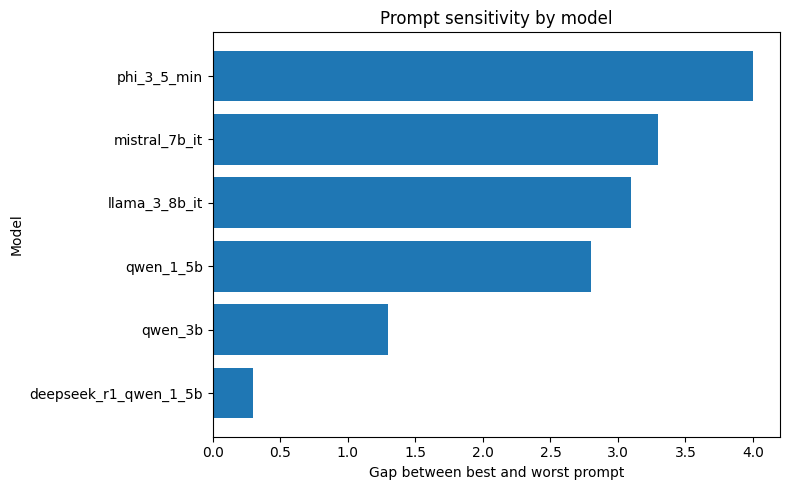

In [ ]:
plot_df = prompt_sensitivity.sort_values("prompt_sensitivity_gap", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(plot_df["model_label"], plot_df["prompt_sensitivity_gap"])
plt.xlabel("Gap between best and worst prompt")
plt.ylabel("Model")
plt.title("Prompt sensitivity by model")
plt.tight_layout()
plt.savefig("final_plot_prompt_sensitivity.png", dpi=150)
plt.show()

### 10.3 Error Analysis

#### 10.3.1 Error Type Distribution

In [ ]:
def classify_error(row, high_confidence_threshold=0.70):
    raw = str(row.get("raw_response", "")).strip()
    selected_id = row.get("selected_option_id", None)

    # 1. Empty model output
    if raw == "":
        return "empty_response"

    # 2. Parser could not extract a valid option
    if pd.isna(selected_id):
        return "invalid_or_unparsed_output"

    # 3. Check whether the model violated the required output format
    raw_clean = raw.strip()
    is_only_number = raw_clean.isdigit()

    has_format_violation = False

    if not is_only_number:
        raw_lower = raw_clean.lower()
        if (
            "correct answer" in raw_lower
            or "explanation" in raw_lower
            or len(raw_clean.split()) > 3
            or "," in raw_clean
        ):
            has_format_violation = True

    # 4. Confidence-based error type
    confidence_score = pd.to_numeric(
        row.get("confidence_score", numpy.nan),
        errors="coerce"
    )

    if pd.notna(confidence_score) and confidence_score >= high_confidence_threshold:
        if has_format_violation:
            return "high_confidence_wrong_with_format_violation"
        return "high_confidence_wrong_answer"

    # 5. Format violation but not high-confidence
    if has_format_violation:
        return "wrong_option_with_format_violation"

    # 6. If correct answer column exists, classify wrong valid choice
    if "correct_option_id" in row.index and not pd.isna(row.get("correct_option_id")):
        if selected_id != row.get("correct_option_id"):
            return "wrong_option_selected"

    # 7. If correct_option_id is unavailable, but this row is already from df_errors
    return "wrong_option_selected"

In [ ]:
df_conf = add_overconfidence_labels(df_all)

df_conf["error_type"] = df_conf.apply(classify_error, axis=1)

df_errors = df_conf[df_conf["correct"] == False].copy()

error_type_summary = (
    df_errors
    .groupby(["model_label", "prompt_family", "error_type"], dropna=False)
    .size()
    .reset_index(name="error_count")
)

error_type_summary["total_errors"] = (
    error_type_summary
    .groupby(["model_label", "prompt_family"])["error_count"]
    .transform("sum")
)

error_type_summary["error_percentage"] = (
    100 * error_type_summary["error_count"] / error_type_summary["total_errors"]
).round(2)

error_type_summary = error_type_summary.sort_values(
    ["model_label", "prompt_family", "error_count"],
    ascending=[True, True, False]
)


Most errors were valid but incorrect answers. The dominant error type across the top systems was `wrong_option_selected`, meaning that the models usually followed the numeric output format but selected the wrong option.

Format violations were relatively rare, which suggests that the prompt constraints and short output setting worked well. However, the overconfidence analysis shows that some models, especially **Qwen 3B** and **Qwen 1.5B**, were sometimes confidently wrong.

Overall, the main remaining problem was factual answer selection, not output formatting. The models generally produced valid outputs, but they still struggled to choose the correct answer reliably.

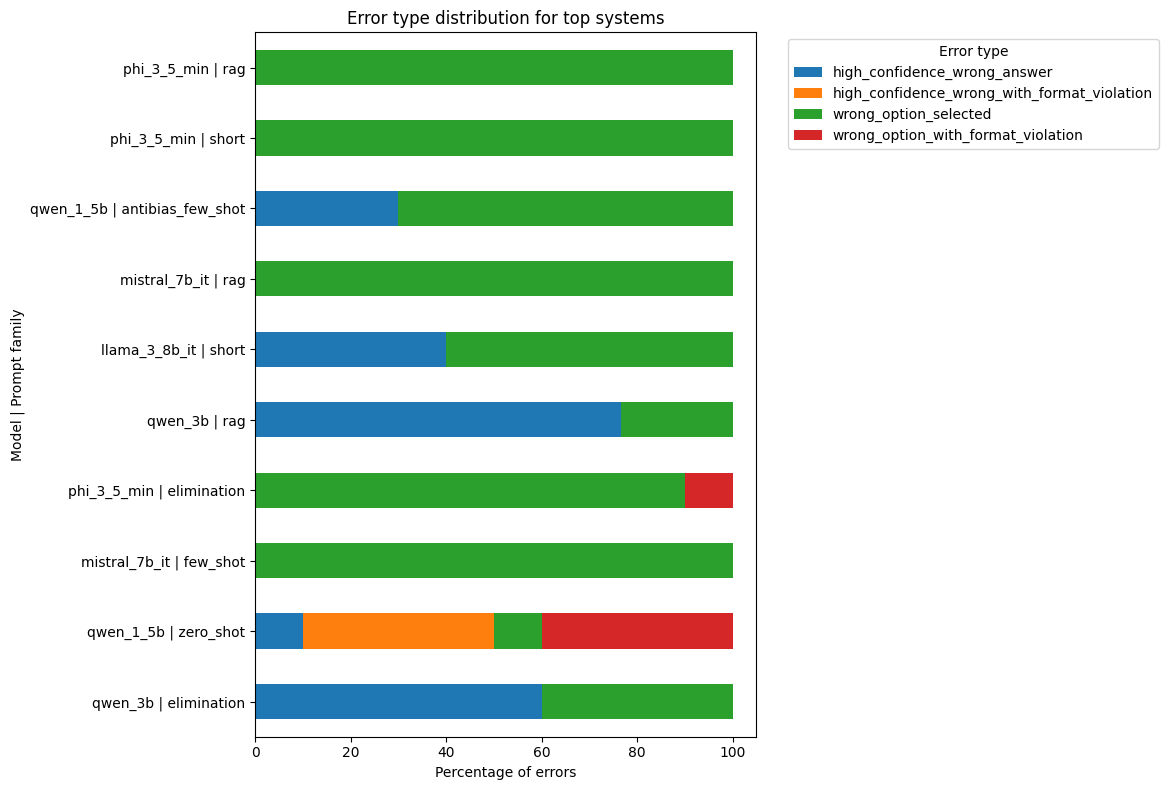

In [ ]:
error_type_percent = error_type_summary.copy()

error_type_percent["system_group"] = (
    error_type_percent["model_label"].astype(str)
    + " | "
    + error_type_percent["prompt_family"].astype(str)
)

main_report_table["system_group"] = (
    main_report_table["model_label"].astype(str)
    + " | "
    + main_report_table["prompt_family"].astype(str)
)

top_groups = (
    main_report_table
    .head(12)["system_group"]
    .drop_duplicates()
    .tolist()
)

plot_error = error_type_percent[
    error_type_percent["system_group"].isin(top_groups)
].copy()

pivot_error = plot_error.pivot_table(
    index="system_group",
    columns="error_type",
    values="error_percentage",
    fill_value=0
)


ordered_groups = [
    g for g in top_groups
    if g in pivot_error.index
]

pivot_error = pivot_error.loc[ordered_groups]
pivot_error = pivot_error.iloc[::-1]

ax = pivot_error.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8)
)

plt.xlabel("Percentage of errors")
plt.ylabel("Model | Prompt family")
plt.title("Error type distribution for top systems")
plt.legend(
    title="Error type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig(
    "final_plot_error_type_distribution_top_systems.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [ ]:
error_confidence_summary = (
    df_errors
    .groupby(["model_label", "prompt_family"], dropna=False)
    .agg(
        total_errors=("correct", "count"),

        format_or_parse_errors=(
            "error_type",
            lambda x: x.isin([
                "empty_response",
                "invalid_or_unparsed_output",
                "wrong_option_with_format_violation",
                "high_confidence_wrong_with_format_violation",
            ]).sum()
        ),

        high_confidence_wrong_answers=(
            "error_type",
            lambda x: x.isin([
                "high_confidence_wrong_answer",
                "high_confidence_wrong_with_format_violation",
            ]).sum()
        ),

        average_error_confidence=("confidence_score", "mean"),
        average_error_margin=("confidence_margin", "mean"),
    )
    .reset_index()
)

error_confidence_summary["format_or_parse_error_rate"] = (
    error_confidence_summary["format_or_parse_errors"]
    / error_confidence_summary["total_errors"]
).round(3)

error_confidence_summary["high_confidence_error_rate"] = (
    error_confidence_summary["high_confidence_wrong_answers"]
    / error_confidence_summary["total_errors"]
).round(3)

error_confidence_summary = error_confidence_summary.sort_values(
    "high_confidence_error_rate",
    ascending=False
)

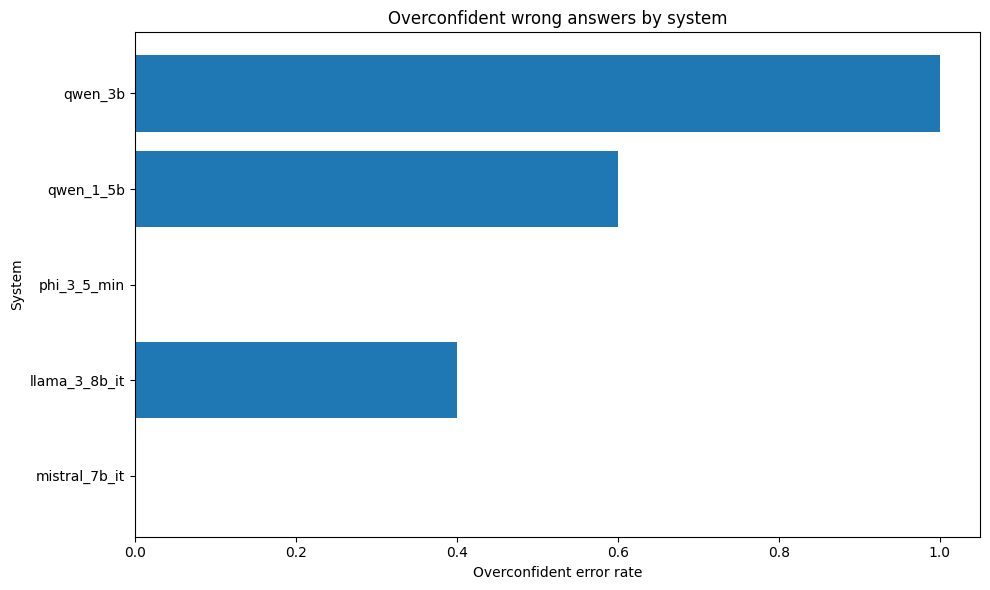

In [ ]:
plot_overconf = error_confidence_summary[
    error_confidence_summary["model_label"].isin(top_systems)
].copy()

plot_overconf = plot_overconf.sort_values("high_confidence_error_rate", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(
    plot_overconf["model_label"],
    plot_overconf["high_confidence_error_rate"]
)
plt.xlabel("Overconfident error rate")
plt.ylabel("System")
plt.title("Overconfident wrong answers by system")
plt.tight_layout()
plt.savefig("final_plot_overconfident_errors.png", dpi=150, bbox_inches="tight")
plt.show()

#### 10.3.2 Topic and Category Error Analysis

In [ ]:
ENTERTAINMENT_CATEGORY_KEYWORDS = {
    "movie": [
        "film", "movie", "cinema", "director", "directed", "screenplay",
        "actor", "actress", "cast", "role", "character", "scene",
        "sequel", "trilogy", "franchise", "oscar", "academy award",
        "box office", "runtime", "cut", "visual effects", "animation",
        "cinematography"
    ],

    "music": [
        "album", "song", "single", "artist", "band", "singer", "vocal",
        "lyrics", "track", "record", "released", "genre", "guitar",
        "drummer", "bassist", "rapper", "producer", "grammy",
        "billboard", "rock", "pop", "jazz", "hip hop", "rap"
    ],

    "tv": [
        "tv", "television", "series", "sitcom", "episode", "season",
        "show", "aired", "broadcast", "network", "streaming"
    ],

    "video_game": [
        "game", "video game", "console", "playstation", "xbox",
        "nintendo", "developer", "publisher", "gameplay", "gaming"
    ],

    "award": [
        "award", "awards", "oscar", "academy award", "grammy",
        "emmy", "golden globe", "bafta", "won", "winner",
        "nominated", "nomination"
    ],

    "biography": [
        "born", "birth", "maiden name", "nickname", "stage name",
        "real name", "career", "relationship", "married", "childhood",
        "influence", "influenced", "early life", "military service",
        "moved to", "changed his name", "changed her name"
    ],

    "plot_theme_concept": [
        "plot", "story", "theme", "principle", "concept", "symbolizes",
        "represents", "relationship between", "fundamental principle",
        "primary reason", "significance", "meaning", "motivation",
        "character arc", "ending"
    ],
}


def clean_text(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()


def keyword_score(text, keywords):
    text_lower = clean_text(text).lower()
    score = 0

    for keyword in keywords:
        keyword_lower = keyword.lower()

        if " " in keyword_lower:
            if keyword_lower in text_lower:
                score += 3
        else:
            if re.search(rf"\b{re.escape(keyword_lower)}\b", text_lower):
                score += 1

    return score


def classify_entertainment_question_text(question_text, options_text=""):
    full_text = clean_text(question_text + " " + options_text)

    scores = {
        category: keyword_score(full_text, keywords)
        for category, keywords in ENTERTAINMENT_CATEGORY_KEYWORDS.items()
    }

    best_category = max(scores, key=scores.get)

    if scores[best_category] == 0:
        return "general_entertainment"

    return best_category

In [ ]:
def get_options_text(options_value):
    try:
        options = json.loads(options_value)
        return " ".join(str(opt.get("text", "")) for opt in options)
    except Exception:
        return str(options_value)


df_all["options_text"] = df_all["options"].apply(get_options_text)

df_all["question_category"] = df_all.apply(
    lambda row: classify_entertainment_question_text(
        row.get("question_text", ""),
        row.get("options_text", "")
    ),
    axis=1
)

display(
    df_all[
        ["system_name", "question_text", "question_category"]
    ].head()
)

,system_name,question_text,question_category
0,deepseek_r1_qwen_1_5b_zero_shot,Which term describes the distinctive visual st...,movie
1,deepseek_r1_qwen_1_5b_zero_shot,What is the fundamental principle behind Radio...,plot_theme_concept
2,deepseek_r1_qwen_1_5b_zero_shot,Which member of the Rat Pack became the group'...,general_entertainment
3,deepseek_r1_qwen_1_5b_zero_shot,What was the primary goal of U2's music during...,tv
4,deepseek_r1_qwen_1_5b_zero_shot,"According to Robert Greenfield, how did The Be...",music


In [ ]:
category_error_summary = (
    df_all
    .groupby(["question_category"])
    .agg(
        total_questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        accuracy=("correct", "mean"),
        errors=("correct", lambda x: (~x.astype(bool)).sum()),
        average_level=("level_before_answer", "mean"),
    )
    .reset_index()
)

category_error_summary["error_rate"] = (
    1 - category_error_summary["accuracy"]
).round(3)

category_error_summary = category_error_summary.sort_values(
    "error_rate",
    ascending=False
)

display(category_error_summary)

category_error_summary.to_csv("final_category_error_summary.csv", index=False)

,question_category,total_questions,correct_answers,accuracy,errors,average_level,error_rate
0,award,15,6,0.4,9,2.866667,0.6
7,video_game,6,3,0.5,3,0.833333,0.5
1,biography,155,93,0.6,62,2.193548,0.4
4,music,249,156,0.626506,93,2.240964,0.373
3,movie,284,195,0.68662,89,2.084507,0.313
2,general_entertainment,149,113,0.758389,36,2.228188,0.242
5,plot_theme_concept,333,261,0.783784,72,2.543544,0.216
6,tv,25,20,0.8,5,1.560000,0.2


In [ ]:
model_category_summary = (
    df_all
    .groupby(["model_label", "question_category"])
    .agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        accuracy=("correct", "mean"),
        avg_confidence=("confidence_score", "mean"),
        avg_response_time=("response_time", "mean"),
    )
    .reset_index()
)

model_category_summary["error_rate"] = (
    1 - model_category_summary["accuracy"]
).round(3)

display(
    model_category_summary.sort_values(
        ["model_label", "error_rate"],
        ascending=[True, False]
    )
)


,model_label,question_category,questions,correct_answers,accuracy,avg_confidence,avg_response_time,error_rate
5,deepseek_r1_qwen_1_5b,tv,2,0,0.0,0.066284,0.231905,1.0
1,deepseek_r1_qwen_1_5b,general_entertainment,5,1,0.2,0.123474,0.245872,0.8
2,deepseek_r1_qwen_1_5b,movie,13,3,0.230769,0.155962,0.250937,0.769
3,deepseek_r1_qwen_1_5b,music,16,4,0.25,0.180188,0.244000,0.75
4,deepseek_r1_qwen_1_5b,plot_theme_concept,17,6,0.352941,0.122754,0.247204,0.647
0,deepseek_r1_qwen_1_5b,biography,2,1,0.5,0.105103,0.300179,0.5
7,llama_3_8b_it,biography,24,14,0.583333,0.457858,3.538187,0.417
10,llama_3_8b_it,music,39,25,0.641026,0.588295,3.418976,0.359
9,llama_3_8b_it,movie,40,29,0.725,0.533011,3.439505,0.275
8,llama_3_8b_it,general_entertainment,19,14,0.736842,0.662598,3.771702,0.263


The category analysis shows that the models performed differently across Entertainment topics. **TV**, **plot/theme/concept**, and **general entertainment** had the highest accuracy, suggesting that broader or more semantic questions were easier for the models.

The hardest categories were **award**, **video game**, **biography**, and **music**. These topics usually require more precise factual knowledge, such as award winners, artists, albums, developers, or personal details.

Overall, the results suggest that many model errors came from factual knowledge limitations rather than output-format problems. Fact-heavy categories were harder, while broader entertainment categories were answered more reliably.

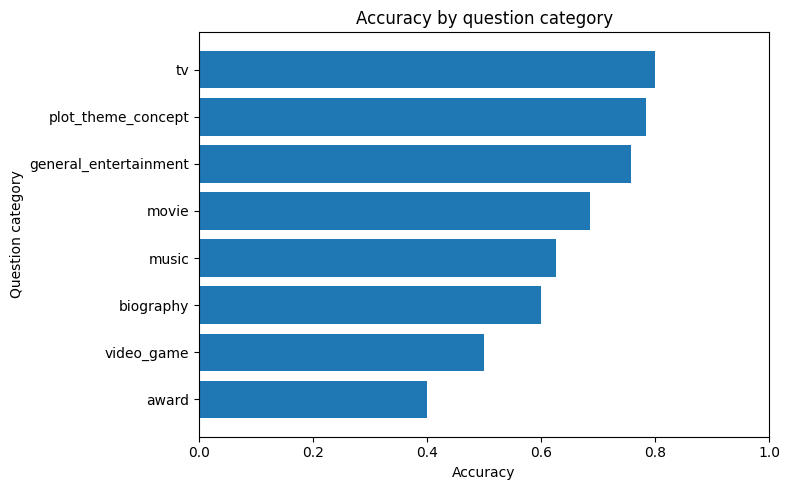

In [ ]:
plot_df = category_error_summary.sort_values("accuracy", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(plot_df["question_category"], plot_df["accuracy"])
plt.xlabel("Accuracy")
plt.ylabel("Question category")
plt.title("Accuracy by question category")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig("final_plot_category_accuracy.png", dpi=150)
plt.show()

In [ ]:
filtered_category_summary = model_category_summary[
    model_category_summary["questions"] >= 5
].copy()

display(
    filtered_category_summary.sort_values(
        ["model_label", "error_rate"],
        ascending=[True, False]
    )
)



,model_label,question_category,questions,correct_answers,accuracy,avg_confidence,avg_response_time,error_rate
1,deepseek_r1_qwen_1_5b,general_entertainment,5,1,0.2,0.123474,0.245872,0.8
2,deepseek_r1_qwen_1_5b,movie,13,3,0.230769,0.155962,0.250937,0.769
3,deepseek_r1_qwen_1_5b,music,16,4,0.25,0.180188,0.244000,0.75
4,deepseek_r1_qwen_1_5b,plot_theme_concept,17,6,0.352941,0.122754,0.247204,0.647
7,llama_3_8b_it,biography,24,14,0.583333,0.457858,3.538187,0.417
10,llama_3_8b_it,music,39,25,0.641026,0.588295,3.418976,0.359
9,llama_3_8b_it,movie,40,29,0.725,0.533011,3.439505,0.275
8,llama_3_8b_it,general_entertainment,19,14,0.736842,0.662598,3.771702,0.263
11,llama_3_8b_it,plot_theme_concept,45,35,0.777778,0.544384,3.643051,0.222
13,mistral_7b_it,award,7,2,0.285714,0.250000,1.634998,0.714


## 11. Ensemble Experiments

The ensemble experiment was designed to combine models with different strengths instead of relying on only one system.

At first, we planned a three-model ensemble:

1. **Phi-3.5 Mini with online RAG** as the main model  
2. **Qwen 1.5B with anti-bias few-shot prompting** as a fast secondary model  
3. **Mistral 7B with offline RAG** as a tie-breaker  

The initial logic was simple: if Phi and Qwen agreed, their shared answer would be submitted. If they disagreed, Mistral would be used as a third model, and the final answer would be selected using weighted voting.

However, this full ensemble was not practical in Colab because of GPU memory limitations. Loading Phi, Qwen, and Mistral in the same workflow increased the risk of out-of-memory errors and made the system slower.

For this reason, the final version was simplified to a **two-model cached ensemble** using:

1. **Phi-3.5 Mini with online RAG**
2. **Qwen 1.5B with anti-bias few-shot prompting**

The models were cached after the first load, so they did not need to be loaded again for every question. This made the ensemble faster and more stable.

The final decision logic was:

```text
If Phi and Qwen agree → submit the shared answer.
If they disagree and Qwen is highly confident → submit Qwen's answer.
Otherwise → keep Phi's answer.

In [ ]:
ENSEMBLE_CONFIGS = [
    {
        "label": "phi_3_5_min_online_rag",
        "model_label": "phi_3_5_min",
        "model_name": "microsoft/Phi-3.5-mini-instruct",
        "prompt_type": "online_rag",
        "weight": 0.65,
    },
    {
        "label": "qwen_1_5b_few_shot_antibias",
        "model_label": "qwen_1_5b",
        "model_name": "Qwen/Qwen2.5-1.5B-Instruct",
        "prompt_type": "few_shot_antibias",
        "weight": 0.35,
    },
]

MISTRAL_TIEBREAKER_CONFIG = {
    "label": "mistral_7b_it_offline_rag",
    "model_label": "mistral_7b_it",
    "model_name": "mistralai/Mistral-7B-Instruct-v0.3",
    "prompt_type": "offline_rag",
    "weight": 0.20,
}

In [ ]:
import gc
import time
import json
import torch
import pandas as pd
import numpy as np


MODEL_CACHE = {}
CURRENT_ACTIVE_MODEL_NAME = None


def clear_gpu_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


def cache_current_model(model_name):
    """
    Save whatever global objects exist after load_local_causal_lm().
    This version is robust: it does not assume tokenizer always exists.
    """

    global MODEL_CACHE

    cache_item = {}

    if "model" in globals():
        cache_item["model"] = globals()["model"]

    if "tokenizer" in globals():
        cache_item["tokenizer"] = globals()["tokenizer"]

    if "generator" in globals():
        cache_item["generator"] = globals()["generator"]

    if "pipe" in globals():
        cache_item["pipe"] = globals()["pipe"]

    if len(cache_item) == 0:
        raise RuntimeError(
            "No model/generator/tokenizer/pipe was found after loading. "
            "Check what load_local_causal_lm() creates."
        )

    MODEL_CACHE[model_name] = cache_item


def activate_cached_model(model_name):
    """
    Restore cached objects into global variables.
    """

    global CURRENT_ACTIVE_MODEL_NAME

    cached = MODEL_CACHE[model_name]

    if "model" in cached:
        globals()["model"] = cached["model"]

    if "tokenizer" in cached:
        globals()["tokenizer"] = cached["tokenizer"]

    if "generator" in cached:
        globals()["generator"] = cached["generator"]

    if "pipe" in cached:
        globals()["pipe"] = cached["pipe"]

    CURRENT_ACTIVE_MODEL_NAME = model_name


def load_model_cached(model_name):
    """
    Load model only once. If already cached, reuse it.
    """

    global CURRENT_ACTIVE_MODEL_NAME

    if model_name in MODEL_CACHE:
        activate_cached_model(model_name)
        print(f"Using cached model: {model_name}")
        return

    print(f"Loading model for the first time: {model_name}")

    clear_gpu_memory()

    load_local_causal_lm(model_name)

    cache_current_model(model_name)

    CURRENT_ACTIVE_MODEL_NAME = model_name

    print(f"Cached model: {model_name}")


def show_model_cache():
    print("Cached models:")
    for name in MODEL_CACHE:
        active_marker = " <-- active" if name == CURRENT_ACTIVE_MODEL_NAME else ""
        keys = ", ".join(MODEL_CACHE[name].keys())
        print(f"- {name} [{keys}]{active_marker}")

In [ ]:
def normalize_prediction_output(prediction, model_config):
    """
    Convert different generate_answer outputs into one common dictionary.
    """

    if isinstance(prediction, dict):
        selected_id = (
            prediction.get("predicted_id")
            if prediction.get("predicted_id") is not None
            else prediction.get("selected_option_id")
        )

        if selected_id is None:
            selected_id = prediction.get("submitted_id")

        raw_response = prediction.get("raw_response", "")
        confidence = prediction.get("confidence_score", np.nan)
        margin = prediction.get("confidence_margin", np.nan)
        response_time = prediction.get("response_time", np.nan)
        valid_output = prediction.get("valid_output", True)
        used_fallback = prediction.get("used_fallback", False)

    else:
        selected_id = prediction
        raw_response = str(prediction)
        confidence = np.nan
        margin = np.nan
        response_time = np.nan
        valid_output = True
        used_fallback = False

    try:
        if selected_id is not None and not pd.isna(selected_id):
            selected_id = int(selected_id)
        else:
            selected_id = None
    except Exception:
        selected_id = None

    return {
        "model_label": model_config["model_label"],
        "ensemble_label": model_config["label"],
        "prompt_type": model_config["prompt_type"],
        "weight": model_config["weight"],
        "selected_option_id": selected_id,
        "raw_response": raw_response,
        "confidence_score": confidence,
        "confidence_margin": margin,
        "response_time": response_time,
        "valid_output": valid_output,
        "used_fallback": used_fallback,
    }

In [ ]:
def generate_single_ensemble_member(
    question,
    model_config,
    max_new_tokens=3,
):
    """
    Run one ensemble member using the cached model.
    """

    start = time.time()

    load_model_cached(model_config["model_name"])

    prediction = generate_answer(
        question=question,
        prompt_type=model_config["prompt_type"],
        max_new_tokens=max_new_tokens,
    )

    normalized = normalize_prediction_output(
        prediction,
        model_config
    )

    if pd.isna(normalized["response_time"]):
        normalized["response_time"] = time.time() - start

    print(
        f"{model_config['label']} | "
        f"submitted={normalized['selected_option_id']} | "
        f"conf={normalized['confidence_score']} | "
        f"margin={normalized['confidence_margin']} | "
        f"time={normalized['response_time']:.2f}s"
    )

    return normalized

In [ ]:
def is_high_confidence(
    pred,
    confidence_threshold=0.65,
    margin_threshold=0.15
):
    conf = pred.get("confidence_score", np.nan)
    margin = pred.get("confidence_margin", np.nan)

    if pd.isna(conf):
        return False

    if pd.isna(margin):
        return conf >= confidence_threshold

    return conf >= confidence_threshold and margin >= margin_threshold


def weighted_vote(predictions):
    scores = {}

    for pred in predictions:
        option_id = pred.get("selected_option_id")

        if option_id is None:
            continue

        weight = float(pred.get("weight", 0.0))
        scores[option_id] = scores.get(option_id, 0.0) + weight

    if not scores:
        return None, {}

    selected_id = max(scores.items(), key=lambda x: x[1])[0]

    return selected_id, scores

In [ ]:
def generate_selective_ensemble_answer(
    question,
    max_new_tokens=3,
    primary_conf_threshold=0.65,
    primary_margin_threshold=0.15,
    use_mistral_tiebreaker=False,
):
    print("SELECTIVE ENSEMBLE IS RUNNING")

    ensemble_start = time.time()
    member_predictions = []

    # Primary: Phi
    phi_config = ENSEMBLE_CONFIGS[0]

    phi_pred = generate_single_ensemble_member(
        question=question,
        model_config=phi_config,
        max_new_tokens=max_new_tokens,
    )

    member_predictions.append(phi_pred)

    if (
        phi_pred["selected_option_id"] is not None
        and is_high_confidence(
            phi_pred,
            confidence_threshold=primary_conf_threshold,
            margin_threshold=primary_margin_threshold,
        )
    ):
        selected_id = phi_pred["selected_option_id"]
        total_time = time.time() - ensemble_start

        return {
            "prompt_type": "selective_ensemble_cached",
            "prompt": "",
            "raw_response": str(selected_id),
            "predicted_id": selected_id,
            "response_time": total_time,
            "valid_output": True,
            "used_fallback": False,
            "ensemble_mode": "primary_only",
            "ensemble_decision_reason": "phi_high_confidence",
            "member_predictions": member_predictions,
            "vote_scores": {selected_id: phi_pred["weight"]},
            "option_confidences": {},
            "confidence_score": phi_pred.get("confidence_score", np.nan),
            "confidence_margin": phi_pred.get("confidence_margin", np.nan),
            "retrieved_facts": [],
            "retrieved_facts_text": "",
            "rag_metadata": {},
        }

    # Secondary: Qwen
    qwen_config = ENSEMBLE_CONFIGS[1]

    qwen_pred = generate_single_ensemble_member(
        question=question,
        model_config=qwen_config,
        max_new_tokens=max_new_tokens,
    )

    member_predictions.append(qwen_pred)

    phi_answer = phi_pred["selected_option_id"]
    qwen_answer = qwen_pred["selected_option_id"]

    if (
        phi_answer is not None
        and qwen_answer is not None
        and phi_answer == qwen_answer
    ):
        selected_id, vote_scores = weighted_vote(member_predictions)
        total_time = time.time() - ensemble_start

        return {
            "prompt_type": "selective_ensemble_cached",
            "prompt": "",
            "raw_response": str(selected_id),
            "predicted_id": selected_id,
            "response_time": total_time,
            "valid_output": True,
            "used_fallback": False,
            "ensemble_mode": "phi_qwen_agreement",
            "ensemble_decision_reason": "phi_and_qwen_agree",
            "member_predictions": member_predictions,
            "vote_scores": vote_scores,
            "option_confidences": {},
            "confidence_score": max(
                phi_pred.get("confidence_score", 0) or 0,
                qwen_pred.get("confidence_score", 0) or 0,
            ),
            "confidence_margin": max(
                phi_pred.get("confidence_margin", 0) or 0,
                qwen_pred.get("confidence_margin", 0) or 0,
            ),
            "retrieved_facts": [],
            "retrieved_facts_text": "",
            "rag_metadata": {},
        }

    # Optional Mistral tie-breaker
    if use_mistral_tiebreaker:
        mistral_pred = generate_single_ensemble_member(
            question=question,
            model_config=MISTRAL_TIEBREAKER_CONFIG,
            max_new_tokens=max_new_tokens,
        )

        member_predictions.append(mistral_pred)

    selected_id, vote_scores = weighted_vote(member_predictions)

    used_fallback = False

    if selected_id is None:
        used_fallback = True
        selected_id = question.options[0].id

    total_time = time.time() - ensemble_start

    return {
        "prompt_type": "selective_ensemble_cached",
        "prompt": "",
        "raw_response": str(selected_id),
        "predicted_id": selected_id,
        "response_time": total_time,
        "valid_output": not used_fallback,
        "used_fallback": used_fallback,
        "ensemble_mode": "weighted_vote",
        "ensemble_decision_reason": "models_disagreed_weighted_vote_used",
        "member_predictions": member_predictions,
        "vote_scores": vote_scores,
        "option_confidences": {},
        "confidence_score": np.nan,
        "confidence_margin": np.nan,
        "retrieved_facts": [],
        "retrieved_facts_text": "",
        "rag_metadata": {},
    }

In [ ]:
df_selective_ensemble_cached = benchmark_prompt(
    prompt_type="selective_ensemble_cached",
    n_runs=10,
    delay_seconds=1.5,
    model_label="selective_ensemble_phi_qwen_cached",
)


Running model=selective_ensemble_phi_qwen_cached, prompt=selective_ensemble_cached, run 1/10
Started game session: 365866
System: selective_ensemble_phi_qwen_cached_selective_ensemble_cached
SELECTIVE ENSEMBLE IS RUNNING
Using cached model: microsoft/Phi-3.5-mini-instruct


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


phi_3_5_min_online_rag | submitted=2 | conf=0.25 | margin=0.0 | time=1.02s
Using cached model: Qwen/Qwen2.5-1.5B-Instruct
qwen_1_5b_few_shot_antibias | submitted=2 | conf=0.9345703125 | margin=0.880584716796875 | time=0.81s
Level 0 | api_level=0 | submitted=2 | correct=True | time=3.20s
SELECTIVE ENSEMBLE IS RUNNING
Using cached model: microsoft/Phi-3.5-mini-instruct


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


phi_3_5_min_online_rag | submitted=1 | conf=0.25 | margin=0.0 | time=0.47s
Using cached model: Qwen/Qwen2.5-1.5B-Instruct
qwen_1_5b_few_shot_antibias | submitted=1 | conf=0.9638671875 | margin=0.9385833740234375 | time=0.31s
Level 1 | api_level=0 | submitted=1 | correct=True | time=2.61s
SELECTIVE ENSEMBLE IS RUNNING
Using cached model: microsoft/Phi-3.5-mini-instruct


...

phi_3_5_min_online_rag | submitted=2 | conf=0.25 | margin=0.0 | time=0.30s
Using cached model: Qwen/Qwen2.5-1.5B-Instruct
qwen_1_5b_few_shot_antibias | submitted=2 | conf=0.884765625 | margin=0.792236328125 | time=0.16s
Level 2 | api_level=0 | submitted=2 | correct=True | time=1.51s
SELECTIVE ENSEMBLE IS RUNNING
Using cached model: microsoft/Phi-3.5-mini-instruct


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


phi_3_5_min_online_rag | submitted=2 | conf=0.25 | margin=0.0 | time=0.35s
Using cached model: Qwen/Qwen2.5-1.5B-Instruct
qwen_1_5b_few_shot_antibias | submitted=2 | conf=0.7841796875 | margin=0.634521484375 | time=0.16s
Level 3 | api_level=0 | submitted=2 | correct=True | time=1.98s
SELECTIVE ENSEMBLE IS RUNNING
Using cached model: microsoft/Phi-3.5-mini-instruct


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


phi_3_5_min_online_rag | submitted=3 | conf=0.25 | margin=0.0 | time=0.46s
Using cached model: Qwen/Qwen2.5-1.5B-Instruct
qwen_1_5b_few_shot_antibias | submitted=1 | conf=0.666015625 | margin=0.4498291015625 | time=0.22s
Level 4 | api_level=0 | submitted=3 | correct=False | time=2.17s
Game ended.


In [ ]:
df_selective_ensemble_cached.to_csv("Ent_ensemble.csv", index=False)

ensemble_cached_summary = summarise_results(df_selective_ensemble_cached)
display(ensemble_cached_summary)

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
0,selective_ensemble_phi_qwen_cached_selective_e...,10,5.0,15946.0,256000,2.018621,4.538215,1.0


The cached ensemble reached 5.0 average questions, with a best final earned amount of 256,000 and a valid output rate of 1.0.

Although the ensemble was stable and practical, it did not outperform the best single model. Phi-3.5 Mini with online RAG still performed better, reaching 6.1 average questions and a best final earned amount of 1,024,000.

Overall, the ensemble was stable and practical, especially after model caching, but it did not improve over the strongest standalone model. This shows that ensemble methods are not automatically better; their benefit depends on whether the added models correct the primary model’s mistakes.

In [ ]:
best_single_model = main_report_table[
    main_report_table["system_name"] == "phi_3_5_min_online_rag"
].copy()


ensemble_model = ensemble_cached_summary.copy()

ensemble_model = (
    ensemble_model
    .sort_values(
        ["average_questions_reached", "average_final_earned_amount"],
        ascending=[False, False]
    )
    .head(1)
    .copy()
)


best_single_model["comparison_name"] = "Best model\nPhi-3.5 Mini + Online RAG"
ensemble_model["comparison_name"] = "Ensemble\nPhi + Qwen"

comparison_df = pd.concat(
    [
        best_single_model,
        ensemble_model
    ],
    ignore_index=True
)

metrics = [
    "average_questions_reached",
    "average_final_earned_amount",
    "best_final_earned_amount",
    "average_response_time",
    "valid_output_rate",
]

comparison_table = comparison_df[
    ["comparison_name", "system_name"] + metrics
].copy()

display(comparison_table)

,comparison_name,system_name,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,valid_output_rate
0,Best model\nPhi-3.5 Mini + Online RAG,phi_3_5_min_online_rag,6.1,36932.786885,1024000,0.381278,1.0
1,Ensemble\nPhi + Qwen,selective_ensemble_phi_qwen_cached_selective_e...,5.0,15946.000000,256000,2.018621,1.0


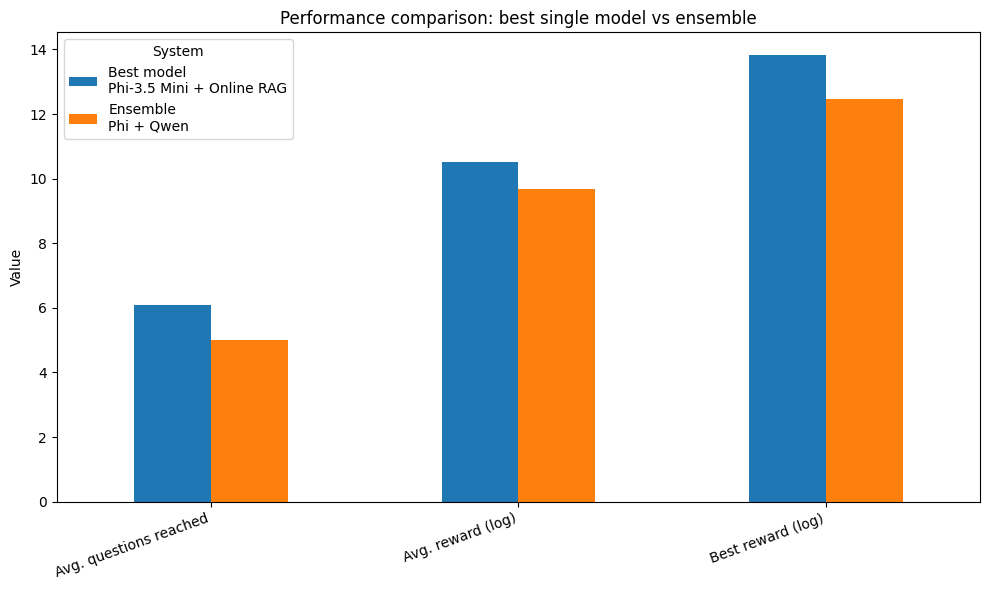

In [ ]:
performance_metrics = [
    "average_questions_reached",
    "average_final_earned_amount",
    "best_final_earned_amount",
]

performance_labels = [
    "Avg. questions reached",
    "Avg. final reward",
    "Best final reward",
]

plot_perf = comparison_table[
    ["comparison_name"] + performance_metrics
].copy()

plot_perf["log_average_final_earned_amount"] = np.log1p(
    plot_perf["average_final_earned_amount"]
)

plot_perf["log_best_final_earned_amount"] = np.log1p(
    plot_perf["best_final_earned_amount"]
)

plot_perf_final = plot_perf[
    [
        "comparison_name",
        "average_questions_reached",
        "log_average_final_earned_amount",
        "log_best_final_earned_amount",
    ]
].copy()

plot_perf_final.columns = [
    "comparison_name",
    "Avg. questions reached",
    "Avg. reward (log)",
    "Best reward (log)",
]

plot_perf_final = plot_perf_final.set_index("comparison_name")

ax = plot_perf_final.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Value")
plt.title("Performance comparison: best single model vs ensemble")
plt.xticks(rotation=20, ha="right")
plt.legend(title="System")
plt.tight_layout()

plt.savefig(
    "final_plot_best_model_vs_ensemble_performance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 12. Speech Mode

In the speech-mode experiment, the question and answer options are provided as audio instead of clean text. Therefore, an automatic speech recognition step is required before the language model can answer.

The pipeline is:

speech audio → ASR transcription → transcript cleaning → speech prompt → LLM answer → numeric option ID

This setup is more difficult than the normal text mode because the model receives noisy ASR transcripts. Names, option labels, numbers, and Entertainment-specific terms can be transcribed incorrectly, which may change the meaning of the question or the answer options.

### 12.1 ASR and Transcript Cleaning

The ASR output is cleaned before being passed to the language model. This is necessary because spoken options often include artifacts such as “Option A”, punctuation mistakes, filler words, or incorrect option labels.

The function `make_speech_text_question` converts the ASR transcript into a text-style question object using `SimpleNamespace`. This makes the speech question compatible with the existing text-based functions, which expect fields such as `question.text`, `question.options`, `question.id`, and `question.level`.


In [ ]:
%pip -q install faster-whisper

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.0/39.0 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 62.7 MB/s eta 0:00:00


In [ ]:
from faster_whisper import WhisperModel
import tempfile
from types import SimpleNamespace

asr_model_name = "small.en"

asr_model = WhisperModel(
    asr_model_name,
    device="cuda",
    compute_type="float16"
)


def transcribe_wav_bytes_with_metadata(audio_bytes):
    """
    The speech API returns audio as bytes.
    We temporarily save those bytes as a .wav file, then pass the path to Whisper.
    """

    start_time = time.time()

    with tempfile.NamedTemporaryFile(suffix=".wav", delete=True) as f:
        f.write(audio_bytes)
        f.flush()

        # This f.name is the temporary speech path.
        audio_temp_path = f.name

        segments, info = asr_model.transcribe(
            audio_temp_path,
            beam_size=3,
            language="en",
        )

        segments = list(segments)

    text = " ".join(
        segment.text.strip()
        for segment in segments
    ).strip()

    elapsed_seconds = time.time() - start_time

    avg_logprobs = [
        getattr(segment, "avg_logprob", None)
        for segment in segments
        if getattr(segment, "avg_logprob", None) is not None
    ]

    no_speech_probs = [
        getattr(segment, "no_speech_prob", None)
        for segment in segments
        if getattr(segment, "no_speech_prob", None) is not None
    ]

    return {
        "text": text,
        "asr_elapsed_seconds": elapsed_seconds,
        "asr_segment_count": len(segments),
        "asr_avg_logprob": (
            sum(avg_logprobs) / len(avg_logprobs)
            if avg_logprobs else None
        ),
        "asr_max_no_speech_prob": (
            max(no_speech_probs)
            if no_speech_probs else None
        ),
        "detected_language": getattr(info, "language", None),
        "audio_duration": getattr(info, "duration", None),
    }


def transcribe_wav_bytes(audio_bytes):
    return transcribe_wav_bytes_with_metadata(audio_bytes)["text"]

config.json: 0.00B [00:00, ?B/s]

model.bin:   0%|          | 0.00/484M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

In [ ]:
def make_speech_text_question(original_question, question_text, option_texts):
    """
    Convert transcribed speech question/options into a text-style question
    compatible with generate_answer().
    """

    original_options = getattr(original_question, "options", [])

    options = []

    for i, option_text in enumerate(option_texts):
        if i < len(original_options):
            option_id = original_options[i].id
        else:
            option_id = i

        options.append(
            SimpleNamespace(
                id=option_id,
                text=str(option_text).strip()
            )
        )

    text_question = SimpleNamespace(
        id=getattr(original_question, "id", None),
        level=getattr(original_question, "level", None),
        text=str(question_text).strip(),
        options=options,
    )

    return text_question

In [ ]:
def log_speech_result(
    game,
    original_question,
    text_question,
    prediction,
    result,
    system_name,
    question_number,
    question_asr,
    option_asr_metadata,
    reference_question_text=None,
    reference_option_texts=None,
):
    selected_option_text = None

    for option in text_question.options:
        if option.id == prediction["predicted_id"]:
            selected_option_text = option.text
            break

    total_response_time = prediction.get(
        "total_response_time",
        prediction.get("response_time", np.nan)
    )

    row = {
        "system_name": system_name,
        "session_id": game.session_id,

        "mode": "speech",
        "speech_mode": True,

        "level_before_answer": question_number,
        "api_question_level": getattr(original_question, "level", None),
        "question_id": getattr(original_question, "id", None),

        # Reference text if API provides it
        "question_reference": reference_question_text,
        "options_reference": json.dumps(reference_option_texts),

        # ASR transcripts
        "question_text": text_question.text,
        "question_transcript": text_question.text,
        "options_transcript": json.dumps([
            option.text
            for option in text_question.options
        ]),

        "question_length": len(text_question.text.split()) if text_question.text else 0,

        "options": json.dumps([
            {"id": option.id, "text": option.text}
            for option in text_question.options
        ]),

        "asr_model_name": asr_model_name,
        "question_asr_elapsed_seconds": question_asr.get("asr_elapsed_seconds", np.nan),
        "question_asr_avg_logprob": question_asr.get("asr_avg_logprob", np.nan),
        "question_asr_max_no_speech_prob": question_asr.get("asr_max_no_speech_prob", np.nan),
        "question_asr_segment_count": question_asr.get("asr_segment_count", np.nan),
        "question_audio_duration": question_asr.get("audio_duration", np.nan),
        "detected_language": question_asr.get("detected_language", None),
        "option_asr_metadata": json.dumps(option_asr_metadata),
        "selected_option_id": prediction["predicted_id"],
        "selected_option_text": selected_option_text,
        "model_name": globals().get("model_name", "unknown"),
        "prompt_type": prediction["prompt_type"],
        "prompt": prediction["prompt"],
        "raw_response": prediction["raw_response"],
        "valid_output": prediction.get("used_fallback", False) == False,
        "used_fallback": prediction.get("used_fallback", False),
        "answer_model_time": prediction.get("response_time", np.nan),
        "response_time": total_response_time,
        "under_30_seconds": total_response_time < 30,
        "correct": result.correct,
        "timed_out": result.timed_out,
        "game_over": result.game_over,
        "earned_amount": result.earned_amount,
        "retrieved_facts_text": prediction.get("retrieved_facts_text", ""),
        "rag_metadata": json.dumps(prediction.get("rag_metadata", {})),
        "retrieved_facts": json.dumps(prediction.get("retrieved_facts", [])),
        "option_confidences": json.dumps(prediction.get("option_confidences", {})),
        "confidence_score": prediction.get("confidence_score", np.nan),
        "confidence_margin": prediction.get("confidence_margin", np.nan),
    }

    experiment_log.append(row)

In [ ]:
def play_speech_prompt_game(
    comp_id,
    prompt_type="short",
    system_name="speech_system",
    delay_seconds=1.5,
    max_new_tokens=3,
):
    game = client.game.start(
        competition_id=comp_id,
        mode="speech"
    )

    print("Started speech game session:", game.session_id)
    print("System:", system_name)

    question_number = 0

    while game.in_progress:
        total_start_time = time.time()

        original_question = game.current_question

        if original_question is None:
            print("No active question.")
            break

        try:
            reference_question_text = getattr(original_question, "text", None)
            reference_option_texts = [
                getattr(option, "text", None)
                for option in getattr(original_question, "options", [])
            ]

            # Fetch and transcribe spoken question
            question_audio = game.fetch_audio_question()
            question_asr = transcribe_wav_bytes_with_metadata(question_audio)
            question_text = clean_question_transcript(question_asr["text"])

            # Fetch and transcribe spoken options
            option_texts = []
            option_asr_metadata = []

            for _ in range(4):
                option_audio = game.fetch_audio_option_next()
                option_asr = transcribe_wav_bytes_with_metadata(option_audio)

                option_texts.append(option_asr["text"])
                option_asr_metadata.append(option_asr)

            # Generic cleanup, no hard-coded ASR mistakes
            option_texts = clean_option_texts(option_texts)

            # Build text-style question
            text_question = make_speech_text_question(
                original_question=original_question,
                question_text=question_text,
                option_texts=option_texts,
            )

            # Answer with existing text pipeline
            prediction = generate_answer(
                text_question,
                prompt_type=prompt_type,
                max_new_tokens=max_new_tokens,
            )

            selected_id = prediction["predicted_id"]
            used_fallback = False

            if selected_id is None or pd.isna(selected_id):
                used_fallback = True
                selected_id = text_question.options[0].id
                prediction["predicted_id"] = selected_id

            prediction["used_fallback"] = used_fallback

            # Submit answer
            result = game.answer(selected_id)

            total_elapsed_seconds = time.time() - total_start_time
            prediction["total_response_time"] = total_elapsed_seconds

            print("\nQuestion transcript:")
            print(question_text)

            print("Options transcript:")
            for i, opt in enumerate(option_texts):
                print(f"{i}. {opt}")

            print(
                f"Level {question_number} | "
                f"api_level={getattr(original_question, 'level', None)} | "
                f"submitted={selected_id} | "
                f"correct={result.correct} | "
                f"asr_question_time={question_asr['asr_elapsed_seconds']:.2f}s | "
                f"llm_time={prediction['response_time']:.2f}s | "
                f"total_time={total_elapsed_seconds:.2f}s"
            )

            # Log
            log_speech_result(
                game=game,
                original_question=original_question,
                text_question=text_question,
                prediction=prediction,
                result=result,
                system_name=system_name,
                question_number=question_number,
                question_asr=question_asr,
                option_asr_metadata=option_asr_metadata,
                reference_question_text=reference_question_text,
                reference_option_texts=reference_option_texts,
            )

            if result.game_over:
                print("Game ended.")
                break

            question_number += 1
            time.sleep(delay_seconds)

        except TimeoutError as e:
            print("Timed out:", e)
            break

        except RateLimitError as e:
            print("Rate limited:", e)
            time.sleep(5)

        except GameError as e:
            print("Game error:", e)
            break

        except Exception as e:
            print("Speech pipeline error:", e)
            break

    return game

In [ ]:
def benchmark_speech_prompt(
    prompt_type,
    n_runs=3,
    delay_seconds=1.5,
    model_label="speech_model",
    max_new_tokens=3,
):
    all_runs = []

    for run_id in range(n_runs):
        print(
            f"Running SPEECH model={model_label}, "
            f"prompt={prompt_type}, run {run_id + 1}/{n_runs}"
        )

        global experiment_log
        experiment_log = []

        system_name = f"{model_label}_{prompt_type}_speech"

        play_speech_prompt_game(
            comp_id=comp_id,
            prompt_type=prompt_type,
            system_name=system_name,
            delay_seconds=delay_seconds,
            max_new_tokens=max_new_tokens,
        )

        df_run = pd.DataFrame(experiment_log)

        if len(df_run) == 0:
            continue

        df_run["run_id"] = run_id + 1
        df_run["prompt_type"] = prompt_type
        df_run["system_name"] = system_name
        df_run["model_label"] = model_label
        df_run["model_name"] = globals().get("model_name", "unknown")
        df_run["asr_model_name"] = asr_model_name

        all_runs.append(df_run)

    return pd.concat(all_runs, ignore_index=True) if all_runs else pd.DataFrame()

In [ ]:
def summarise_speech_results(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()

    summary = df.groupby("system_name").agg(
        runs=("run_id", "nunique"),
        total_questions=("question_id", "count"),
        average_final_earned_amount=("earned_amount", "mean"),
        best_final_earned_amount=("earned_amount", "max"),

        average_question_asr_time=("question_asr_elapsed_seconds", "mean"),
        average_answer_model_time=("answer_model_time", "mean"),
        average_total_response_time=("response_time", "mean"),
        max_total_response_time=("response_time", "max"),

        under_30_seconds_rate=("under_30_seconds", "mean"),
        valid_output_rate=("valid_output", "mean"),
    ).reset_index()

    summary["average_questions_reached"] = (
        summary["total_questions"] / summary["runs"].replace(0, np.nan)
    )

    return summary.sort_values("average_questions_reached", ascending=False)

#### 12.1.1Manual Speech API Test
Before running full speech benchmarks, a manual speech API test is performed. This test fetches one spoken question and its four spoken options, transcribes them with the ASR model, and prints the resulting text.


In [ ]:
game = client.game.start(
    competition_id=comp_id,
    mode="speech"
)

question_audio = game.fetch_audio_question()
question_asr = transcribe_wav_bytes_with_metadata(question_audio)
question_text = question_asr["text"]

option_texts = []
option_asr_metadata = []

for i in range(4):
    option_audio = game.fetch_audio_option_next()
    option_asr = transcribe_wav_bytes_with_metadata(option_audio)
    option_texts.append(option_asr["text"])
    option_asr_metadata.append(option_asr)

print("Question:", question_text)
print("Options:", option_texts)
print("Question ASR metadata:", question_asr)

Question: What term describes Ridley Scott's approach to visual storytelling? Often characterized by detailed set designs and atmospheric lighting?
Options: ['Option A. Stylistic!', 'Option B naturalistic', 'option C abstract', 'Topps in D Minimalist']
Question ASR metadata: {'text': "What term describes Ridley Scott's approach to visual storytelling? Often characterized by detailed set designs and atmospheric lighting?", 'asr_elapsed_seconds': 2.206308126449585, 'asr_segment_count': 2, 'asr_avg_logprob': -0.21709735290362284, 'asr_max_no_speech_prob': 0.00498199462890625, 'detected_language': 'en', 'audio_duration': 8.32}


### 12.2 ASR Transcript Cleaning

The goal of this section is to remove generic option-label noise without hard-coding specific answers or names.

The cleaning functions remove prefixes such as `Option A`, `A)`, or `B:` and normalize whitespace and punctuation. This keeps the approach general and avoids manually fixing specific ASR mistakes.

In [ ]:
def clean_asr_text_basic(text):
    text = str(text or "").strip()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"\s+([,.:;!?])", r"\1", text)
    return text.strip()


def remove_option_prefix(option_text):
    text = clean_asr_text_basic(option_text)

    if not text:
        return text

    # Remove standard labels only:
    # Option A. / Option B, / A) / B:
    text = re.sub(
        r"^\s*(option|choice|answer)?\s*[a-d]\s*[\)\].,:;-]?\s*",
        "",
        text,
        flags=re.IGNORECASE
    ).strip()

    return clean_asr_text_basic(text)


def clean_question_transcript(question_text):
    return clean_asr_text_basic(question_text)


def clean_option_texts(option_texts):
    return [remove_option_prefix(option_text) for option_text in option_texts]

### 12.3 Speech game with Qwen 1.5B & Whisper

The first speech experiment uses Qwen 1.5B with the existing short prompt. This provides a baseline for speech mode before adding a speech-specific prompt.

In [ ]:
short_speech_qwen_1_5b = []

short_speech_qwen_1_5b = benchmark_speech_prompt(
    prompt_type="short",
    n_runs=10,
    delay_seconds=1.5,
    model_label="qwen_1_5b",
    max_new_tokens=3,
)

Running SPEECH model=qwen_1_5b, prompt=short, run 1/10
Started speech game session: 367706
System: qwen_1_5b_short_speech


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What was the significance of the name change from starfish to coldplay?
Options transcript:
0. it was chosen to avoid confusion with another band
1. It reflected the band's musical style and aspirations.
2. It was a decision made to honor a fan's suggestion.
3. It was a marketing strategy to make the band name more memorable.
Level 0 | api_level=0 | submitted=1 | correct=True | asr_question_time=2.33s | llm_time=0.28s | total_time=10.69s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
How does the film setting Island Nublar differ from the real world locations considered for filming?
Options transcript:
0. Thesla Nublar was filmed in Costa Rica?
1. Isla Nublar was filmed in Canada.
2. Iceland New Blar was filmed in Mexico
3. Topshin D, Isla Nublar was filmed in Hawaii.
Level 1 | api_level=0 | submitted=0 | correct=False | asr_question_time=0.72s | llm_time=0.38s | total_time=8.68s
Game ended.
Running SPEECH model=qwen_1_5b, prompt=short, run 2/10
Started speech game session: 367722
System: qwen_1_5b_short_speech


...


Question transcript:
Which of the following best describes the relationship between Batman and the Joker in the Dark Knight?
Options transcript:
0. Batman and the Joker are allies.
1. Batman and the Joker are friends.
2. Batman and the Joker are mortal enemies.
3. Batman and the Joker are romantic partners.
Level 4 | api_level=0 | submitted=2 | correct=True | asr_question_time=0.84s | llm_time=0.15s | total_time=5.80s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
Which band member was initially hesitant to play drums for Coldplay and later played instead?
Options transcript:
0. will champion
1. Maja bad goob abi
2. Johnny Buckland.
3. Topson D. Chris Morton.
Level 5 | api_level=0 | submitted=3 | correct=False | asr_question_time=0.69s | llm_time=0.20s | total_time=5.74s
Game ended.
Running SPEECH model=qwen_1_5b, prompt=short, run 10/10
Started speech game session: 367783
System: qwen_1_5b_short_speech


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What event marked the beginning of Ella Fitzgerald's solo career?
Options transcript:
0. taking over the Chick Web Orchestra after Webb's death.
1. her first appearance at the Apollo theater
2. her performance with the Chick Web Orchestra at Yale University.
3. Topson D her solo performance at the Roseland Ballroom.
Level 0 | api_level=0 | submitted=3 | correct=False | asr_question_time=0.77s | llm_time=0.16s | total_time=5.91s
Game ended.



The short speech prompt was not enough for the speech setting because the ASR transcripts often contained noisy or distorted option text. Examples include broken labels such as `Topshin D` and `Topson D`, incorrect names such as `Iceland New Blar`, and long meaningless ASR fragments. These errors sometimes caused the model to choose the wrong option even when the intended answer was present. :contentReference[oaicite:2]{index=2}

Therefore, a new speech-specific prompt was needed

In [ ]:
display(summarise_results(short_speech_qwen_1_5b))

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
0,qwen_1_5b_short_speech,10,2.3,221.73913,1000,6.358551,10.692961,1.0


In [ ]:
short_speech_qwen_1_5b.to_csv("Ent_speech_qwen_1_5b_short.csv", index=False)

### 12.4 Qwen 1.5B with Speech-Specific Prompt

After observing ASR noise in the baseline speech experiment, a speech-specific prompt is introduced. This prompt tells the model that the question and options were transcribed from audio and may contain ASR mistakes.

The prompt asks the model to focus on the intended meaning, ignore meaningless fragments, and return only one numeric option ID.

In [ ]:
def format_options_speech(question):
    lines = []

    for option in question.options:
        cleaned_text = remove_option_prefix(option.text)
        lines.append(f"{option.id}. {cleaned_text}")

    return "\n".join(lines)


def build_prompt_speech_short(question):
    return f"""
You are answering a spoken entertainment multiple-choice question.
The question and options were transcribed from audio and may contain ASR mistakes, especially in names.
Choose the option that best matches the intended meaning.
Return only one numeric option ID.

Question:
{clean_question_transcript(question.text)}

Options:
{format_options_speech(question)}

Valid option IDs: {valid_option_ids_text(question)}
Answer:
""".strip()

In [ ]:
load_local_causal_lm("Qwen/Qwen2.5-1.5B-Instruct")

speech_qwen_p_1_5b = []

speech_qwen_p_1_5b = benchmark_speech_prompt(
    prompt_type="speech_short",
    n_runs=10,
    delay_seconds=1.5,
    model_label="qwen_1_5b",
    max_new_tokens=3,
)

Loading model: Qwen/Qwen2.5-1.5B-Instruct


Device set to use cuda:0


Loaded model: Qwen/Qwen2.5-1.5B-Instruct
Running SPEECH model=qwen_1_5b, prompt=speech_short, run 1/10
Started speech game session: 367521
System: qwen_1_5b_speech_short_speech


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What is the primary reason Prince changed his name to an unpronounceable symbol in 1993?
Options transcript:
0. to create a new stage name
1. to join a secret society.
2. to assert artistic control over his music
3. to avoid taxes.
Level 0 | api_level=0 | submitted=2 | correct=True | asr_question_time=1.71s | llm_time=0.57s | total_time=10.91s


...


Question transcript:
Which term best describes Alfred Hitchcock's technique of making viewers feel like voyeurs in his films?
Options transcript:
0. suspense.
1. realism
2. mise en sin
3. cinematic voyeurism
Level 1 | api_level=0 | submitted=3 | correct=True | asr_question_time=0.72s | llm_time=0.19s | total_time=5.94s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What was the primary musical influence on Elvis Presley's early career?
Options transcript:
0. rock and roll
1. country music! Heh heh heh heh heh heh heh heh heh
2. blues
3. gospel music
Level 2 | api_level=0 | submitted=1 | correct=False | asr_question_time=0.65s | llm_time=0.16s | total_time=5.58s
Game ended.
Running SPEECH model=qwen_1_5b, prompt=speech_short, run 10/10
Started speech game session: 367593
System: qwen_1_5b_speech_short_speech


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What event caused Forrest Gump to become a fast runner and eventually a football star?
Options transcript:
0. a sports injury.
1. breaking his leg braces during a fight.
2. a race against a classmate.
3. Topson D training with a professional coach.
Level 0 | api_level=0 | submitted=3 | correct=False | asr_question_time=0.60s | llm_time=0.19s | total_time=5.51s
Game ended.


A speech-specific prompt was added to make the model more robust to ASR noise. After this change, Qwen 1.5B improved from **2.5** to **4.3 average questions reached**, and the best final earned amount increased from **2,000** to **128,000**.

In [ ]:
display(summarise_results(speech_qwen_p_1_5b))

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
0,qwen_1_5b_speech_short_speech,10,4.3,9300.0,128000,6.092577,10.906837,1.0


In [ ]:
speech_qwen_p_1_5b.to_csv("Ent_speech_qwen_1_5b_prompt.csv", index=False)

### 12.5 Qwen 3B Speech Experiment

This experiment tests whether a larger Qwen model improves speech-mode performance. Qwen 3B is evaluated with both a normal few-shot prompt and the speech-specific prompt.

The goal is to compare whether increasing model size helps when the input is noisy, or whether ASR errors remain the main bottleneck.

In [ ]:
load_local_causal_lm("Qwen/Qwen2.5-3B-Instruct")

Loading model: Qwen/Qwen2.5-3B-Instruct


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Device set to use cuda:0


Loaded model: Qwen/Qwen2.5-3B-Instruct


(Qwen2ForCausalLM(
   (model): Qwen2Model(
     (embed_tokens): Embedding(151936, 2048)
     (layers): ModuleList(
       (0-35): 36 x Qwen2DecoderLayer(
         (self_attn): Qwen2Attention(
           (q_proj): Linear(in_features=2048, out_features=2048, bias=True)
           (k_proj): Linear(in_features=2048, out_features=256, bias=True)
           (v_proj): Linear(in_features=2048, out_features=256, bias=True)
           (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
         )
         (mlp): Qwen2MLP(
           (gate_proj): Linear(in_features=2048, out_features=11008, bias=False)
           (up_proj): Linear(in_features=2048, out_features=11008, bias=False)
           (down_proj): Linear(in_features=11008, out_features=2048, bias=False)
           (act_fn): SiLU()
         )
         (input_layernorm): Qwen2RMSNorm((2048,), eps=1e-06)
         (post_attention_layernorm): Qwen2RMSNorm((2048,), eps=1e-06)
       )
     )
     (norm): Qwen2RMSNorm((2048,), eps=1e

In [ ]:
df_speech_qwen_3b = []

df_speech_qwen_3b = benchmark_speech_prompt(
    prompt_type="few_shot",
    n_runs=10,
    delay_seconds=1.5,
    model_label="qwen_3b",
    max_new_tokens=3,
)


Running SPEECH model=qwen_3b, prompt=few_shot, run 1/10
Started speech game session: 368520
System: qwen_3b_few_shot_speech


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What is the primary reason Joey Tribbiani pursued acting as a career?
Options transcript:
0. to become a pipe fitter like his father.
1. To work as a model
2. to escape his father's profession
3. to follow in his father's footsteps
Level 0 | api_level=0 | submitted=3 | correct=False | asr_question_time=0.80s | llm_time=0.26s | total_time=4.04s
Game ended.
Running SPEECH model=qwen_3b, prompt=few_shot, run 2/10
Started speech game session: 368522
System: qwen_3b_few_shot_speech


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
Which turned best to P.E.E.E.E.E.T.A.R.STO and to IT. About Konon-Mamanya? Buh-bo where the will be the Elite Bank.
Options transcript:
0. pay the movement.
1. five phenomenon.
2. Strobosgopic Disc!
3. persistence of vision.
Level 0 | api_level=0 | submitted=3 | correct=True | asr_question_time=3.50s | llm_time=0.25s | total_time=6.37s


...


Question transcript:
Which of the following best describes Mariah Carey's early music style?
Options transcript:
0. alternative rock!
1. pop in adult contemporary ballads.
2. hip-hop and rap
3. electronic dance music
Level 0 | api_level=0 | submitted=1 | correct=True | asr_question_time=0.57s | llm_time=0.24s | total_time=3.62s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What term describes the juxtaposition of two seemingly unrelated images in a meme format?
Options transcript:
0. Mosaic
1. montage
2. meme!
3. Topson D? Ash up?
Level 1 | api_level=0 | submitted=0 | correct=False | asr_question_time=0.67s | llm_time=0.24s | total_time=3.45s
Game ended.
Running SPEECH model=qwen_3b, prompt=few_shot, run 10/10
Started speech game session: 368558
System: qwen_3b_few_shot_speech


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What is the primary concept explored in Inception that involves entering and manipulating the subconscious mind of another person?
Options transcript:
0. Neuroimplantation
1. Lucid Dreaming.
2. memory extraction
3. obson D. Virtual Reality.
Level 0 | api_level=0 | submitted=2 | correct=False | asr_question_time=0.61s | llm_time=0.27s | total_time=3.74s
Game ended.


In [ ]:
display(summarise_results(df_speech_qwen_3b))

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
0,qwen_3b_few_shot_speech,10,2.3,156.521739,300,3.876399,6.366773,1.0


In [ ]:
df_speech_qwen_3b.to_csv("Ent_speech_qwen_3b_few_shot.csv", index=False)

In [ ]:
df_speech_qwen_3b = []

df_speech_qwen_3b = benchmark_speech_prompt(
    prompt_type="speech_short",
    n_runs=10,
    delay_seconds=1.5,
    model_label="qwen_3b",
    max_new_tokens=2,
)


Running SPEECH model=qwen_3b, prompt=speech_short, run 1/10
Started speech game session: 368573
System: qwen_3b_speech_short_speech


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What is the fundamental principle behind the formation of Radiohead?
Options transcript:
0. a shared interest in jazz and avant-garde music from their music teacher
1. a mutual love for grunge music in the early 1990s.
2. a contest to form the best band at their school.
3. a chance meeting between band members at a music festival
Level 0 | api_level=0 | submitted=0 | correct=True | asr_question_time=0.63s | llm_time=0.19s | total_time=3.66s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
Which of the following best describes Prince's influence on modern popular music?
Options transcript:
0. He is considered one of the most influential musicians of his generation.
1. He was primarily influential in classical music
2. He was only influential in the 1980s
3. he had little impact on the music industry.
Level 1 | api_level=0 | submitted=0 | correct=True | asr_question_time=0.62s | llm_time=0.19s | total_time=3.54s


...


Question transcript:
Which of the following best describes the relationship between Leonardo DiCaprio and Martin Scorsese?
Options transcript:
0. They often disagree on the direction of their films.
1. they have a long-standing professional and personal friendship.
2. they have never worked together on a film.
3. They are distant and rarely work together.
Level 1 | api_level=0 | submitted=1 | correct=True | asr_question_time=0.67s | llm_time=0.20s | total_time=3.67s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What is the primary theme of Forrest Gump's life story as portrayed in the film?
Options transcript:
0. American history and personal growth.
1. business and entrepreneurship.
2. love and romance.
3. war and military strategy.
Level 2 | api_level=0 | submitted=0 | correct=True | asr_question_time=0.76s | llm_time=0.16s | total_time=4.10s


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Question transcript:
What is the fundamental principle of invincible that drives the plot and character development?
Options transcript:
0. balancing personal life and superhero duties.
1. the pursuit of revenge.
2. the quest for power
3. the search for a superpower origin
Level 3 | api_level=0 | submitted=1 | correct=False | asr_question_time=0.65s | llm_time=0.16s | total_time=3.49s
Game ended.


In [ ]:
display(summarise_results(df_speech_qwen_3b))

,system_name,runs,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
0,qwen_3b_speech_short_speech,10,2.8,950.0,8000,3.984406,9.462984,1.0


In [ ]:
df_speech_qwen_3b.to_csv("Ent_speech_qwen_3b_short.csv", index=False)

The speech experiments show that audio-based answering is more difficult than clean text answering. The main reason is that the language model depends on the ASR transcript. If the ASR system distorts an actor name, movie title, song title, or answer option, the LLM may receive incomplete or misleading information.

The speech-specific prompt was introduced to reduce this problem by explicitly telling the model to tolerate ASR mistakes and ignore meaningless fragments. However, ASR quality and transcript cleaning remain important parts of the full pipeline.

### 12.6 Error Analysis

In [ ]:
def safe_json_loads(x):
    try:
        if pd.isna(x):
            return []
        if isinstance(x, list):
            return x
        return json.loads(x)
    except Exception:
        return []


def normalize_text_for_error(text):
    text = str(text or "").lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text


def has_repetition_noise(text):
    text = normalize_text_for_error(text)
    words = re.findall(r"[a-zA-Z']+", text)

    if len(words) < 4:
        return False

    # repeated same word many times: ha ha ha ha...
    repeated_count = 0
    for i in range(1, len(words)):
        if words[i] == words[i - 1]:
            repeated_count += 1

    return repeated_count >= 3


def is_noisy_asr_text(text):
    text = normalize_text_for_error(text)

    if not text:
        return True

    noisy_markers = [
        "topson",
        "topshin",
        "topshun",
        "top shun",
        "top 10",
        "tops and",
        "uh",
        "hmm",
        "ha ha",
        "okay okay",
    ]

    if any(marker in text for marker in noisy_markers):
        return True

    if has_repetition_noise(text):
        return True

    # Very long option transcript is often ASR hallucination/noise
    if len(text.split()) > 35:
        return True

    return False


def option_texts_from_row(row):
    options = safe_json_loads(row.get("options", "[]"))

    texts = []
    for opt in options:
        if isinstance(opt, dict):
            texts.append(str(opt.get("text", "")))

    return texts


def selected_option_text_from_row(row):
    selected_text = row.get("selected_option_text", "")

    if selected_text and not pd.isna(selected_text):
        return str(selected_text)

    selected_id = row.get("selected_option_id", None)
    options = safe_json_loads(row.get("options", "[]"))

    for opt in options:
        if isinstance(opt, dict) and opt.get("id") == selected_id:
            return str(opt.get("text", ""))

    return ""


def output_has_format_violation(raw_response):
    raw = str(raw_response or "").strip()

    if raw == "":
        return True

    # valid answer should be only one number
    return not bool(re.fullmatch(r"\d+", raw))


def classify_speech_error(row):
    """
    Classify errors in speech mode.
    This separates output-format problems, ASR-related problems,
    and normal wrong option selection.
    """

    correct = row.get("correct", None)
    raw_response = row.get("raw_response", "")
    selected_id = row.get("selected_option_id", None)
    valid_output = row.get("valid_output", True)
    timed_out = row.get("timed_out", False)

    question_text = row.get("question_text", "")
    selected_option_text = selected_option_text_from_row(row)
    option_texts = option_texts_from_row(row)

    confidence = row.get("confidence_score", np.nan)
    margin = row.get("confidence_margin", np.nan)

    # Correct answers are not errors
    if correct == True:
        return "correct"

    # Timeout
    if timed_out == True:
        return "timeout"

    # Empty or invalid output
    if raw_response is None or str(raw_response).strip() == "":
        return "empty_response"

    if selected_id is None or pd.isna(selected_id) or valid_output == False:
        return "invalid_or_unparsed_output"

    # Format violation
    if output_has_format_violation(raw_response):
        return "wrong_option_with_format_violation"

    # ASR noise in selected option
    if is_noisy_asr_text(selected_option_text):
        return "selected_noisy_asr_option"

    # ASR noise somewhere in options
    noisy_options = [txt for txt in option_texts if is_noisy_asr_text(txt)]
    if len(noisy_options) > 0:
        return "wrong_answer_with_asr_noisy_options"

    # ASR noise in question
    if is_noisy_asr_text(question_text):
        return "wrong_answer_with_asr_noisy_question"

    # High-confidence wrong answer
    if (
        not pd.isna(confidence)
        and not pd.isna(margin)
        and confidence >= 0.75
        and margin >= 0.50
    ):
        return "high_confidence_wrong_answer"

    # Normal wrong option
    return "wrong_option_selected"

In [ ]:
speech_files = {
    "df_speech_qwen_1_5b_sp": "/content/Ent_speech_qwen_1_5b_prompt.csv",
    "df_speech_qwen_1_5b_short": "/content/Ent_speech_qwen_1_5b_short.csv",
    "df_speech_qwen_3b_few_shot": "/content/Ent_speech_qwen_3b_few_shot.csv",
    "df_speech_qwen_3b_short": "/content/Ent_speech_qwen_3b_short.csv",
}

speech_dfs = {}

for label, path in speech_files.items():
    if os.path.exists(path):
        df = pd.read_csv(path)
        df["speech_system_label"] = label
        speech_dfs[label] = df
        print(f"Loaded {label}: {path} | rows={len(df)}")
    else:
        print(f"File not found: {path}")

df_speech_all = pd.concat(
    speech_dfs.values(),
    ignore_index=True
)

display(df_speech_all.head())
print(df_speech_all.shape)

Loaded df_speech_qwen_1_5b_sp: /content/Ent_speech_qwen_1_5b_prompt.csv | rows=43
Loaded df_speech_qwen_1_5b_short: /content/Ent_speech_qwen_1_5b_short.csv | rows=23
Loaded df_speech_qwen_3b_few_shot: /content/Ent_speech_qwen_3b_few_shot.csv | rows=23
Loaded df_speech_qwen_3b_short: /content/Ent_speech_qwen_3b_short.csv | rows=28


,system_name,session_id,mode,speech_mode,level_before_answer,api_question_level,question_id,question_reference,options_reference,question_text,...,earned_amount,retrieved_facts_text,rag_metadata,retrieved_facts,option_confidences,confidence_score,confidence_margin,run_id,model_label,speech_system_label
0,qwen_1_5b_speech_short_speech,367521,speech,True,0,0,629,NaN,"[null, null, null, null]",What is the primary reason Prince changed his ...,...,100,NaN,{},[],"{""0"": 0.23095703125, ""1"": 0.210205078125, ""2"":...",0.257568,-0.043701,1,qwen_1_5b,df_speech_qwen_1_5b_sp
1,qwen_1_5b_speech_short_speech,367521,speech,True,1,0,23,NaN,"[null, null, null, null]",What was the significance of the name change f...,...,200,NaN,{},[],"{""0"": 0.001995086669921875, ""1"": 0.03765869140...",0.570801,0.181396,1,qwen_1_5b,df_speech_qwen_1_5b_sp
2,qwen_1_5b_speech_short_speech,367521,speech,True,2,0,694,NaN,"[null, null, null, null]","Hahaha, which of the following best describes ...",...,300,NaN,{},[],"{""0"": 0.755859375, ""1"": 0.13037109375, ""2"": 0....",0.755859,0.625488,1,qwen_1_5b,df_speech_qwen_1_5b_sp
3,qwen_1_5b_speech_short_speech,367521,speech,True,3,0,265,NaN,"[null, null, null, null]",Which of the following best describes the rela...,...,500,NaN,{},[],"{""0"": 0.00896453857421875, ""1"": 0.096374511718...",0.832520,0.736145,1,qwen_1_5b,df_speech_qwen_1_5b_sp
4,qwen_1_5b_speech_short_speech,367521,speech,True,4,0,477,NaN,"[null, null, null, null]",Which of the following best describes Charlie ...,...,1000,NaN,{},[],"{""0"": 0.00330352783203125, ""1"": 0.067932128906...",0.860352,0.791931,1,qwen_1_5b,df_speech_qwen_1_5b_sp


(117, 46)


In [ ]:
df_speech_errors = df_speech_all.copy()

df_speech_errors["speech_error_type"] = df_speech_errors.apply(
    classify_speech_error,
    axis=1
)

display(
    df_speech_errors[
        [
            "system_name",
            "run_id",
            "level_before_answer",
            "question_text",
            "selected_option_id",
            "selected_option_text",
            "raw_response",
            "correct",
            "speech_error_type",
        ]
    ].head(30)
)

,system_name,run_id,level_before_answer,question_text,selected_option_id,selected_option_text,raw_response,correct,speech_error_type
0,qwen_1_5b_speech_short_speech,1,0,What is the primary reason Prince changed his ...,2,to assert artistic control over his music,2,True,correct
1,qwen_1_5b_speech_short_speech,1,1,What was the significance of the name change f...,3,It reflected the band's musical style and aspi...,3,True,correct
2,qwen_1_5b_speech_short_speech,1,2,"Hahaha, which of the following best describes ...",0,raw and emotive,0,True,correct
3,qwen_1_5b_speech_short_speech,1,3,Which of the following best describes the rela...,3,he was the band's unofficial leader.,3,True,correct
4,qwen_1_5b_speech_short_speech,1,4,Which of the following best describes Charlie ...,2,"a poor, homeless, and somewhat bumbling figure.",2,True,correct
5,qwen_1_5b_speech_short_speech,1,5,What was the significance of the Redlands inci...,3,it highlighted the legal and personal struggle...,3,True,correct
6,qwen_1_5b_speech_short_speech,1,6,Which of the following best describes the narr...,2,non-linear and interwoven.,2,True,correct
7,qwen_1_5b_speech_short_speech,1,7,What is the primary visual style characteristi...,2,minimalistic and low-key lighting,2,False,wrong_option_selected
8,qwen_1_5b_speech_short_speech,2,0,Which of the following best describes the conn...,2,his music often reflects personal experiences ...,2,True,correct
9,qwen_1_5b_speech_short_speech,2,1,What was the fundamental principle behind Paul...,1,using perfect pitch and instinct.,1,True,correct


In [ ]:
speech_error_summary = (
    df_speech_errors[df_speech_errors["correct"] == False]
    .groupby(["system_name", "speech_error_type"], dropna=False)
    .agg(
        error_count=("question_id", "count"),
        avg_response_time=("response_time", "mean"),
    )
    .reset_index()
)

speech_error_summary["total_errors"] = (
    speech_error_summary
    .groupby("system_name")["error_count"]
    .transform("sum")
)

speech_error_summary["error_percentage"] = (
    100
    * speech_error_summary["error_count"]
    / speech_error_summary["total_errors"]
).round(2)

speech_error_summary = speech_error_summary.sort_values(
    ["system_name", "error_count"],
    ascending=[True, False]
)

display(speech_error_summary)

,system_name,speech_error_type,error_count,avg_response_time,total_errors,error_percentage
0,qwen_1_5b_short_speech,high_confidence_wrong_answer,3,5.683445,10,30.0
1,qwen_1_5b_short_speech,selected_noisy_asr_option,2,5.824797,10,20.0
2,qwen_1_5b_short_speech,wrong_answer_with_asr_noisy_options,2,7.180042,10,20.0
3,qwen_1_5b_short_speech,wrong_option_selected,2,6.217500,10,20.0
4,qwen_1_5b_short_speech,wrong_option_with_format_violation,1,5.733960,10,10.0
7,qwen_1_5b_speech_short_speech,wrong_option_selected,5,5.867293,10,50.0
5,qwen_1_5b_speech_short_speech,selected_noisy_asr_option,4,5.581538,10,40.0
6,qwen_1_5b_speech_short_speech,wrong_answer_with_asr_noisy_options,1,5.953811,10,10.0
8,qwen_3b_few_shot_speech,high_confidence_wrong_answer,3,3.787869,10,30.0
9,qwen_3b_few_shot_speech,selected_noisy_asr_option,2,4.000176,10,20.0


The speech error distribution shows that speech-mode errors were not only caused by the language model, but also by ASR noise.

For **Qwen 1.5B**, the speech-specific prompt reduced high-confidence wrong answers and removed format violations. However, ASR-related errors remained, especially when noisy option text caused the model to select the wrong answer.

For **Qwen 3B**, the main issue was overconfidence. In the speech-specific prompt setting, most errors were high-confidence wrong answers, meaning the model often selected incorrect options with strong confidence.

The error analysis also shows that changing the prompt reduced noise-related errors for both models.  

In [ ]:
speech_error_pivot = speech_error_summary.pivot_table(
    index="system_name",
    columns="speech_error_type",
    values="error_count",
    fill_value=0
).reset_index()

speech_error_pivot["total_errors"] = speech_error_pivot.drop(
    columns=["system_name"]
).sum(axis=1)

display(speech_error_pivot)

speech_error_type,system_name,high_confidence_wrong_answer,selected_noisy_asr_option,wrong_answer_with_asr_noisy_options,wrong_option_selected,wrong_option_with_format_violation,total_errors
0,qwen_1_5b_short_speech,3.0,2.0,2.0,2.0,1.0,10.0
1,qwen_1_5b_speech_short_speech,0.0,4.0,1.0,5.0,0.0,10.0
2,qwen_3b_few_shot_speech,3.0,2.0,2.0,1.0,2.0,10.0
3,qwen_3b_speech_short_speech,6.0,1.0,1.0,1.0,1.0,10.0


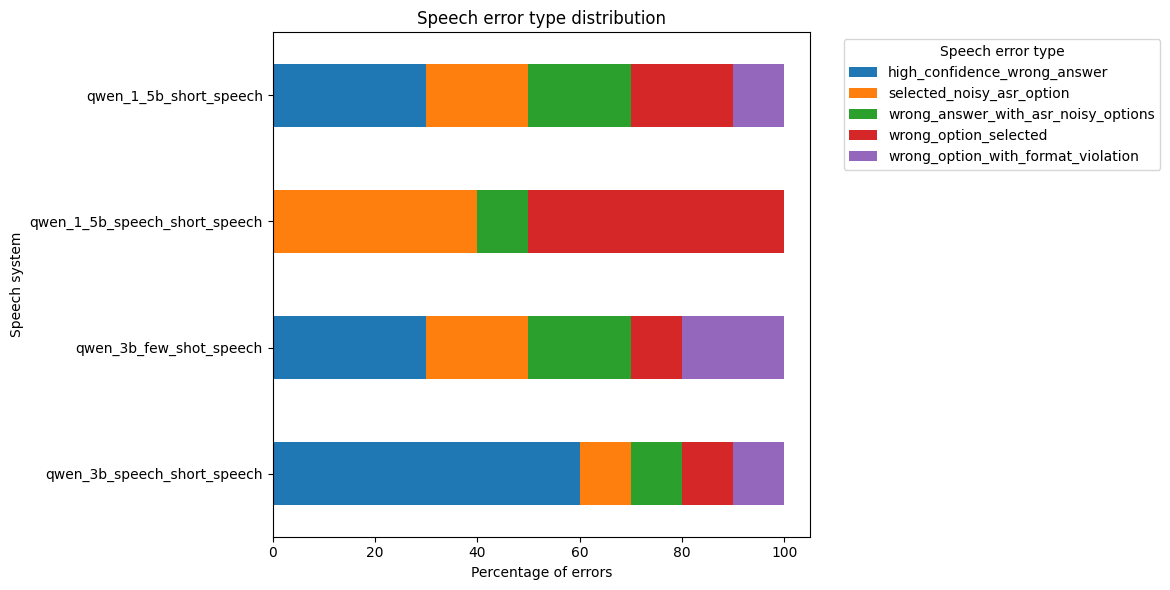

In [ ]:
plot_speech_errors = speech_error_summary.copy()

pivot_plot = plot_speech_errors.pivot_table(
    index="system_name",
    columns="speech_error_type",
    values="error_percentage",
    fill_value=0
)

pivot_plot = pivot_plot.iloc[::-1]

ax = pivot_plot.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 6)
)

plt.xlabel("Percentage of errors")
plt.ylabel("Speech system")
plt.title("Speech error type distribution")
plt.legend(
    title="Speech error type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()

plt.savefig(
    "final_plot_speech_error_type_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### 12.7 Text vs Speech Comparison

This section compares the best text-based systems with the speech-based systems. The goal is to measure the performance drop caused by ASR transcription and noisy spoken options.

In [ ]:
def summarise_loaded_speech_results(df):
    df = df.copy()

    time_col = "total_response_time" if "total_response_time" in df.columns else "response_time"

    summary = (
        df.groupby(["speech_system_label", "system_name"], dropna=False)
        .agg(
            runs=("run_id", "nunique"),
            total_questions=("question_id", "count"),
            correct_answers=("correct", "sum"),
            average_final_earned_amount=("earned_amount", "mean"),
            best_final_earned_amount=("earned_amount", "max"),
            average_response_time=(time_col, "mean"),
            max_response_time=(time_col, "max"),
            valid_output_rate=("valid_output", "mean"),
        )
        .reset_index()
    )

    summary["average_questions_reached"] = (
        summary["total_questions"] / summary["runs"].replace(0, pd.NA)
    )

    summary["average_correct_answers"] = (
        summary["correct_answers"] / summary["runs"].replace(0, pd.NA)
    )

    return summary.sort_values(
        ["average_questions_reached", "average_final_earned_amount"],
        ascending=[False, False]
    )

In [ ]:
speech_summaries = summarise_loaded_speech_results(df_speech_all)
speech_summaries["mode"] = "speech"

text_baseline = main_report_table[
    main_report_table["system_name"].isin([
        "qwen_1_5b_few_shot_antibias",
        "qwen_1_5b_short",
        "qwen_3b_offline_rag",
        "phi_3_5_min_online_rag",
    ])
].copy()

text_baseline["mode"] = "text"

comparison_cols = [
    "system_name",
    "average_questions_reached",
    "average_final_earned_amount",
    "best_final_earned_amount",
    "average_response_time",
    "valid_output_rate",
    "mode",
]

text_part = text_baseline[
    [c for c in comparison_cols if c in text_baseline.columns]
].copy()

speech_part = speech_summaries[
    [c for c in comparison_cols if c in speech_summaries.columns]
].copy()

comparison_speech_text = pd.concat(
    [text_part, speech_part],
    ignore_index=True
)


The comparison shows that text-based systems still performed better than speech-based systems. This is expected because text mode uses clean API text, while speech mode depends on noisy ASR transcripts.

The best speech system was **Qwen 1.5B with the speech-specific prompt**, reaching about **4.3 average questions**. This was better than the basic speech prompt and the Qwen 3B speech runs, showing that prompt design helped more than simply increasing model siz

In [ ]:
display(comparison_speech_text)

,system_name,average_questions_reached,average_final_earned_amount,best_final_earned_amount,average_response_time,valid_output_rate,mode
0,phi_3_5_min_online_rag,6.1,36932.786885,1024000,0.381278,1.0,text
1,qwen_1_5b_few_shot_antibias,5.1,9098.039216,128000,0.168151,1.0,text
2,qwen_3b_offline_rag,4.5,2446.666667,32000,0.271814,1.0,text
3,qwen_1_5b_short,2.8,457.142857,2000,0.499746,1.0,text
4,qwen_1_5b_speech_short_speech,4.3,9300.000000,128000,6.092577,1.0,speech
5,qwen_3b_speech_short_speech,2.8,950.000000,8000,3.984406,1.0,speech
6,qwen_1_5b_short_speech,2.3,221.739130,1000,6.358551,1.0,speech
7,qwen_3b_few_shot_speech,2.3,156.521739,300,3.876399,1.0,speech


In [ ]:
comparison_speech_text["display_name"] = comparison_speech_text["system_name"]

comparison_speech_text["display_name"] = comparison_speech_text["display_name"].str.replace(
    "qwen_1_5b_", "Qwen 1.5B | ", regex=False
).str.replace(
    "qwen_3b_", "Qwen 3B | ", regex=False
).str.replace(
    "phi_3_5_min_online_rag", "Phi-3.5 Mini | Online RAG", regex=False
).str.replace(
    "qwen_1_5b_few_shot_antibias", "Qwen 1.5B | Few-shot anti-bias", regex=False
).str.replace(
    "qwen_3b_offline_rag", "Qwen 3B | Offline RAG", regex=False
)

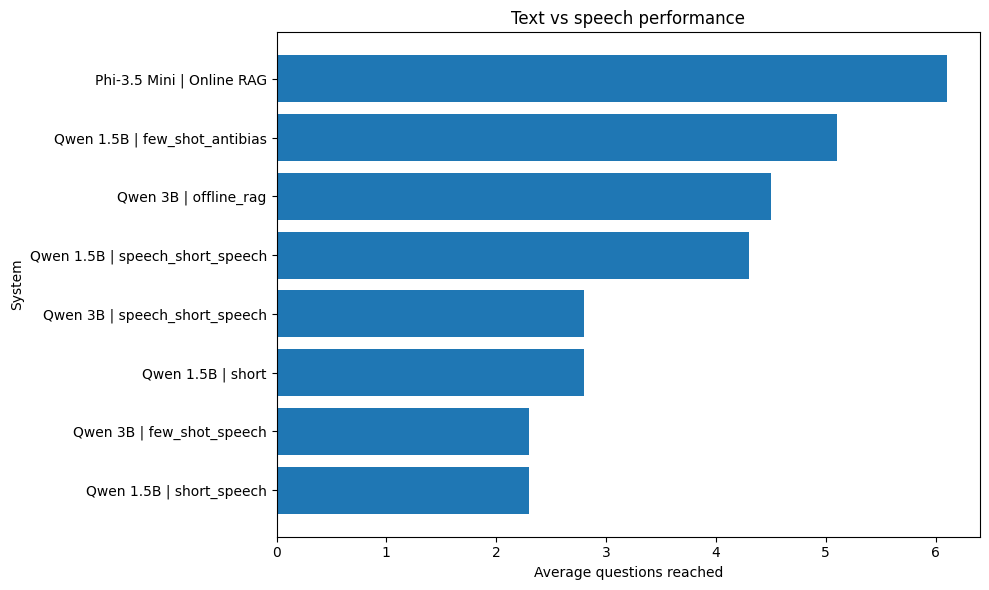

In [ ]:
plot_df = comparison_speech_text.sort_values(
    "average_questions_reached",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["display_name"],
    plot_df["average_questions_reached"]
)

plt.xlabel("Average questions reached")
plt.ylabel("System")
plt.title("Text vs speech performance")
plt.tight_layout()

plt.show()

## 13. Final Conclusion and Future Work

This project explored how different local open-weight language models perform on the PoliMillionaire Entertainment quiz task. We tested several approaches, including different model sizes, prompt designs, output constraints, retrieval-augmented generation, ensemble methods, and a speech-based pipeline. All models were run locally using Hugging Face/Transformers, without relying on a paid LLM API.

One of the main findings is that using a larger model does not automatically lead to better performance. Larger models such as Llama 3 8B and Mistral 7B were useful for comparison, but they did not consistently outperform smaller or medium-sized models. The best overall result came from **Phi-3.5 Mini with online RAG**, which reached **6.1 questions on average** and achieved the highest best final reward of **1,024,000**. This shows that a compact instruction-following model can perform very well when it is combined with useful and relevant external context.

Prompt design also had a major impact. Short and controlled outputs helped the models follow the required format and return only one numeric option ID. The anti-bias few-shot prompt was especially useful for Qwen 1.5B, making it one of the strongest non-RAG systems. This suggests that, in a multiple-choice QA task, prompt structure, output control, and reducing positional bias can be just as important as model size. However, reducing positional bias did not fully remove factual mistakes or high-confidence wrong answers.

RAG was helpful, but only when the retrieved facts were precise and directly relevant to the question. Phi-3.5 Mini benefited the most from RAG, while smaller models such as Qwen 1.5B did not always improve with retrieval. In many cases, search-based RAG returned facts that were related to the general topic but not useful enough for choosing the correct option. This sometimes added noise and distracted the model. For this reason, the project did not rely only on heavy live-search RAG. Offline facts and selective online retrieval were also tested. Overall, the results show that retrieval quality matters more than the amount of retrieved text.

Fine-tuning was not used in the final system. The goal of the project was to compare local prompting, retrieval, and model selection under limited resources. Also, the available game data was limited and dynamic, so fine-tuning on a small set of previous questions could easily lead to overfitting. Instead, prompt engineering, RAG, and ensemble methods were used as lighter and more reproducible alternatives. The reasoning-style model was also tested, but it did not provide a clear advantage, because this task required short numeric answers rather than long reasoning traces.

The error analysis showed that most remaining mistakes were not caused by invalid output format. The models usually returned valid numeric answers, but they often selected the wrong option. This suggests that many errors were caused by missing precise factual knowledge rather than misunderstanding the multiple-choice structure.

The ensemble experiment was useful as a robustness test, but it did not outperform the best single model. The initial idea was to combine three models: Phi-3.5 Mini with online RAG, Qwen 1.5B with anti-bias few-shot prompting, and Mistral 7B with offline RAG. However, this setup was too heavy for the available GPU memory. The final version therefore used a cached two-model ensemble with Phi and Qwen. This ensemble reached **5.0 questions on average** with a valid output rate of **1.0**, but Phi-3.5 Mini with online RAG still performed better. This shows that an ensemble is only useful when the additional models actually correct the mistakes of the primary model.

Speech mode was harder than text mode because the model had to answer from ASR-generated transcripts instead of clean API text. The ASR step sometimes distorted names, titles, and option labels. A speech-specific prompt improved Qwen 1.5B by helping it ignore meaningless ASR fragments and focus on the intended meaning. However, the speech results still remained below the best text-based systems, showing that ASR quality and transcript normalization are important parts of the full NLP pipeline.

Overall, the strongest strategy was not simply to choose the largest model. The best results came from combining a reliable instruction-following model, short and controlled generation, careful prompt design, and selective retrieval when the retrieved evidence was directly relevant.

### Future Work

The RAG pipeline could also be improved with stronger **filtering and reranking**. For example, a semantic reranker or cross-encoder could be used after the initial retrieval step to keep only the most relevant facts. This would improve the alignment between the retrieved context and the actual answer choices.

Another useful improvement is better **confidence calibration**. Some models produced high-confidence wrong answers, so confidence scores were not always reliable. Methods such as temperature scaling, validation-based thresholds, or calibrated option probabilities could make confidence-based decisions more useful, especially for ensemble or fallback strategies.

Future work could also test **parameter-efficient fine-tuning** on a validation set of Entertainment-style questions. Instead of full fine-tuning, methods such as LoRA or QLoRA could help the model learn the required numeric-answer format, reduce repeated mistakes, and improve category-specific knowledge with lower computational cost.

Finally, positional bias and speech robustness could be improved further. Option shuffling and bias-aware evaluation could help measure whether the model is choosing answers based on meaning or simply preferring specific option IDs. For speech mode, better ASR normalization could be added, such as correcting option labels, removing filler words, using fuzzy matching for names and titles, and detecting repeated or hallucinated ASR fragments.